# LSST Y1 × DESI: Fisher forecasts on every DESI layout

This notebook forecasts the cosmological constraints of three probes, each through its
own cobaya model, so every derivative differentiates exactly the data vector its
likelihood scores:

1. **DESI $C_\ell^{gg}$ alone**: the angular band powers of the DESI galaxy samples,
   autos and the measured cross pairs;
2. **LSST Y1 3x2pt**: cosmic shear, galaxy-galaxy lensing and clustering of the LSST Y1
   lens and source samples (the lsst_y1 project's n(z)), in band powers
   ([EXAMPLE_EVALUATE5.yaml](EXAMPLE_EVALUATE5.yaml));
3. **LSST Y1 3x2pt + DESI $C_\ell^{gg}$**: the two together, as independent data sets.

The DESI samples enter in the four layouts of the project's example yamls
($d_\mathrm{com}$ is the comoving distance, so the first layout slices the samples into 76
bins of equal comoving width, about 62 Mpc):

| Layout | Bins | Example yaml |
| --- | --- | --- |
| $\Delta d_\mathrm{com} = 62$ Mpc | 76 bins of equal comoving width, about 62 Mpc | [exploration/EXAMPLE_EVALUATE_LINEAR1.yaml](exploration/EXAMPLE_EVALUATE_LINEAR1.yaml) |
| DR1, $\Delta z = 0.02$ | 90 | [exploration/EXAMPLE_EVALUATE_LINEAR2.yaml](exploration/EXAMPLE_EVALUATE_LINEAR2.yaml) |
| DR1, $\Delta z = 0.05$ | 36 | [exploration/EXAMPLE_EVALUATE_LINEAR3.yaml](exploration/EXAMPLE_EVALUATE_LINEAR3.yaml) |
| DR1, $\Delta z = 0.2$ | 10 | [exploration/EXAMPLE_EVALUATE_LINEAR4.yaml](exploration/EXAMPLE_EVALUATE_LINEAR4.yaml) |

The layouts divide the labor. $\Delta z = 0.2$ carries the full machinery:
derivatives at every step of `H_SCAN` and the LSST alternative models (sections
3, 5 and 6, and the tables of section 7). The other three layouts are computed at
the single step $h = 0.02$; they enter the errors table of section 4, the
per-layout Fisher biases of section 7, and section 8. Every DESI evaluation runs
at the derivative accuracy of the Fisher module (`fm.DERIVATIVE_OVERRIDES`,
`fm.DERIVATIVE_CAMB`), which the derivative convergence study of
`tests/studies/` chose, above the MCMC settings of the yamls and CAMB's
included.

The notebook uses the same derivatives for **Fisher biases**: how far the best-fit
cosmology moves when the model fitted to the data makes a different projection choice
than the one that generated them (the FKEM split against the low-rank SVD engine,
Limber against non-Limber).

Outline: sections 1 and 2 set up the Fisher module and the settings; section 3
builds the $\Delta z = 0.2$ reference models and their alternatives; section 4
gives the marginalized errors, on $\Delta z = 0.2$ and then on every layout;
section 5 tests the stability against the step and the accuracy; section 6 draws
the forecast contours; section 7 computes the Fisher biases; section 8 tests the
amplitude cut, the prior walls and the non-Limber UV-fraction scale cuts
against every layout's forecast, asks how much
bias freedom costs, and ends with the $w_0$ - $w_a$ ellipses; section 9 lists the limits of the forecast.

The settings (a DESI row holds for every layout unless it says otherwise):

| Choice | Value |
| --- | --- |
| Cosmology | $w_0w_a$CDM: $10^9A_s$, $n_s$, $H_0$, $\Omega_b$, $\Omega_m$, $w_0$, $w_a$ varied; $\sum m_\nu = 0.06$ eV fixed |
| Fiducial | $10^9A_s=2.1$, $n_s=0.96605$, $H_0=67.32$, $\Omega_b=0.04$, $\Omega_m=0.3$, $w_0=-1$, $w_a=0$ |
| Nonlinear matter power | CAMB halofit (Takahashi), with the $10^{-7}$ bisection tolerance (section 2) |
| Galaxy bias | linear: one $b_1$ per DESI group (6 groups on every layout) and per LSST lens bin (5), flat priors |
| DESI redshift-space smearing | one velocity dispersion $\sigma_v$ per group, Gaussian priors (7 parameters on $\Delta z = 0.2$) |
| LSST nuisances | NLA intrinsic alignment ($A_1$, $\eta_1$; flat), photo-z shifts of the sources ($\sigma = 0.002$) and lenses ($\sigma = 0.005$), shear calibrations ($\sigma = 0.005$) |
| DESI projection | low-rank SVD engine: full nonlinear $P_{gg}$, non-Limber at every band; the derivative accuracy of `fm.DERIVATIVE_OVERRIDES` |
| LSST projection | FKEM split: non-Limber below $\ell = 150$, Limber above |
| Covariance | Gaussian term only; 12,300 deg² for every probe |

Words used throughout:

- The **Fisher matrix** $F_{ab}=\sum_{ij}\partial_a m_i\,(C^{-1})_{ij}\,\partial_b m_j$,
  with $m$ the masked data vector, $C$ its covariance and $p$ the parameters,
  approximates the inverse parameter covariance at the fiducial point. Gaussian priors
  add $1/\sigma^2$ to its diagonal; flat priors add nothing.
- **Marginalized** errors are the square roots of the diagonal of $F^{-1}$: every
  other parameter, nuisances included, is free.
- The **figure of merit** $\mathrm{FoM}(w_0,w_a) = 1/\sqrt{\det \mathrm{Cov}}$, with Cov
  the $2\times2$ block of $F^{-1}$, grows as the dark-energy error ellipse shrinks.
- **The block-diagonal combination**, LSST Y1 3x2pt + DESI $C_\ell^{gg}$, has no
  covariance between the LSST and DESI vectors and no LSST×DESI cross spectra: the
  joint Fisher matrix is the sum of the two, each parameter collecting the
  information of every probe that varies it. The surveys overlap on the sky, so this
  neglects their shared cosmic variance.

## 1. Set up Python and the Fisher module

The first cell sets the number of OpenMP threads before the compiled interface loads,
moves to the `Cocoa/` folder (the EXAMPLE yamls name their files relative to it), and
imports `cnu` (`cosmolike_notebook_utils`, the Fisher and plotting helpers shared by
every project) and `fm`, this project's Fisher module
([interface/cosmolike_lssty1xdesi_fisher.py](interface/cosmolike_lssty1xdesi_fisher.py)).
`fm.ModelFisher` builds the cobaya model of an EXAMPLE yaml and evaluates its masked
data vector at any parameter values; its docstring explains the steps, the priors and
the one-model-at-a-time rule.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
import os
import sys
import time
import pickle
# The OpenMP runtime reads OMP_NUM_THREADS when it starts, so the value is
# set before the Fisher module imports the compiled interface.
os.environ['OMP_NUM_THREADS'] = '8'
import numpy as np
import pandas as pd
import matplotlib
from matplotlib import pyplot as plt

# start_cocoa.sh exports ROOTDIR, the Cocoa/ folder; the EXAMPLE yamls name
# their data and codes relative to it
ROOTDIR = os.environ['ROOTDIR']
os.chdir(ROOTDIR)

sys.path.insert(0, ROOTDIR + '/external_modules/code/cosmolike_core')
sys.path.insert(0, ROOTDIR + '/projects/lssty1xdesi/interface')
import cosmolike_notebook_utils as cnu
import cosmolike_lssty1xdesi_fisher as fm
print('Using cosmolike_notebook_utils at %s' % os.path.dirname(cnu.__file__))
print('Using the Fisher module at %s' % fm.__file__)

# Stock CAMB stops halofit's bisection for the nonlinear scale at
# |sigma(R) - 1| <= 1e-3, and where it stops jumps between nearby
# cosmologies: the derivatives below then move with the step h. The
# PATCH_CAMB_HALOFIT_TOLERANCE key of set_installation_options.sh
# installs CAMB with a 1e-7 tolerance; this check reads the installed
# source.
with open(ROOTDIR + '/external_modules/code/CAMB/fortran/halofit.f90') as f:
    HALOFIT_PATCHED = '1.d-7' in f.read()
print('CAMB halofit tolerance patch installed:', HALOFIT_PATCHED)
if not HALOFIT_PATCHED:
    print('WARNING: stock halofit; expect step-dependent Fisher matrices')

# Figure style of the whole notebook: the shared plotting functions never change
# rcParams, so these lines set every font, tick and grid default.
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['mathtext.rm'] = 'Bitstream Vera Sans'
matplotlib.rcParams['mathtext.it'] = 'Bitstream Vera Sans:italic'
matplotlib.rcParams['mathtext.bf'] = 'Bitstream Vera Sans:bold'
matplotlib.rcParams['xtick.bottom'] = True
matplotlib.rcParams['xtick.top'] = False
matplotlib.rcParams['ytick.right'] = False
matplotlib.rcParams['axes.edgecolor'] = 'black'
matplotlib.rcParams['axes.linewidth'] = '1.0'
matplotlib.rcParams['axes.labelsize'] = 'medium'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.linewidth'] = '0.0'
matplotlib.rcParams['grid.alpha'] = '0.18'
matplotlib.rcParams['grid.color'] = 'lightgray'
matplotlib.rcParams['legend.labelspacing'] = 0.77
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['savefig.format'] = 'pdf'

# text.usetex stays False: the labels of this notebook use a plain % and
# unicode dashes, which LaTeX would need escaped, and mathtext needs no TeX
# installation.
matplotlib.rcParams['text.usetex'] = False
pd.set_option('display.float_format', '{:.4g}'.format)

Using cosmolike_notebook_utils at /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/external_modules/code/cosmolike_core/cosmolike_notebook_utils
Using the Fisher module at /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/projects/lssty1xdesi/interface/cosmolike_lssty1xdesi_fisher.py
CAMB halofit tolerance patch installed: True


## 2. The forecast settings

`COSMO` lists the seven cosmological parameters. The likelihoods sample `w` ($= w_0$)
and `w0pwa` ($= w_0 + w_a$); the Fisher module maps $w_0$ and $w_a$ onto them before
every evaluation, so the matrices below are in $(w_0, w_a)$.

**One area.** The LSST case's covariance is built at 12,300 deg², the DESI case's at
the DESI footprint of 14,000 deg². A Gaussian covariance scales as $1/f_\mathrm{sky}$,
so multiplying the DESI inverse covariance by 12,300/14,000 moves it to the common
area exactly.

**Steps.** Each derivative uses the five-point stencil of `cnu.get_ddv` at $p(1\pm h)$
and $p(1\pm 2h)$. A parameter whose fiducial is zero (the photo-z shifts, the shear
calibrations, $w_a$) takes absolute steps instead, scaled so they equal its prior width
at $h = 0.02$. Every Fisher matrix is computed at the four steps of `H_SCAN`, and a
forecast is trusted only where it does not depend on $h$. The tables quote `H_MAIN`.

**Smooth vectors.** A derivative is only as good as the smoothness of the data vector
in the parameters. Two numerical errors are not smooth, and both were measured by
scanning the vector finely along $w_0$, $w_a$ and $\Omega_m$ and fitting a smooth curve:

- Stock CAMB stops halofit's bisection for the nonlinear scale at
  $|\sigma(R) - 1| \le 10^{-3}$. Where it stops jumps between nearby cosmologies, and
  the vector jumps with it, by 0.03-0.1 in units of $\sqrt{\chi^2}$; raising the
  accuracy boosts does not change this. CAMB installed with
  `PATCH_CAMB_HALOFIT_TOLERANCE` (a $10^{-7}$ tolerance) makes the LSST vector smooth
  to $3\times10^{-4}$. The setup cell checks the installed source.
- The DESI thin bins resample their kernels onto the FFTLog $\chi$ grid, and the
  resampling moves with $\chi(z)$, so with the likelihood's grid (boost 8, enough for a
  single $\chi^2$) the vector jitters along $\Omega_m$ by 0.03. At boost 64 the jitter
  falls to $10^{-3}$: `DESI_FISHER_OVERRIDES` sets it for every DESI evaluation.

**Accuracy.** A derivative differences nearby data vectors, so it amplifies every
numerical error that is not smooth in the parameters; a Fisher matrix needs more
accurate vectors than a single $\chi^2$. Every DESI evaluation runs at the derivative
accuracy of the Fisher module: `DESI_FISHER_OVERRIDES` (likelihood options, the
$\chi$ grid among them) and `DESI_FISHER_CAMB` (CAMB's own accuracy), read from
`fm.DERIVATIVE_OVERRIDES` and `fm.DERIVATIVE_CAMB`, which the derivative
convergence study of `tests/studies/` chose on the paper model's errors, figures of
merit and shifts. The LSST Y1 3x2pt probe, outside that study, runs at the overall
boost `ACCURACY_BOOST` = 3 of `fm.boost_accuracy` (which explains the split between
CAMB and cosmolike).

**Cache.** The derivatives need four data vectors per parameter per step (49
parameters, four steps), so they are saved to a cache file. Running the notebook
again only redraws the results; `RECOMPUTE = True` rebuilds them. The cache stores
its settings and the fingerprint of each model (`fm.settings_fingerprint`, the
sha256 of the resolved cobaya input), and a cache of other settings, or of a yaml
edited since, is refused.
The derivatives do not depend on the covariance, but the Fisher matrices do:
every Fisher matrix, bias numerator and $\Delta\chi^2$ is rebuilt from the
cached derivatives and the covariance files as they are at run time
(`refresh_fisher`, section 3), so a regenerated covariance needs no new
derivatives.

In [2]:
PROJECT = 'projects/lssty1xdesi/'
COSMO = ['As_1e9', 'ns', 'H0', 'omegab', 'omegam', 'w0', 'wa']
COSMO_LABELS = [r'10^9 A_\mathrm{s}', r'n_\mathrm{s}', r'H_0',
                r'\Omega_\mathrm{b}', r'\Omega_\mathrm{m}', r'w_0', r'w_a']
# one footprint for every probe [deg^2]; the DESI covariance file is built at
# DESI_COV_AREA_DEG2
AREA_DEG2 = 12300.0
DESI_COV_AREA_DEG2 = 14000.0
# relative stencil steps; the tables quote H_MAIN
H_SCAN = [0.01, 0.02, 0.03, 0.05]
H_MAIN = 0.02
# The accuracy of every DESI evaluation: one tier of fm.derivative_settings.
# 'final' holds the converged settings of the convergence study
# tests/studies/run_fisher_derivatives.py (likelihood options, the chi grid
# among them, and CAMB's), above the yamls' MCMC settings, which converge
# one chi2 but not a derivative; it is the tier of every figure of a paper
# or of a note's final version and needs CAMB with the halofit tolerance
# patch (fm.check_halofit_patch stops here without it). 'exploration' is
# fast and unconverged. The tier is stored in every cache and hashed into
# its fingerprint.
DERIVATIVE_TIER = 'final'
if DERIVATIVE_TIER == 'final':
    fm.check_halofit_patch()
DESI_ACCURACY = fm.derivative_settings('lssty1xdesi_desi_dr1_dz0p20', DERIVATIVE_TIER)
DESI_FISHER_OVERRIDES = DESI_ACCURACY['likelihood_overrides']
DESI_FISHER_CAMB = DESI_ACCURACY['camb_overrides']
DESI_FISHER_BOOST = DESI_ACCURACY['accuracy_boost']
# The overall accuracy boost of the LSST Y1 3x2pt probe (fm.boost_accuracy),
# which the DESI study does not cover; the tables quote ACCURACY_BOOST
ACCURACY_BOOSTS = [3.0]
ACCURACY_BOOST = 3.0
CACHE = ROOTDIR + '/projects/lssty1xdesi/chains/EXAMPLE_EVALUATE_LINEAR4_LSST_FISHER_AB{:g}.pkl'
RECOMPUTE = False

## 3. The reference models and their alternatives

Each probe has a **reference model**, its EXAMPLE yaml as shipped, and a set of
**alternative models**: the same yaml with a few likelihood options overridden. An
alternative is evaluated only at the fiducial point; its vector $m_\mathrm{alt}$
against the reference vector $m_\mathrm{ref}$ feeds the Fisher bias of section 7 and
the $\Delta\chi^2 = \delta^T C^{-1}\delta$, $\delta = m_\mathrm{alt} - m_\mathrm{ref}$,
of each comparison.

DESI (reference: the low-rank SVD engine, non-Limber up to $\ell = 1000$):

- **FKEM, cap 550**: the FKEM split, which projects the linear power exactly and adds
  the nonlinear correction in Limber, non-Limber at every band (the highest band
  center is 539.5). This is the comparison `tests/data_vector/test_nonlimber_fkem_fair.py`
  makes: the two methods differ only in how they treat the nonlinear part of $P_{gg}$.
  At FKEM's default cap of 150 every band above $\ell = 150$ would be Limber, and the
  comparison would measure that hand-off rather than the method.
- **Limber**: Limber at every band, cross pairs included, with cosmolike's Limber
  approximation of the redshift-space distortions.

LSST (reference: FKEM below $\ell = 150$):

- **SVD engine**: the low-rank engine with the same cap of 150.
- **Limber**: Limber for clustering and galaxy-galaxy lensing at every band.

`run_probe` builds the alternatives first, keeping only their vectors, and the
reference last: the compiled interface holds one model at a time, and the reference
must own it while its derivatives are taken.

In [3]:
DESI_YAML = PROJECT + 'exploration/EXAMPLE_EVALUATE_LINEAR4.yaml'
DESI_ALTERNATIVES = {
    'FKEM, cap 550': {'nonlimber_lowrank_gg': 0, 'lmax_nonlimber': 550},
    'Limber': {'nonlimber_lowrank_gg': 0, 'adopt_limber_gg': 1},
}
LSST_YAML = PROJECT + 'EXAMPLE_EVALUATE5.yaml'
LSST_ALTERNATIVES = {
    'SVD engine': {'nonlimber_lowrank_gg': 1},
    'Limber': {'adopt_limber_gg': 1, 'adopt_limber_gs': 1},
}


def run_probe(yaml_file, prefixes, alternatives, invcov_scale,
              accuracy_boost, common_overrides=None, steps=None,
              camb_overrides=None):
    '''Every Fisher input of one probe.

    Arguments:
      yaml_file    = the probe's EXAMPLE yaml (the reference model).
      prefixes     = name prefixes of the nuisance parameters to vary.
      alternatives = {label: likelihood overrides} of the alternative
                     models.
      invcov_scale = factor on the inverse covariance (the area).
      accuracy_boost = the overall accuracy of every evaluation.
      common_overrides = likelihood overrides of every model, the
                     reference included (each alternative adds its own).
      steps        = the stencil steps h, or None for H_SCAN.
      camb_overrides = CAMB extra arguments of every model (ModelFisher's
                     camb_overrides), or None.

    Returns:
      dict: names, fiducial and the reference vector m_ref; the
      alternative vectors and their delta chi2; per step h the
      derivatives D, the Fisher matrix F (Gaussian priors included)
      and, per alternative, B = D^T C^-1 (m_alt - m_ref).
    '''
    common = dict(common_overrides or {})
    vectors = {}
    for label, overrides in alternatives.items():
        alt = fm.ModelFisher(yaml_file, COSMO,
                             likelihood_overrides={**common, **overrides},
                             invcov_scale=invcov_scale,
                             accuracy_boost=accuracy_boost,
                             camb_overrides=camb_overrides)
        vectors[label] = alt.dv()
    ref = fm.ModelFisher(yaml_file, COSMO, extra_prefixes=prefixes,
                         likelihood_overrides=common,
                         invcov_scale=invcov_scale,
                         accuracy_boost=accuracy_boost,
                         camb_overrides=camb_overrides)
    out = {'names': ref.names, 'fiducial': ref.fiducial, 'm_ref': ref.dv(),
           'vectors': vectors, 'dchi2': {}, 'D': {}, 'F': {}, 'B': {}}
    for label, m_alt in vectors.items():
        out['dchi2'][label] = ref.delta_chi2(m_alt - out['m_ref'])
    if steps is None:
        steps = H_SCAN
    for h in steps:
        start = time.time()
        D = ref.derivatives(h=h)
        out['D'][h] = D
        out['F'][h] = ref.fisher(D=D)
        out['B'][h] = {label: ref.bias_vector(D, m_alt - out['m_ref'])
                       for label, m_alt in vectors.items()}
        print(f'  h = {h}: {len(ref.names)} derivatives in '
              f'{time.time() - start:.0f} s', flush=True)
    return out


# The covariance-dependent part of every Fisher input. The caches hold the
# derivatives D, the reference vector and the alternative vectors, which do
# not depend on the covariance. The Fisher matrices F, the bias numerators B
# and the delta chi2 do, so refresh_fisher rebuilds them from the probe's
# covariance file each time the notebook loads a cache: a regenerated
# covariance never meets a matrix cached with the old one.
import hashlib

from cobaya.input import update_info
from cobaya.yaml import yaml_load_file

# the likelihood data files of every probe; a .dataset file (a short text
# file of "key = file" lines) names the covariance, the mask and the binning
DATA_DIR = ROOTDIR + '/projects/lssty1xdesi/data/'


def read_rows(path):
    '''Return the data rows of a text file, split on blanks.

    Arguments:
      path = the file; lines starting with # and blank lines are skipped.

    Returns:
      list of lists of strings, one per data row.
    '''
    rows = []
    for line in open(path):
        if line.strip() and not line.startswith('#'):
            rows.append(line.split())
    return rows


def dataset_entry(stem, key):
    '''Return the value of one "key = value" line of a .dataset file.'''
    for row in open(DATA_DIR + stem + '.dataset'):
        if row.split('=')[0].strip() == key:
            return row.split('=', 1)[1].strip()
    raise KeyError(f'{key} is not in {stem}.dataset')


def dataset_stem(yaml_file, likelihood_overrides=None):
    '''Return the dataset a probe runs on, without the .dataset suffix: the
    data_file of its likelihood overrides when they name one (every DESI
    layout runs on its paper dataset, fm.derivative_settings), else the
    data_file of the yaml's single likelihood block.'''
    if likelihood_overrides and likelihood_overrides.get('data_file'):
        return likelihood_overrides['data_file'][:-len('.dataset')]
    blocks = list(yaml_load_file(yaml_file)['likelihood'].values())
    if len(blocks) != 1:
        raise ValueError(f'{yaml_file} has {len(blocks)} likelihood blocks; '
                         'a probe of this notebook has exactly one')
    return blocks[0]['data_file'][:-len('.dataset')]


def covariance_path(stem):
    '''Return the path of the covariance file a dataset names.'''
    return DATA_DIR + dataset_entry(stem, 'cov_file')


def covariance_sha256(stem):
    '''Return the sha256 of a dataset's covariance file: the fingerprint
    that tells a cache of Fisher results which covariance made them.'''
    with open(covariance_path(stem), 'rb') as f:
        return hashlib.sha256(f.read()).hexdigest()


def read_covariance(stem, n):
    '''Read the covariance of one dataset as a dense matrix, and its mask.

    Arguments:
      stem = the dataset name (dataset_stem).
      n    = the length of the full data vector.

    Returns:
      (C, mask): C the n x n covariance (the file lists each pair of
      entries once, so both triangles are filled), mask the bool array of
      the entries the likelihood keeps.
    '''
    # the vectors and the dataset must describe one layout: the mask lists
    # every entry of the full vector once, and the covariance spans them all
    mask_rows = read_rows(DATA_DIR + dataset_entry(stem, 'mask_file'))
    if len(mask_rows) != n:
        raise ValueError(f'{stem}: the mask lists {len(mask_rows)} entries, the vectors '
                         f'have {n}: the derivatives and the dataset disagree on the layout')
    mask = np.zeros(n, dtype=bool)
    for row in mask_rows:
        mask[int(float(row[0]))] = float(row[1]) > 0
    rows = np.loadtxt(covariance_path(stem), usecols=(0, 1, 2))
    if int(rows[:, :2].max()) + 1 != n:
        raise ValueError(f'{stem}: the covariance is {int(rows[:, :2].max()) + 1} entries '
                         f'wide, the vectors have {n}: the derivatives and the dataset '
                         'disagree on the layout')
    C = np.zeros((n, n))
    i = rows[:, 0].astype(int)
    j = rows[:, 1].astype(int)
    C[i, j] = rows[:, 2]
    C[j, i] = rows[:, 2]
    return C, mask


def gaussian_prior_precision(yaml_file, names):
    '''Return 1/sigma^2 of the Gaussian prior of every name, 0 for a flat one.

    cobaya's update_info merges the likelihood's own parameter files into
    the yaml's params block, the step a cobaya model takes first, without
    building the model. The priors are therefore those fm.ModelFisher adds
    (its prior_sigmas): a normal or truncated normal prior adds 1/scale^2,
    and w0, wa (mapped onto w and w0pwa) have none.

    Arguments:
      yaml_file = the probe's EXAMPLE yaml.
      names     = the varied parameters, in the Fisher matrix order.

    Returns:
      1D array, one entry per name.
    '''
    info = yaml_load_file(yaml_file)
    resolved = update_info({'likelihood': info['likelihood'], 'params': info['params']})
    params = resolved['params']
    precision = np.zeros(len(names))
    for k, name in enumerate(names):
        # a name the model does not sample (w0, wa) has no entry: {} then
        # stands for "no prior block"
        spec = params.get(name) or {}
        prior = spec.get('prior')
        if isinstance(prior, dict) and prior.get('dist') in ('norm', 'truncnorm'):
            precision[k] = 1.0/float(prior['scale'])**2
    return precision


def refresh_fisher(out, yaml_file, invcov_scale, likelihood_overrides=None):
    '''Rebuild the covariance-dependent entries of run_probe's output.

    With k the entries the mask keeps and C_kk their block of the
    covariance file (the mask removes rows and columns before the inverse),
    and delta = m_alt - m_ref for each alternative,

      F          = D_k^T C_kk^-1 D_k * invcov_scale + diag(1/sigma^2),
      B          = D_k^T C_kk^-1 delta_k * invcov_scale,
      delta chi2 = delta_k^T C_kk^-1 delta_k * invcov_scale:

    the products fm.ModelFisher forms with the compiled interface's masked
    inverse covariance, here from the file as it is now.

    Arguments:
      out          = run_probe's dict (a cache's content).
      yaml_file    = the probe's EXAMPLE yaml: its covariance file and its
                     Gaussian priors.
      invcov_scale = factor on the inverse covariance (the area).
      likelihood_overrides = the probe's likelihood overrides: a data_file
                     there names the dataset whose covariance and mask
                     are read (dataset_stem).

    Returns:
      a new dict: out with 'F', 'B' and 'dchi2' rebuilt, plus 'prior' (the
      1/sigma^2 of every name) and 'covariance_sha256'; out is unchanged.
    '''
    stem = dataset_stem(yaml_file, likelihood_overrides)
    m_ref = np.asarray(out['m_ref'])
    C, mask = read_covariance(stem, len(m_ref))
    kept = np.where(mask)[0]
    Cinv = np.linalg.inv(C[np.ix_(kept, kept)])*invcov_scale
    prior = gaussian_prior_precision(yaml_file, out['names'])
    deltas = {}
    for label, m_alt in out['vectors'].items():
        deltas[label] = (np.asarray(m_alt) - m_ref)[kept]
    # dict(out) is a shallow copy: the cached arrays are shared, and only
    # the rebuilt entries are replaced
    new = dict(out)
    new['prior'] = prior
    new['covariance_sha256'] = covariance_sha256(stem)
    new['dchi2'] = {}
    for label, delta in deltas.items():
        new['dchi2'][label] = float(delta @ Cinv @ delta)
    new['F'] = {}
    new['B'] = {}
    for h, D in out['D'].items():
        Dk = np.asarray(D)[kept]
        new['F'][h] = Dk.T @ Cinv @ Dk + np.diag(prior)
        new['B'][h] = {}
        for label, delta in deltas.items():
            new['B'][h][label] = Dk.T @ (Cinv @ delta)
    return new


def fisher_difference(F, F_ref):
    '''Return max_ij |F_ij - F_ref,ij| / sqrt(F_ref,ii F_ref,jj): the largest
    change of a Fisher matrix in units of its own diagonal.'''
    F_ref = np.asarray(F_ref)
    diagonal = np.diag(F_ref)
    scale = np.sqrt(np.outer(diagonal, diagonal))
    return float(np.max(np.abs(np.asarray(F) - F_ref)/scale))

The next cell runs both probes at every boost, or reads their caches. The order
matters only for the interface (DESI first, then LSST); the results are plain arrays
and outlive the models.

`refresh_fisher` then rebuilds each probe's Fisher matrices, bias numerators
and $\Delta\chi^2$ from the derivatives $D$ and the covariance file:

$$F = D_k^{\mathsf T}\, C_{kk}^{-1}\, D_k + \mathrm{diag}(1/\sigma_p^2),$$

with $k$ the entries the mask keeps, $C_{kk}$ their block of the covariance
(masking removes rows and columns before the inverse) and $\sigma_p$ the
width of each Gaussian prior of the example yaml; a flat prior adds nothing.
The printed line compares the rebuilt matrices with the ones the caches store,
as the largest $|\Delta F_{ij}|/\sqrt{F_{ii} F_{jj}}$. A probe whose
covariance file is the one its cache was computed with agrees to round-off,
which checks the file-based rebuild against the Fisher module (it forms the
same products with the compiled interface's inverse covariance). A value of
order one means the covariance file changed after the derivatives were
cached; every later cell uses the rebuilt matrices.

In [4]:
def probe_settings(boost):
    '''The settings of section 3's two probes, with the LSST probe at the
    overall boost `boost`, and the fingerprint of each model
    (fm.settings_fingerprint: the sha256 of the resolved cobaya input). The
    cache stores them; a cache made with other settings, or on a yaml or
    parameter file edited since, is refused.'''
    desi_settings = {'yaml': DESI_YAML,
                     'likelihood_overrides': dict(DESI_FISHER_OVERRIDES),
                     'camb_overrides': dict(DESI_FISHER_CAMB),
                     'accuracy_boost': DESI_FISHER_BOOST, 'steps': list(H_SCAN),
                     'stencil': 'five-point', 'tier': DERIVATIVE_TIER}
    lsst_settings = {'yaml': LSST_YAML, 'likelihood_overrides': {},
                     'camb_overrides': {}, 'accuracy_boost': float(boost),
                     'steps': list(H_SCAN), 'stencil': 'five-point', 'tier': None}
    for settings in (desi_settings, lsst_settings):
        settings['fingerprint'] = fm.settings_fingerprint(
            settings['yaml'], likelihood_overrides=settings['likelihood_overrides'],
            accuracy_boost=settings['accuracy_boost'],
            camb_overrides=settings['camb_overrides'], tier=settings['tier'])
    return {'desi': desi_settings, 'lsst': lsst_settings}


by_boost = {}
for boost in ACCURACY_BOOSTS:
    cache = CACHE.format(boost)
    settings_now = probe_settings(boost)
    if RECOMPUTE or not os.path.exists(cache):
        out = {}
        print(f'DESI C_gg, Delta z = 0.2, {DERIVATIVE_TIER} tier', flush=True)
        out['desi'] = run_probe(DESI_YAML, ('DESI_',), DESI_ALTERNATIVES,
                                invcov_scale=AREA_DEG2/DESI_COV_AREA_DEG2,
                                accuracy_boost=DESI_FISHER_BOOST,
                                common_overrides=DESI_FISHER_OVERRIDES,
                                camb_overrides=DESI_FISHER_CAMB)
        print(f'AccuracyBoost {boost:g}: LSST Y1 3x2pt', flush=True)
        out['lsst'] = run_probe(LSST_YAML, ('LSST_',), LSST_ALTERNATIVES,
                                invcov_scale=1.0, accuracy_boost=boost)
        out['settings'] = settings_now
        with open(cache, 'wb') as f:
            pickle.dump(out, f)
    else:
        with open(cache, 'rb') as f:
            out = pickle.load(f)
        if out.get('settings') != settings_now:
            raise RuntimeError(f'{cache} holds the settings {out.get("settings")}, '
                               f'but this notebook asks for {settings_now}: set '
                               'RECOMPUTE = True to rebuild it')
    by_boost[boost] = out
# The caches hold the derivatives; every Fisher matrix, bias numerator and
# delta chi2 is rebuilt from the covariance files as they are now. The
# printed line compares the rebuilt matrices with those the caches store:
# a probe whose covariance file is the one its cache was computed with
# agrees to round-off, which checks the file-based rebuild against the
# Fisher module's own products (fm.ModelFisher.fisher).
change = {'desi': 0.0, 'lsst': 0.0}
for boost in ACCURACY_BOOSTS:
    cached = by_boost[boost]
    refreshed = {
        'desi': refresh_fisher(cached['desi'], DESI_YAML,
                               invcov_scale=AREA_DEG2/DESI_COV_AREA_DEG2,
                               likelihood_overrides=DESI_FISHER_OVERRIDES),
        'lsst': refresh_fisher(cached['lsst'], LSST_YAML, invcov_scale=1.0),
    }
    for probe in change:
        for h in H_SCAN:
            difference = fisher_difference(refreshed[probe]['F'][h],
                                           cached[probe]['F'][h])
            change[probe] = max(change[probe], difference)
    by_boost[boost] = refreshed
print('rebuilt against cached Fisher matrices, max |dF_ij|/sqrt(F_ii F_jj): '
      f'DESI C_gg {change["desi"]:.1e}, LSST Y1 3x2pt {change["lsst"]:.1e}')
results = by_boost[ACCURACY_BOOST]
desi, lsst = results['desi'], results['lsst']
print('DESI varies', len(desi['names']), 'parameters:', desi['names'][7:])
print('LSST varies', len(lsst['names']), 'parameters:', lsst['names'][7:])


Classy could not be found in your system.
Here are some suggestions:

	 -Download the Class from class-code.net and install it
	  together with its wrapper classy (type 'make' instead of
	  'make class'
	 -If you know that Class is installed on your system
	  and yet classy could not be installed, try re-compiling
	  Class with just ''make'' instead of ''make class''
NOTICE: Even without classy you can still use EuclidEmulator2
        to emulate boost factors. You won't be able to compute
        full power spectra, though.


rebuilt against cached Fisher matrices, max |dF_ij|/sqrt(F_ii F_jj): DESI C_gg 1.6e-15, LSST Y1 3x2pt 1.8e-14
DESI varies 20 parameters: ['DESI_B1_1', 'DESI_B1_3', 'DESI_B1_4', 'DESI_B1_5', 'DESI_B1_7', 'DESI_B1_9', 'DESI_SIGV_1', 'DESI_SIGV_2', 'DESI_SIGV_3', 'DESI_SIGV_4', 'DESI_SIGV_5', 'DESI_SIGV_7', 'DESI_SIGV_9']
LSST varies 29 parameters: ['LSST_DZ_L1', 'LSST_DZ_L2', 'LSST_DZ_L3', 'LSST_DZ_L4', 'LSST_DZ_L5', 'LSST_B1_1', 'LSST_B1_2', 'LSST_B1_3', 'LSST_B1_4', 'LSST_B1_5', 'LSST_DZ_S1', 'LSST_DZ_S2', 'LSST_DZ_S3', 'LSST_DZ_S4', 'LSST_DZ_S5', 'LSST_A1_1', 'LSST_A1_2', 'LSST_M1', 'LSST_M2', 'LSST_M3', 'LSST_M4', 'LSST_M5']


## 4. Marginalized errors

`fm.combine` sums Fisher matrices on their shared names: the seven cosmological
parameters collect both probes' information, each nuisance keeps its own probe's rows.
No Gaussian prior is shared between the probes, so none is counted twice.
`cosmo_errors` returns the marginalized errors of the cosmological parameters and the
dark-energy figure of merit.

In [5]:
# The forecasts' names, used as table rows and dictionary keys; probe_label
# typesets them for figures
DESI_PROBE = 'DESI C_gg'
LSST_PROBE = 'LSST Y1 3x2pt'
JOINT_PROBE = 'LSST Y1 3x2pt + DESI C_gg'


def probe_label(probe):
    '''A forecast's name for a figure, with C_gg written as C_ell^gg.'''
    return probe.replace('C_gg', r'$C_\ell^{gg}$')


def joint_fisher(h, res=None):
    '''The block-diagonal LSST Y1 3x2pt + DESI C_gg Fisher matrix at step h
    (F, names), of the results `res` (default: those at ACCURACY_BOOST).'''
    res = results if res is None else res
    return fm.combine((res['lsst']['F'][h], res['lsst']['names']),
                      (res['desi']['F'][h], res['desi']['names']))


def probes(h, res=None):
    '''{label: (F, names)} of the three forecasts at step h.'''
    res = results if res is None else res
    return {DESI_PROBE: (res['desi']['F'][h], res['desi']['names']),
            LSST_PROBE: (res['lsst']['F'][h], res['lsst']['names']),
            JOINT_PROBE: joint_fisher(h, res)}


def cosmo_errors(F, names):
    '''Marginalized sigma of COSMO and FoM(w0, wa).'''
    sigma = fm.marginalized_sigma(F, names, COSMO)
    fom = cnu.get_FoM(names.index('w0'), names.index('wa'), F)
    return sigma, fom


table = {}
for label, (F, names) in probes(H_MAIN).items():
    sigma, fom = cosmo_errors(F, names)
    table[label] = {**{f'sigma({p})': sigma[p] for p in COSMO},
                    'FoM(w0, wa)': fom}
pd.DataFrame(table).T

,sigma(As_1e9),sigma(ns),sigma(H0),sigma(omegab),sigma(omegam),sigma(w0),sigma(wa),"FoM(w0, wa)"
DESI C_gg,1.423,0.2746,20.03,0.01387,0.05223,0.4598,1.842,2.429
LSST Y1 3x2pt,0.2696,0.04214,6.802,0.007167,0.02154,0.2482,0.8484,17.36
LSST Y1 3x2pt + DESI C_gg,0.2221,0.03551,4.932,0.005074,0.01852,0.2157,0.727,24.55


### Every DESI layout

The DESI $C_\ell^{gg}$ Fisher matrices of the four layouts and their errors. The
$\Delta z = 0.2$ matrices come from the cache of section 3. The cells below compute
one DESI $C_\ell^{gg}$ Fisher matrix per remaining layout, or read it from
`chains/EXAMPLE_EVALUATE_LINEAR{n}_FISHER.pkl`. Every layout runs at its derivative
accuracy (`LAYOUT_FISHER_OVERRIDES` and `LAYOUT_FISHER_CAMB`, from
`fm.DERIVATIVE_OVERRIDES` and `fm.DERIVATIVE_CAMB`): the combined $\chi$-grid factor,
`accuracyboost` times `nonlimber_accuracyboost` rounded up to a power of two, is
256 on every layout (4 to 32 times the yamls' MCMC grids), with cosmolike's tables
and CAMB above the MCMC settings too.

The table gives each layout's marginalized errors and FoM$(w_0, w_a)$, for DESI
$C_\ell^{gg}$ alone and for LSST Y1 3x2pt + DESI $C_\ell^{gg}$ (the combination adds
the LSST block of section 3, which does not depend on the DESI layout). The figure
of merit reads:

| Layout | DESI alone | Combination |
| --- | ---: | ---: |
| $\Delta d_\mathrm{com} = 62$ Mpc | 28.0 | 62.7 |
| $\Delta z = 0.02$ | 30.4 | 69.0 |
| $\Delta z = 0.05$ | 10.9 | 38.3 |
| $\Delta z = 0.2$ | 2.43 | 24.6 |

LSST Y1 3x2pt alone has FoM 17.4. The errors shrink as the bins get thinner, and of
the two finest layouts $\Delta z = 0.02$ leads $\Delta d_\mathrm{com} = 62$ Mpc by
about 9% in FoM. These are the FoMs of a rigid linear-bias model on the shipped
masks: section 8 cuts the scales the model cannot predict and frees the biases,
and section 9 states what the covariance contains.

In [6]:
# The DESI layouts of the project and their DESI C_gg Fisher matrices at the
# step H_MAIN. Delta z = 0.2 is the DESI probe of section 3 (at ACCURACY_BOOST);
# each other layout varies COSMO and its own DESI_ nuisances on its example
# yaml, with no alternative models.
# the largest allowed amplitude ratio (A_s/A_s,fid)(b_i/b_i,fid)^2, with A_s
# the primordial amplitude and b_i a group bias: the cut of
# the example yamls' prior blocks
AMPLITUDE_CUT = 8.0
# the six bias groups of every layout, in the order of each layout's
# 'bias_leaders' (the n of the DESI_B1_<n> that carries the group)
BIAS_GROUP_LABELS = [
    r'b_\mathrm{BGS}',
    r'b_\mathrm{LRG1}',
    r'b_\mathrm{LRG2}',
    r'b_\mathrm{LRG3}',
    r'b_\mathrm{ELG1}',
    r'b_\mathrm{ELG2}',
]
# the same six groups in plain text, for printed tables
BIAS_GROUP_NAMES = ['BGS', 'LRG1', 'LRG2', 'LRG3', 'ELG1', 'ELG2']
# one cache per computed layout, n = the example yaml's number
LAYOUT_CACHE = (ROOTDIR + '/projects/lssty1xdesi/chains/'
                'EXAMPLE_EVALUATE_LINEAR{:d}_FISHER.pkl')
LAYOUTS = {
    'Delta d_com = 62 Mpc': {
        'title': r'DESI, $\Delta d_\mathrm{com} = 62$ Mpc: 76 comoving bins',
        'yaml': PROJECT + 'exploration/EXAMPLE_EVALUATE_LINEAR1.yaml',
        'bias_params': PROJECT + 'likelihood/params_desi.yaml',
        'bias_leaders': [1, 19, 30, 39, 50, 62],
        'cache': LAYOUT_CACHE.format(1),
    },
    'Delta z = 0.02': {
        'title': r'DESI DR1, $\Delta z = 0.02$: 90 bins',
        'yaml': PROJECT + 'exploration/EXAMPLE_EVALUATE_LINEAR2.yaml',
        'bias_params': PROJECT + 'likelihood/params_desi_dr1_dz0p02.yaml',
        'bias_leaders': [1, 16, 26, 36, 51, 66],
        'cache': LAYOUT_CACHE.format(2),
    },
    'Delta z = 0.05': {
        'title': r'DESI DR1, $\Delta z = 0.05$: 36 bins',
        'yaml': PROJECT + 'exploration/EXAMPLE_EVALUATE_LINEAR3.yaml',
        'bias_params': PROJECT + 'likelihood/params_desi_dr1_dz0p05.yaml',
        'bias_leaders': [1, 7, 11, 15, 21, 27],
        'cache': LAYOUT_CACHE.format(3),
    },
    # the DESI probe of section 3, cached with the LSST probe in CACHE
    'Delta z = 0.2': {
        'title': r'DESI DR1, $\Delta z = 0.2$: 10 bins',
        'yaml': DESI_YAML,
        'bias_params': PROJECT + 'likelihood/params_desi_dr1_dz0p20.yaml',
        'bias_leaders': [1, 3, 4, 5, 7, 9],
        'cache': None,
    },
}
# the layouts' names and colors in figures
LAYOUT_LABELS = {'Delta d_com = 62 Mpc': r'$\Delta d_\mathrm{com} = 62$ Mpc',
                 'Delta z = 0.02': r'$\Delta z = 0.02$',
                 'Delta z = 0.05': r'$\Delta z = 0.05$',
                 'Delta z = 0.2': r'$\Delta z = 0.2$'}
# colorblind-safe layout colors (Okabe-Ito, without its green): no red or
# green in any figure
LAYOUT_COLORS = {'Delta d_com = 62 Mpc': '#0072B2', 'Delta z = 0.02': '#E69F00', 'Delta z = 0.05': '#CC79A7',
                 'Delta z = 0.2': '#56B4E9'}
# Never color alone: each layout also has a line width and a marker, and a
# hatch for bars, so every figure reads in black and white
LAYOUT_STYLE = {'Delta d_com = 62 Mpc': {'lw': 2.4, 'marker': 'o'},
                'Delta z = 0.02': {'lw': 1.8, 'marker': 's'},
                'Delta z = 0.05': {'lw': 1.3, 'marker': 'D'},
                'Delta z = 0.2': {'lw': 0.9, 'marker': '^'}}
LAYOUT_HATCHES = {'Delta d_com = 62 Mpc': '', 'Delta z = 0.02': '////',
                  'Delta z = 0.05': '....', 'Delta z = 0.2': 'xxxx'}
# The derivative accuracy of the three layouts computed here, at the tier
# DERIVATIVE_TIER of section 2 (fm.derivative_settings per dataset: the
# likelihood options, the chi grid among them, and CAMB's). Both tiers run
# these layouts with no further overall boost and one CAMB setting.
LAYOUT_ACCURACY = {
    'Delta d_com = 62 Mpc': fm.derivative_settings('lssty1xdesi_desi_dr3', DERIVATIVE_TIER),
    'Delta z = 0.02': fm.derivative_settings('lssty1xdesi_desi_dr1_dz0p02', DERIVATIVE_TIER),
    'Delta z = 0.05': fm.derivative_settings('lssty1xdesi_desi_dr1_dz0p05', DERIVATIVE_TIER),
}
LAYOUT_FISHER_OVERRIDES = {}
for key, accuracy in LAYOUT_ACCURACY.items():
    LAYOUT_FISHER_OVERRIDES[key] = accuracy['likelihood_overrides']
    if accuracy['accuracy_boost'] != 1.0 or accuracy['camb_overrides'] != DESI_FISHER_CAMB:
        raise ValueError(f'{key}: this notebook runs the three layouts at overall boost 1 '
                         f'and the CAMB settings {DESI_FISHER_CAMB}; the tier gives {accuracy}')
LAYOUT_FISHER_CAMB = dict(DESI_FISHER_CAMB)
LAYOUT_ACCURACY_BOOST = 1.0


def layout_settings(key):
    '''The settings of one computed layout's DESI Fisher matrix.

    Arguments:
      key = a key of LAYOUT_FISHER_OVERRIDES.

    Returns:
      dict: the example yaml, the likelihood and CAMB overrides, the
      overall accuracy boost, the inverse-covariance factor (the area), the
      stencil steps and rule, and the model's fingerprint
      (fm.settings_fingerprint, the sha256 of the resolved cobaya input).
      The cache stores it, so a cache computed with other settings, or on
      a yaml or parameter file edited since, is refused.
    '''
    settings = {
        'yaml': LAYOUTS[key]['yaml'],
        'likelihood_overrides': dict(LAYOUT_FISHER_OVERRIDES[key]),
        'camb_overrides': dict(LAYOUT_FISHER_CAMB),
        'accuracy_boost': LAYOUT_ACCURACY_BOOST,
        'invcov_scale': AREA_DEG2/DESI_COV_AREA_DEG2,
        'steps': [H_MAIN],
        'stencil': 'five-point',
        'tier': DERIVATIVE_TIER,
    }
    settings['fingerprint'] = fm.settings_fingerprint(
        settings['yaml'], likelihood_overrides=settings['likelihood_overrides'],
        accuracy_boost=settings['accuracy_boost'],
        camb_overrides=settings['camb_overrides'], tier=DERIVATIVE_TIER)
    return settings


def layout_fisher(key):
    '''One layout's DESI C_gg Fisher inputs, from its cache or computed.

    Computing builds the layout's reference model (run_probe with no
    alternatives) and writes the cache; RECOMPUTE = True rebuilds it.

    Arguments:
      key = a key of LAYOUT_FISHER_OVERRIDES.

    Returns:
      dict of run_probe at the single step H_MAIN, plus 'settings'
      (layout_settings), with F rebuilt from the covariance file as it
      is now (refresh_fisher): the cache holds the derivatives.

    Raises:
      KeyError when the layout is not computed here; RuntimeError when the
      cache holds other settings.
    '''
    if key not in LAYOUT_FISHER_OVERRIDES:
        raise KeyError(f'{key!r} has no entry in LAYOUT_FISHER_OVERRIDES '
                       f'(computed layouts: {list(LAYOUT_FISHER_OVERRIDES)})')
    settings = layout_settings(key)
    cache = LAYOUTS[key]['cache']
    if RECOMPUTE or not os.path.exists(cache):
        print(f'{key}: DESI C_gg', flush=True)
        out = run_probe(settings['yaml'], ('DESI_',), {},
                        invcov_scale=settings['invcov_scale'],
                        accuracy_boost=settings['accuracy_boost'],
                        common_overrides=settings['likelihood_overrides'],
                        steps=settings['steps'],
                        camb_overrides=settings['camb_overrides'])
        out['settings'] = settings
        with open(cache, 'wb') as f:
            pickle.dump(out, f)
    else:
        with open(cache, 'rb') as f:
            out = pickle.load(f)
        if out.get('settings') != settings:
            raise RuntimeError(f'{cache} holds the settings '
                               f'{out.get("settings")}, but this notebook asks '
                               f'for {settings}: set RECOMPUTE = True to '
                               'rebuild it')
    return refresh_fisher(out, settings['yaml'],
                          invcov_scale=settings['invcov_scale'],
                          likelihood_overrides=settings['likelihood_overrides'])


def layout_probes(key):
    '''{label: (F, names)} of one layout's DESI C_gg and LSST Y1 3x2pt +
    DESI C_gg forecasts at H_MAIN.

    The combination adds the LSST Y1 3x2pt block of section 3 (at
    ACCURACY_BOOST), which does not depend on the DESI layout.
    '''
    res = {'desi': layout_desi[key], 'lsst': results['lsst']}
    desi_block = (res['desi']['F'][H_MAIN], res['desi']['names'])
    return {DESI_PROBE: desi_block, JOINT_PROBE: joint_fisher(H_MAIN, res)}

In [7]:
# {layout: DESI C_gg Fisher inputs}; Delta z = 0.2 is section 3's DESI probe
layout_desi = {}
for key in LAYOUT_FISHER_OVERRIDES:
    layout_desi[key] = layout_fisher(key)
layout_desi['Delta z = 0.2'] = desi

layout_table = {}
for key in layout_desi:
    for label, (F, names) in layout_probes(key).items():
        sigma, fom = cosmo_errors(F, names)
        row = {}
        for p in COSMO:
            row[f'sigma({p})'] = sigma[p]
        row['FoM(w0, wa)'] = fom
        layout_table[(key, label)] = row
display(pd.DataFrame(layout_table).T)

sigma(As_1e9)  sigma(ns)  \
Delta d_com = 62 Mpc DESI C_gg                         0.5337      0.101   
                     LSST Y1 3x2pt + DESI C_gg         0.1744    0.02791   
Delta z = 0.02       DESI C_gg                         0.4954    0.09302   
                     LSST Y1 3x2pt + DESI C_gg         0.1729    0.02753   
Delta z = 0.05       DESI C_gg                         0.7491     0.1417   
                     LSST Y1 3x2pt + DESI C_gg         0.1877    0.03029   
Delta z = 0.2        DESI C_gg                          1.423     0.2746   
                     LSST Y1 3x2pt + DESI C_gg         0.2221    0.03551   

                                                sigma(H0)  sigma(omegab)  \
Delta d_com = 62 Mpc DESI C_gg                      6.941       0.005553   
                     LSST Y1 3x2pt + DESI C_gg      2.863       0.002823   
Delta z = 0.02       DESI C_gg                      6.354       0.005263   
                     LSST Y1 3x2pt + DESI C_gg      2.816       0.002834   
Delta z = 0.05       DESI C_gg                      10.05       0.007486   
                     LSST Y1 3x2pt + DESI C_gg      3.455       0.003493   
Delta z = 0.2        DESI C_gg                      20.03        0.01387   
                     LSST Y1 3x2pt + DESI C_gg      4.932       0.005074   

                                                sigma(omegam)  sigma(w0)  \
Delta d_com = 62 Mpc DESI C_gg                        0.02175     0.1561   
                     LSST Y1 3x2pt + DESI C_gg        0.01163     0.1281   
Delta z = 0.02       DESI C_gg                        0.02139     0.1527   
                     LSST Y1 3x2pt + DESI C_gg         0.0119     0.1237   
Delta z = 0.05       DESI C_gg                        0.03023     0.2393   
                     LSST Y1 3x2pt + DESI C_gg         0.0152     0.1701   
Delta z = 0.2        DESI C_gg                        0.05223     0.4598   
                     LSST Y1 3x2pt + DESI C_gg        0.01852     0.2157   

                                                sigma(wa)  FoM(w0, wa)  
Delta d_com = 62 Mpc DESI C_gg                     0.5951        28.03  
                     LSST Y1 3x2pt + DESI C_gg     0.4348        62.72  
Delta z = 0.02       DESI C_gg                     0.5596        30.43  
                     LSST Y1 3x2pt + DESI C_gg     0.4042        69.04  
Delta z = 0.05       DESI C_gg                      0.856        10.89  
                     LSST Y1 3x2pt + DESI C_gg     0.5639        38.27  
Delta z = 0.2        DESI C_gg                      1.842        2.429  
                     LSST Y1 3x2pt + DESI C_gg      0.727        24.55

## 5. Stability against the step $h$ and the accuracy

The figure of merit and the errors at every step of `H_SCAN` and every boost of
`ACCURACY_BOOSTS`. A derivative too small for the numerical noise of the vector, or too
large for its curvature, shows up as a trend with $h$; noise that is not smooth in the
parameters (stock halofit's bisection tolerance, coarse tables) shows up as scatter
that a higher boost should shrink. A forecast is trusted where neither the step nor
the boost moves it.

In [8]:
stability = {}
for boost, res in by_boost.items():
    for h in H_SCAN:
        for label, (F, names) in probes(h, res).items():
            sigma, fom = cosmo_errors(F, names)
            stability[(label, boost, h)] = {
                'FoM(w0, wa)': fom,
                **{f'sigma({p})': sigma[p] for p in COSMO}}
stability = pd.DataFrame(stability).T
stability.index.names = ['probe', 'AccuracyBoost', 'h']
stability

,,,"FoM(w0, wa)",sigma(As_1e9),sigma(ns),sigma(H0),sigma(omegab),sigma(omegam),sigma(w0),sigma(wa)
probe,AccuracyBoost,h,,,,,,,,
DESI C_gg,3,0.01,2.43,1.42,0.2741,20.01,0.01386,0.05218,0.4605,1.843
LSST Y1 3x2pt,3,0.01,17.36,0.2695,0.04213,6.802,0.007168,0.02154,0.2482,0.8484
LSST Y1 3x2pt + DESI C_gg,3,0.01,24.54,0.2221,0.03551,4.934,0.005077,0.01852,0.2158,0.7274
DESI C_gg,3,0.02,2.429,1.423,0.2746,20.03,0.01387,0.05223,0.4598,1.842
LSST Y1 3x2pt,3,0.02,17.36,0.2696,0.04214,6.802,0.007167,0.02154,0.2482,0.8484
LSST Y1 3x2pt + DESI C_gg,3,0.02,24.55,0.2221,0.03551,4.932,0.005074,0.01852,0.2157,0.727
DESI C_gg,3,0.03,2.426,1.424,0.2748,20.04,0.01388,0.05229,0.4601,1.844
LSST Y1 3x2pt,3,0.03,17.36,0.2695,0.04213,6.802,0.007167,0.02154,0.2483,0.8486
LSST Y1 3x2pt + DESI C_gg,3,0.03,24.54,0.2221,0.03551,4.933,0.005075,0.01853,0.2158,0.7274


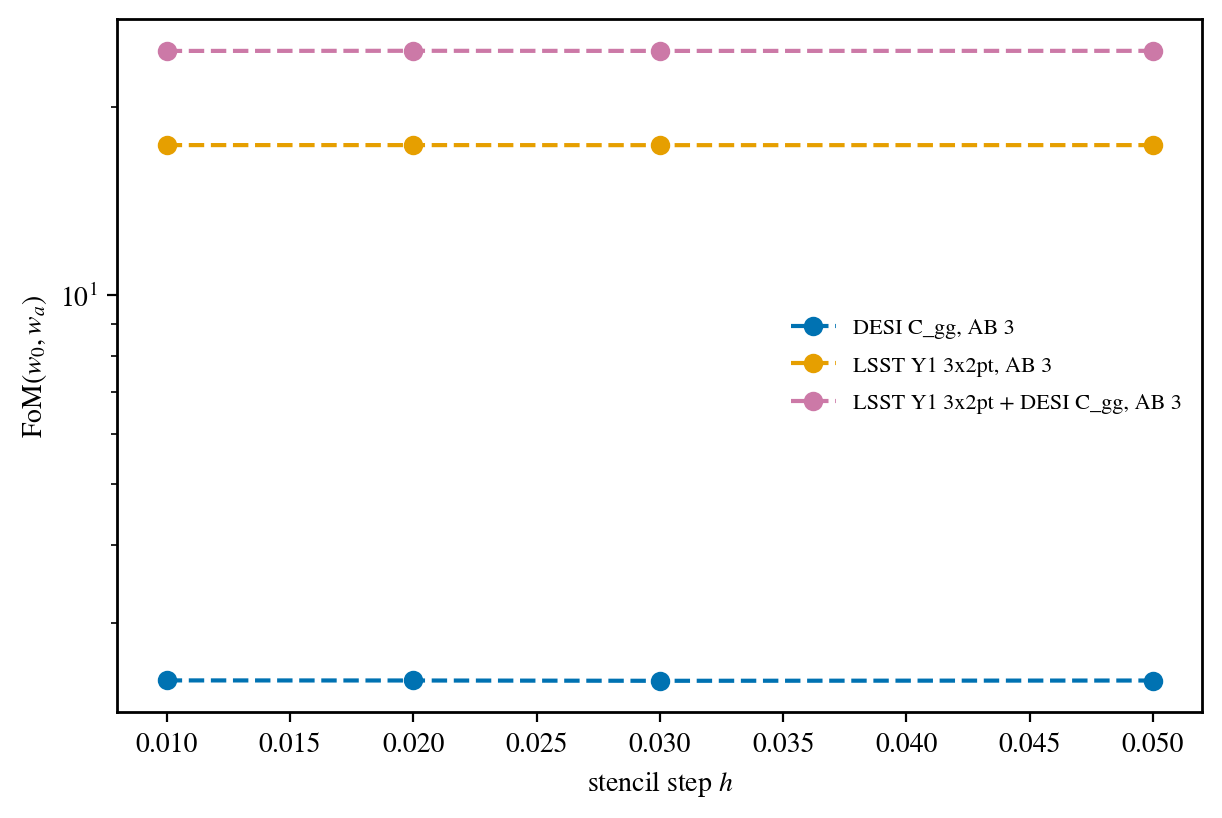

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.5))
styles = dict(zip(ACCURACY_BOOSTS, ['--', '-', ':', '-.']))
# colorblind-safe colors (Okabe-Ito, without its green)
colors = dict(zip(probes(H_MAIN), ['#0072B2', '#E69F00', '#CC79A7']))
for boost in ACCURACY_BOOSTS:
    for label in probes(H_MAIN):
        fom = [stability.loc[(label, boost, h), 'FoM(w0, wa)'] for h in H_SCAN]
        ax.plot(H_SCAN, fom, marker='o', ls=styles[boost], color=colors[label],
                label=f'{label}, AB {boost:g}')
ax.set_xlabel(r'stencil step $h$')
ax.set_ylabel(r'FoM$(w_0, w_a)$')
ax.set_yscale('log')
ax.legend(fontsize=8, frameon=False)
plt.show()

## 6. Forecast contours

`cosmo_block` marginalizes the nuisances out of a Fisher matrix: the cosmology block of
$F^{-1}$ is the marginalized covariance, and its inverse is the Fisher matrix of the
seven cosmological parameters alone. `cnu.plot_Fisher` draws Gaussian samples of each
and hands them to getdist.

Removed no burn in
Removed no burn in
Removed no burn in


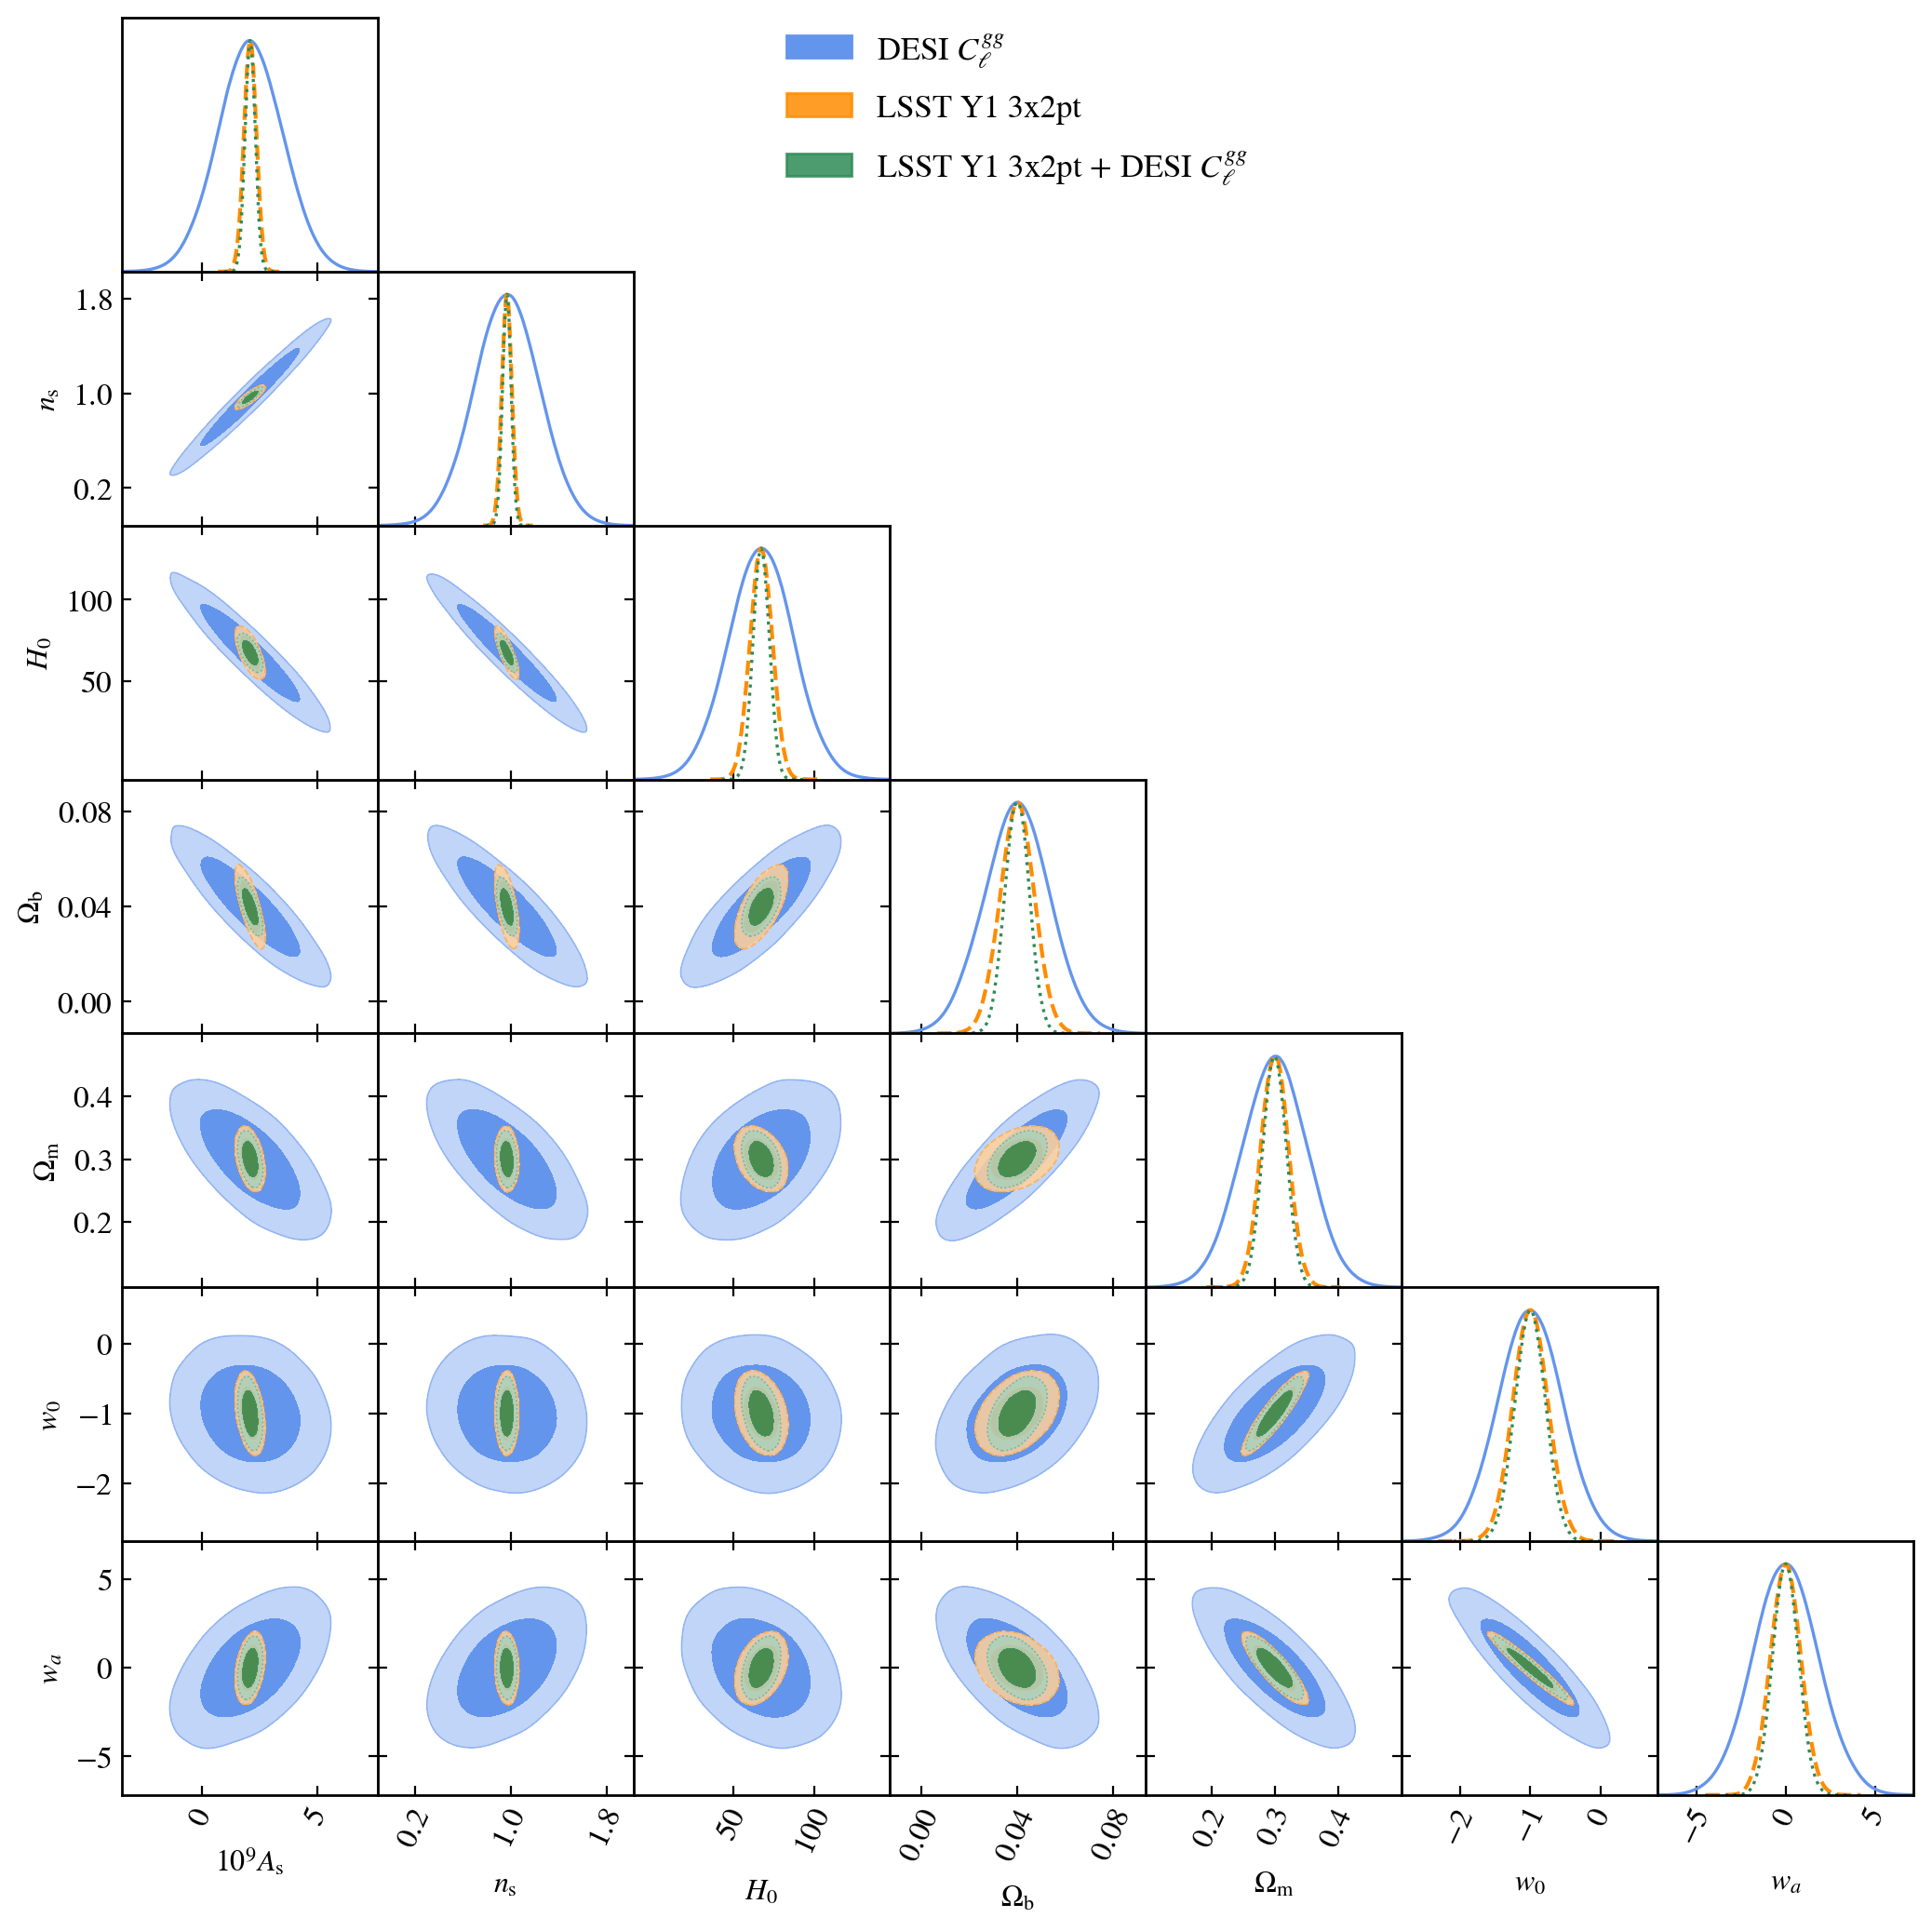

In [10]:
def cosmo_block(F, names):
    '''The Fisher matrix of COSMO with every other parameter marginalized.'''
    C = np.linalg.inv(0.5*(F + F.T))
    idx = [names.index(p) for p in COSMO]
    return np.linalg.inv(C[np.ix_(idx, idx)])


forecasts = probes(H_MAIN)
g = cnu.plot_Fisher(F=[cosmo_block(F, names) for F, names in forecasts.values()],
                    mu=desi['fiducial'][:len(COSMO)], names=COSMO,
                    labels=COSMO_LABELS, filled=True,
                    chain_names=[probe_label(p) for p in forecasts])

## 7. Fisher biases: FKEM against SVD, Limber against non-Limber

Fit the reference model to data generated by an alternative model. To linear order in
$\delta = m_\mathrm{alt} - m_\mathrm{ref}$, the best fit moves by

$$\delta p = F^{-1} B, \qquad B = D^T C^{-1} \delta$$

(Huterer et al. 2006; Amara & Refregier 2008), with $D$ the derivatives of the reference
model. The nuisance parameters are part of $F$: the biases and velocity dispersions
absorb what they can of $\delta$, and the shift left in each cosmological parameter is
the marginalized one. The tables give $\delta p/\sigma$, the shift in units of the
marginalized error. The linear order holds while the shifts stay well below one
$\sigma$; a larger value says the alternative would be detected, and its size is only
indicative.

In LSST Y1 3x2pt + DESI $C_\ell^{gg}$ the numerators of the two blocks add, as
their information does: an alternative applied to DESI alone shifts the joint fit
through the DESI block only.

The tables of the next cell are the $\Delta z = 0.2$ forecast, whose cache of
section 3 also carries the LSST alternatives; the two cells after them repeat the
two DESI alternatives on every layout.

In [11]:
def bias_in_sigma(F, names, shifts):
    '''delta_p/sigma of COSMO for the summed numerators of `shifts`.'''
    shift = fm.fisher_bias(F, names, *shifts)
    sigma = fm.marginalized_sigma(F, names, COSMO)
    return {p: shift[p]/sigma[p] for p in COSMO}


def bias_tables(h):
    '''{probe: DataFrame of delta_p/sigma and delta chi2} at step h.'''
    F_joint, names_joint = joint_fisher(h)
    cases = {
        DESI_PROBE: (desi['F'][h], desi['names'],
                              {label: [('desi', label)] for label in DESI_ALTERNATIVES}),
        LSST_PROBE: (lsst['F'][h], lsst['names'],
                          {label: [('lsst', label)] for label in LSST_ALTERNATIVES}),
        JOINT_PROBE: (F_joint, names_joint, {
            'DESI FKEM, cap 550': [('desi', 'FKEM, cap 550')],
            'DESI Limber': [('desi', 'Limber')],
            'LSST SVD engine': [('lsst', 'SVD engine')],
            'Limber in both': [('desi', 'Limber'), ('lsst', 'Limber')]}),
    }
    tables = {}
    for probe, (F, names, alternatives) in cases.items():
        rows = {}
        for label, parts in alternatives.items():
            shifts = [(results[block]['B'][h][alt], results[block]['names'])
                      for block, alt in parts]
            rows[label] = {**bias_in_sigma(F, names, shifts),
                           'delta chi2': sum(results[block]['dchi2'][alt]
                                             for block, alt in parts)}
        tables[probe] = pd.DataFrame(rows).T
    return tables


biases = bias_tables(H_MAIN)
for probe, frame in biases.items():
    print(f'\n{probe}: delta_p / sigma at h = {H_MAIN}')
    display(frame)


DESI C_gg: delta_p / sigma at h = 0.02


,As_1e9,ns,H0,omegab,omegam,w0,wa,delta chi2
"FKEM, cap 550",0.001671,0.002451,0.003175,-0.006603,-0.01509,-0.007165,0.00433,0.03933
Limber,1.979,3.184,-2.844,-2.872,-2.366,-0.6329,1.55,84.9



LSST Y1 3x2pt: delta_p / sigma at h = 0.02


,As_1e9,ns,H0,omegab,omegam,w0,wa,delta chi2
SVD engine,-0.0001273,0.0009722,-0.00242,-0.001006,0.00235,0.001926,-0.00233,0.0001386
Limber,-0.4048,0.2673,-0.2471,-0.2042,0.294,0.1167,-0.3129,11.18



LSST Y1 3x2pt + DESI C_gg: delta_p / sigma at h = 0.02


,As_1e9,ns,H0,omegab,omegam,w0,wa,delta chi2
"DESI FKEM, cap 550",-0.001238,-0.005518,0.009428,-0.0009167,-0.008684,-0.004453,0.005338,0.03933
DESI Limber,-0.7467,0.6232,-0.8253,-0.2827,0.8251,0.5611,-1.009,84.9
LSST SVD engine,-0.0005559,7.499e-05,-0.001468,-0.0002296,0.001803,0.001568,-0.001782,0.0001386
Limber in both,-0.9115,0.7185,-0.887,-0.4279,0.8538,0.51,-1.039,96.08


### The DESI alternatives on every layout

The comparison extends to the other three layouts. Each layout's two DESI
alternatives (FKEM with the cap at $\ell = 550$; Limber) are evaluated once at the
fiducial point with the layout's own settings (`LAYOUT_FISHER_OVERRIDES`, accuracy
boost 1), so each alternative vector is compared with the layout's own reference
vector. The vectors are cached in
`chains/EXAMPLE_EVALUATE_FISHER_ALTERNATIVES.pkl`; without the cache a first run
takes about 4 + 4 min ($\Delta d_\mathrm{com} = 62$ Mpc), 8 + 8 min ($\Delta z = 0.02$) and 1 + 1 min
($\Delta z = 0.05$) on a laptop (measured: 264, 229, 502, 480, 52 and 44 s).

The numerator $B = D^T C^{-1} \delta$ is built from the layout's cached derivatives
and its covariance file, masked and scaled to 12,300 deg², the construction
`refresh_fisher` uses for every probe of section 3.

The $\Delta\chi^2 = \delta^T C^{-1} \delta$ of each alternative against the
reference model:

| Layout | FKEM, cap 550 | Limber |
| --- | ---: | ---: |
| $\Delta d_\mathrm{com} = 62$ Mpc | 19.6 | 6540 |
| $\Delta z = 0.02$ | 31.3 | $1.46 \times 10^4$ |
| $\Delta z = 0.05$ | 1.50 | 1296 |
| $\Delta z = 0.2$ | 0.0393 | 84.9 |

These are the comparisons the data-vector tests make
(`tests/data_vector/test_nonlimber_fkem_fair.py` and `test_nonlimber_gg.py`),
here with the covariance files of `data/` moved to the common 12,300 deg².

In [12]:
# Fisher biases on every DESI layout. Each layout's alternative vectors
# (DESI_ALTERNATIVES at the layout's own likelihood overrides) are evaluated
# once at the fiducial and cached; B = D^T C^-1 (m_alt - m_ref) then comes
# from the layout's cached derivatives and its covariance file. Delta z = 0.2
# reuses section 3's vectors and B.
LAYOUT_DATASETS = {
    'Delta d_com = 62 Mpc': 'lssty1xdesi_desi_dr3',
    'Delta z = 0.02': 'lssty1xdesi_desi_dr1_dz0p02',
    'Delta z = 0.05': 'lssty1xdesi_desi_dr1_dz0p05',
    'Delta z = 0.2': 'lssty1xdesi_desi_dr1_dz0p20',
}
ALTERNATIVES_CACHE = (ROOTDIR + '/projects/lssty1xdesi/chains/'
                      'EXAMPLE_EVALUATE_FISHER_ALTERNATIVES.pkl')
RECOMPUTE_ALTERNATIVES = False


def layout_covariance(key):
    '''The covariance of one DESI layout as a dense matrix, with its layout.

    Arguments:
      key = a LAYOUT_DATASETS key.

    Returns:
      dict: 'C' (n x n covariance of the full vector), 'mask' (bool, n),
      'bins' and 'pairs' (rows of the bin table and the cross-pair list),
      'ells' (the band centers) and 'n_ee' (the length of the masked EE
      block in front of the clustering spectra).
    '''
    stem = LAYOUT_DATASETS[key]
    bins = read_rows(DATA_DIR + stem + '_bins.txt')
    pairs = read_rows(DATA_DIR + stem + '_pairs.txt')
    ells = np.loadtxt(DATA_DIR + dataset_entry(stem, 'ell_file')).ravel()
    n = len(layout_desi[key]['m_ref'])
    C, mask = read_covariance(stem, n)
    n_ee = n - (len(bins) + len(pairs))*len(ells)
    return {'C': C, 'mask': mask, 'bins': bins, 'pairs': pairs, 'ells': ells,
            'n_ee': n_ee}


def layout_alternatives(key, vectors):
    '''B and delta chi2 of each DESI alternative on one layout.

    Arguments:
      key     = a LAYOUT_DATASETS key.
      vectors = {alternative: m_alt} at the layout's fiducial (unused for
                Delta z = 0.2, which reuses section 3).

    Returns:
      {alternative: {'B': B vector over the layout's parameters,
                     'dchi2': delta^T C^-1 delta}}.
    '''
    out = {}
    if key == 'Delta z = 0.2':
        for label in DESI_ALTERNATIVES:
            out[label] = {'B': desi['B'][H_MAIN][label], 'dchi2': desi['dchi2'][label]}
        return out
    res = layout_desi[key]
    cov = layout_covariance(key)
    kept = np.where(cov['mask'])[0]
    inv_kept = np.linalg.inv(cov['C'][np.ix_(kept, kept)])*AREA_DEG2/DESI_COV_AREA_DEG2
    D = np.array(res['D'][H_MAIN])
    for label in DESI_ALTERNATIVES:
        delta = (np.array(vectors[label]) - np.array(res['m_ref']))[kept]
        out[label] = {'B': D[kept].T @ (inv_kept @ delta),
                      'dchi2': float(delta @ inv_kept @ delta)}
    return out


# the alternative vectors of the three computed layouts (one model build
# and one evaluation per alternative; the compiled interface holds one
# model at a time, so each is built, evaluated and released in turn). The
# cache stores the fingerprint of each layout's reference model
# (fm.settings_fingerprint), so an edited yaml invalidates it.
ALTERNATIVE_FINGERPRINTS = {}
for key in LAYOUT_FISHER_OVERRIDES:
    ALTERNATIVE_FINGERPRINTS[key] = layout_settings(key)['fingerprint']
if RECOMPUTE_ALTERNATIVES or not os.path.exists(ALTERNATIVES_CACHE):
    alternative_vectors = {}
    for key in LAYOUT_FISHER_OVERRIDES:
        alternative_vectors[key] = {}
        for label, overrides in DESI_ALTERNATIVES.items():
            start = time.time()
            alt = fm.ModelFisher(
                LAYOUTS[key]['yaml'], COSMO,
                likelihood_overrides={**LAYOUT_FISHER_OVERRIDES[key], **overrides},
                invcov_scale=AREA_DEG2/DESI_COV_AREA_DEG2,
                accuracy_boost=LAYOUT_ACCURACY_BOOST,
                camb_overrides=LAYOUT_FISHER_CAMB)
            alternative_vectors[key][label] = alt.dv()
            del alt
            print(f'{key}, {label}: {time.time() - start:.0f} s', flush=True)
    with open(ALTERNATIVES_CACHE, 'wb') as f:
        pickle.dump({'vectors': alternative_vectors,
                     'alternatives': DESI_ALTERNATIVES,
                     'overrides': LAYOUT_FISHER_OVERRIDES,
                     'camb': LAYOUT_FISHER_CAMB,
                     'accuracy_boost': LAYOUT_ACCURACY_BOOST,
                     'tier': DERIVATIVE_TIER,
                     'fingerprints': ALTERNATIVE_FINGERPRINTS}, f)
else:
    with open(ALTERNATIVES_CACHE, 'rb') as f:
        cached = pickle.load(f)
    settings = {'alternatives': DESI_ALTERNATIVES,
                'overrides': LAYOUT_FISHER_OVERRIDES,
                'camb': LAYOUT_FISHER_CAMB,
                'accuracy_boost': LAYOUT_ACCURACY_BOOST,
                'tier': DERIVATIVE_TIER,
                'fingerprints': ALTERNATIVE_FINGERPRINTS}
    for name, value in settings.items():
        if cached.get(name) != value:
            raise RuntimeError(f'{ALTERNATIVES_CACHE} holds {name} = '
                               f'{cached.get(name)}, but this notebook asks for '
                               f'{value}: set RECOMPUTE_ALTERNATIVES = True')
    alternative_vectors = cached['vectors']

layout_alts = {}
for key in LAYOUT_DATASETS:
    layout_alts[key] = layout_alternatives(key, alternative_vectors.get(key))

layout_bias = {}
for key in LAYOUT_DATASETS:
    for probe, (F, names) in layout_probes(key).items():
        for label in DESI_ALTERNATIVES:
            shift = [(layout_alts[key][label]['B'], layout_desi[key]['names'])]
            layout_bias[(probe, label, key)] = bias_in_sigma(F, names, shift)

dchi2_table = {}
for key in LAYOUT_DATASETS:
    row = {}
    for label in DESI_ALTERNATIVES:
        row[label] = layout_alts[key][label]['dchi2']
    dchi2_table[key] = row
print('delta chi2 of each DESI alternative against the reference model:')
display(pd.DataFrame(dchi2_table).T)
print('delta_p/sigma of every layout (the bars of the figures below):')
display(pd.DataFrame(layout_bias).T)

delta chi2 of each DESI alternative against the reference model:


,"FKEM, cap 550",Limber
Delta d_com = 62 Mpc,19.63,6540
Delta z = 0.02,31.33,1.457e+04
Delta z = 0.05,1.495,1296
Delta z = 0.2,0.03933,84.9


delta_p/sigma of every layout (the bars of the figures below):


As_1e9  \
DESI C_gg                 FKEM, cap 550 Delta d_com = 62 Mpc    0.1031   
                          Limber        Delta d_com = 62 Mpc   -0.3517   
LSST Y1 3x2pt + DESI C_gg FKEM, cap 550 Delta d_com = 62 Mpc   -0.2711   
                          Limber        Delta d_com = 62 Mpc    0.1068   
DESI C_gg                 FKEM, cap 550 Delta z = 0.02        0.008979   
                          Limber        Delta z = 0.02           10.65   
LSST Y1 3x2pt + DESI C_gg FKEM, cap 550 Delta z = 0.02         -0.2842   
                          Limber        Delta z = 0.02           1.508   
DESI C_gg                 FKEM, cap 550 Delta z = 0.05        -0.07197   
                          Limber        Delta z = 0.05            4.18   
LSST Y1 3x2pt + DESI C_gg FKEM, cap 550 Delta z = 0.05        -0.07968   
                          Limber        Delta z = 0.05          -3.145   
DESI C_gg                 FKEM, cap 550 Delta z = 0.2         0.001671   
                          Limber        Delta z = 0.2            1.979   
LSST Y1 3x2pt + DESI C_gg FKEM, cap 550 Delta z = 0.2        -0.001238   
                          Limber        Delta z = 0.2          -0.7467   

                                                                    ns  \
DESI C_gg                 FKEM, cap 550 Delta d_com = 62 Mpc    0.1283   
                          Limber        Delta d_com = 62 Mpc     3.233   
LSST Y1 3x2pt + DESI C_gg FKEM, cap 550 Delta d_com = 62 Mpc   -0.3555   
                          Limber        Delta d_com = 62 Mpc     4.576   
DESI C_gg                 FKEM, cap 550 Delta z = 0.02        0.008919   
                          Limber        Delta z = 0.02           17.12   
LSST Y1 3x2pt + DESI C_gg FKEM, cap 550 Delta z = 0.02         -0.4388   
                          Limber        Delta z = 0.02           13.14   
DESI C_gg                 FKEM, cap 550 Delta z = 0.05        -0.06686   
                          Limber        Delta z = 0.05           6.754   
LSST Y1 3x2pt + DESI C_gg FKEM, cap 550 Delta z = 0.05         -0.1318   
                          Limber        Delta z = 0.05          0.1504   
DESI C_gg                 FKEM, cap 550 Delta z = 0.2         0.002451   
                          Limber        Delta z = 0.2            3.184   
LSST Y1 3x2pt + DESI C_gg FKEM, cap 550 Delta z = 0.2        -0.005518   
                          Limber        Delta z = 0.2           0.6232   

                                                                   H0  \
DESI C_gg                 FKEM, cap 550 Delta d_com = 62 Mpc -0.00514   
                          Limber        Delta d_com = 62 Mpc   -3.376   
LSST Y1 3x2pt + DESI C_gg FKEM, cap 550 Delta d_com = 62 Mpc   0.4924   
                          Limber        Delta d_com = 62 Mpc   -5.414   
DESI C_gg                 FKEM, cap 550 Delta z = 0.02         0.1625   
                          Limber        Delta z = 0.02         -17.83   
LSST Y1 3x2pt + DESI C_gg FKEM, cap 550 Delta z = 0.02          0.647   
                          Limber        Delta z = 0.02         -14.42   
DESI C_gg                 FKEM, cap 550 Delta z = 0.05         0.0703   
                          Limber        Delta z = 0.05          -6.48   
LSST Y1 3x2pt + DESI C_gg FKEM, cap 550 Delta z = 0.05         0.1096   
                          Limber        Delta z = 0.05         -1.569   
DESI C_gg                 FKEM, cap 550 Delta z = 0.2        0.003175   
                          Limber        Delta z = 0.2          -2.844   
LSST Y1 3x2pt + DESI C_gg FKEM, cap 550 Delta z = 0.2        0.009428   
                          Limber        Delta z = 0.2         -0.8253   

                                                                 omegab  \
DESI C_gg                 FKEM, cap 550 Delta d_com = 62 Mpc    0.02966   
                          Limber        Delta d_com = 62 Mpc     -8.489   
LSST Y1 3x2pt + DESI C_gg FKEM, cap 550 Delta d_com = 62 Mpc     0.4035   
    

The four figures below put the layouts side by side, one figure per forecast and
DESI alternative: DESI $C_\ell^{gg}$ alone and then LSST Y1 3x2pt + DESI
$C_\ell^{gg}$ with FKEM at the cap of 550, followed by the same pair with Limber.
Each figure gives one bar per layout and parameter ($\Delta d_\mathrm{com} = 62$ Mpc blue, $\Delta z = 0.02$
orange, $\Delta z = 0.05$ reddish purple, $\Delta z = 0.2$ sky blue, in the layouts' order,
each with its own hatch), dashed lines at
$\pm 1\sigma$, and a legend with each layout's $\Delta\chi^2$. The two Limber
figures use a symmetric-log axis, linear within $\pm 1$.

**FKEM, cap 550.** On $\Delta z = 0.2$ every shift stays below $0.01\sigma$; on
$\Delta z = 0.05$ the shifts reach $0.07\sigma$ alone and $0.13\sigma$ in the
combination. The thin-bin layouts are biased by a sizable fraction of the error:
the $\Delta d_\mathrm{com} = 62$ Mpc layout reaches $0.18\sigma$ alone (in $w_a$) and $0.49\sigma$ in the combination (in
$H_0$, with $0.40\sigma$ in $\Omega_b$), and $\Delta z = 0.02$ reaches
$0.33\sigma$ alone ($w_a$, with $0.16\sigma$ in $H_0$) and $0.65\sigma$ in the
combination ($H_0$, with $0.44\sigma$ in $n_s$, $0.43\sigma$ in $\Omega_b$ and
$0.39\sigma$ in $w_a$). FKEM projects the linear power
exactly but adds the nonlinear correction in Limber, and that treatment is
harmless on wide bins while it biases the thin-bin layouts. The shifts grow in
units of $\sigma$ in the combination because LSST shrinks the errors in directions
where the DESI-induced numerator $B$ remains. The reference - the low-rank SVD
engine, which projects the full nonlinear $P_{gg}$ non-Limber - is the more
complete model.

**Limber.** On $\Delta z = 0.2$ the shifts of DESI $C_\ell^{gg}$ alone range from
$0.6\sigma$ to $3.2\sigma$; on the thin layouts they reach $8.5\sigma$
($\Delta d_\mathrm{com} = 62$ Mpc) and $19\sigma$ ($\Delta z = 0.02$) - for example
$12\sigma$ in $\Omega_m$ on $\Delta z = 0.02$ alone. The table printed under the
$\Delta\chi^2$ table lists every bar. Shifts this large are far outside the linear regime of
$\delta p = F^{-1} B$, so their size is only indicative; the conclusion is that
Limber is excluded for DESI clustering on every layout.

One caveat: the thin-layout derivatives use the single step $h = 0.02$, so these
shifts carry no step scan. The next subsection scans the step on
$\Delta z = 0.2$.

In [13]:
def draw_bias_bars(probe, label):
    '''Draw delta_p/sigma of COSMO for one forecast and one DESI alternative.

    One bar per layout and parameter, the four layouts side by side, each
    with its color and its hatch (LAYOUT_HATCHES); the dashed lines mark +-1
    sigma. A Limber figure uses a symmetric log axis,
    linear within +-1 sigma.

    Arguments:
      probe = DESI_PROBE or JOINT_PROBE.
      label = a key of DESI_ALTERNATIVES.

    Side effects: draws one figure.
    '''
    x = np.arange(len(COSMO))
    width = 0.8/len(LAYOUT_DATASETS)
    fig, ax = plt.subplots(figsize=(9, 4.8))
    for k, key in enumerate(LAYOUT_DATASETS):
        shifts = layout_bias[(probe, label, key)]
        values = []
        for p in COSMO:
            values.append(shifts[p])
        ax.bar(x + (k - (len(LAYOUT_DATASETS) - 1)/2)*width, values,
               width=width, color=LAYOUT_COLORS[key], hatch=LAYOUT_HATCHES[key],
               edgecolor='0.15', linewidth=0.4,
               label=(f'{LAYOUT_LABELS[key]} ($\\Delta\\chi^2$ = '
                      f'{layout_alts[key][label]["dchi2"]:.3g})'))
    ax.axhline(0.0, color='black', lw=0.8)
    for level in (-1.0, 1.0):
        ax.axhline(level, color='gray', lw=0.6, ls='--')
    if label == 'Limber':
        ax.set_yscale('symlog', linthresh=1.0)
    ax.set_xticks(x)
    ax.set_xticklabels(['$%s$' % s for s in COSMO_LABELS])
    ax.set_title(f'{probe_label(probe)}; DESI alternative: {label}')
    ax.set_ylabel(r'$\delta p/\sigma$')
    ax.legend(fontsize=8.5, frameon=False)
    plt.show()

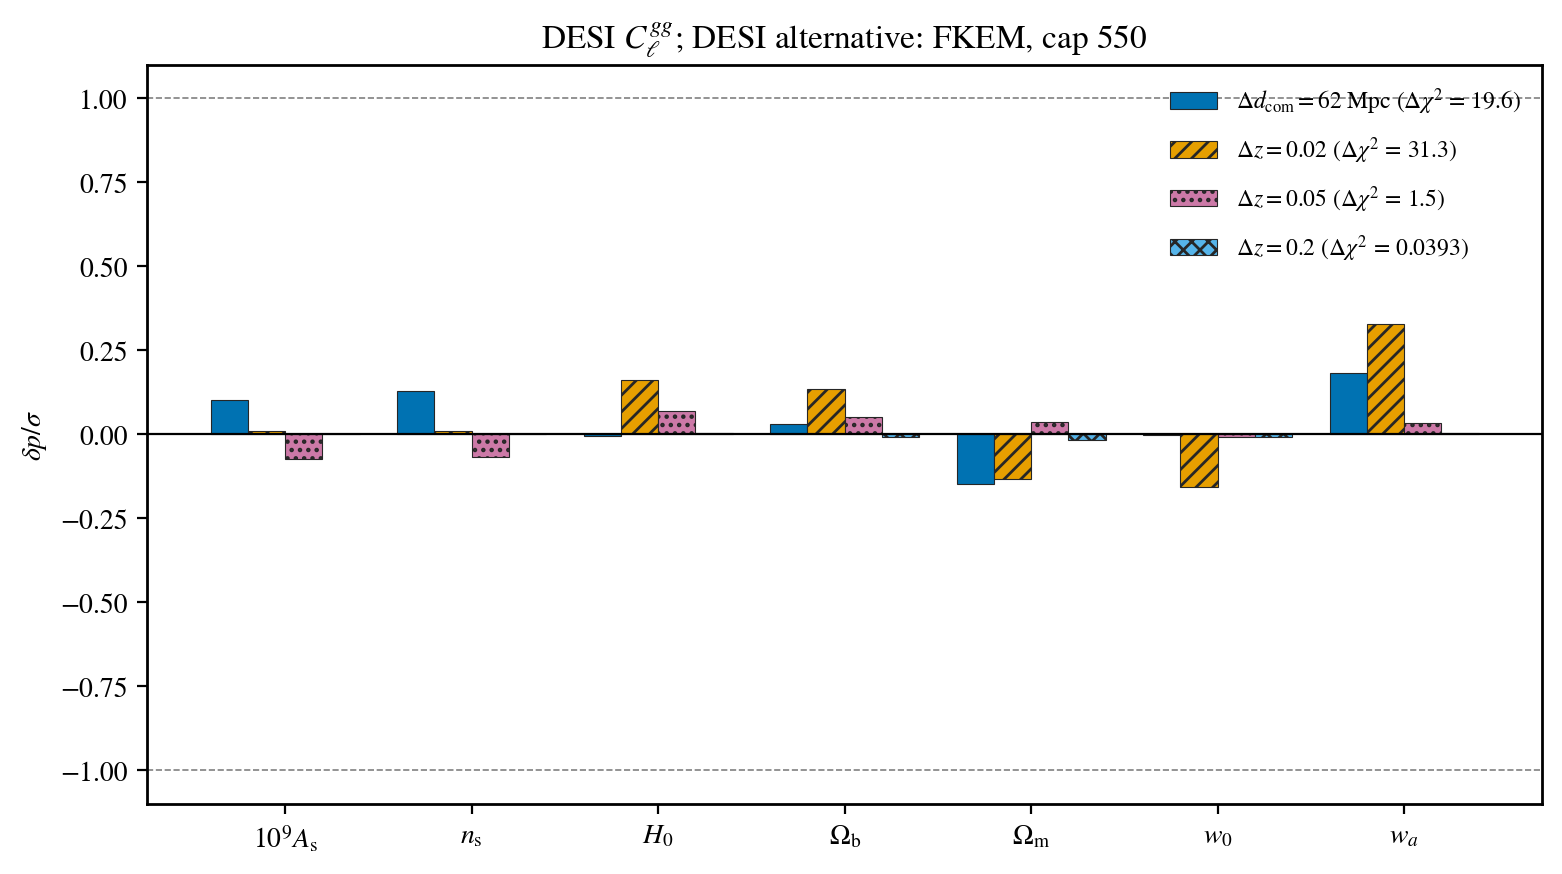

In [14]:
draw_bias_bars(DESI_PROBE, 'FKEM, cap 550')

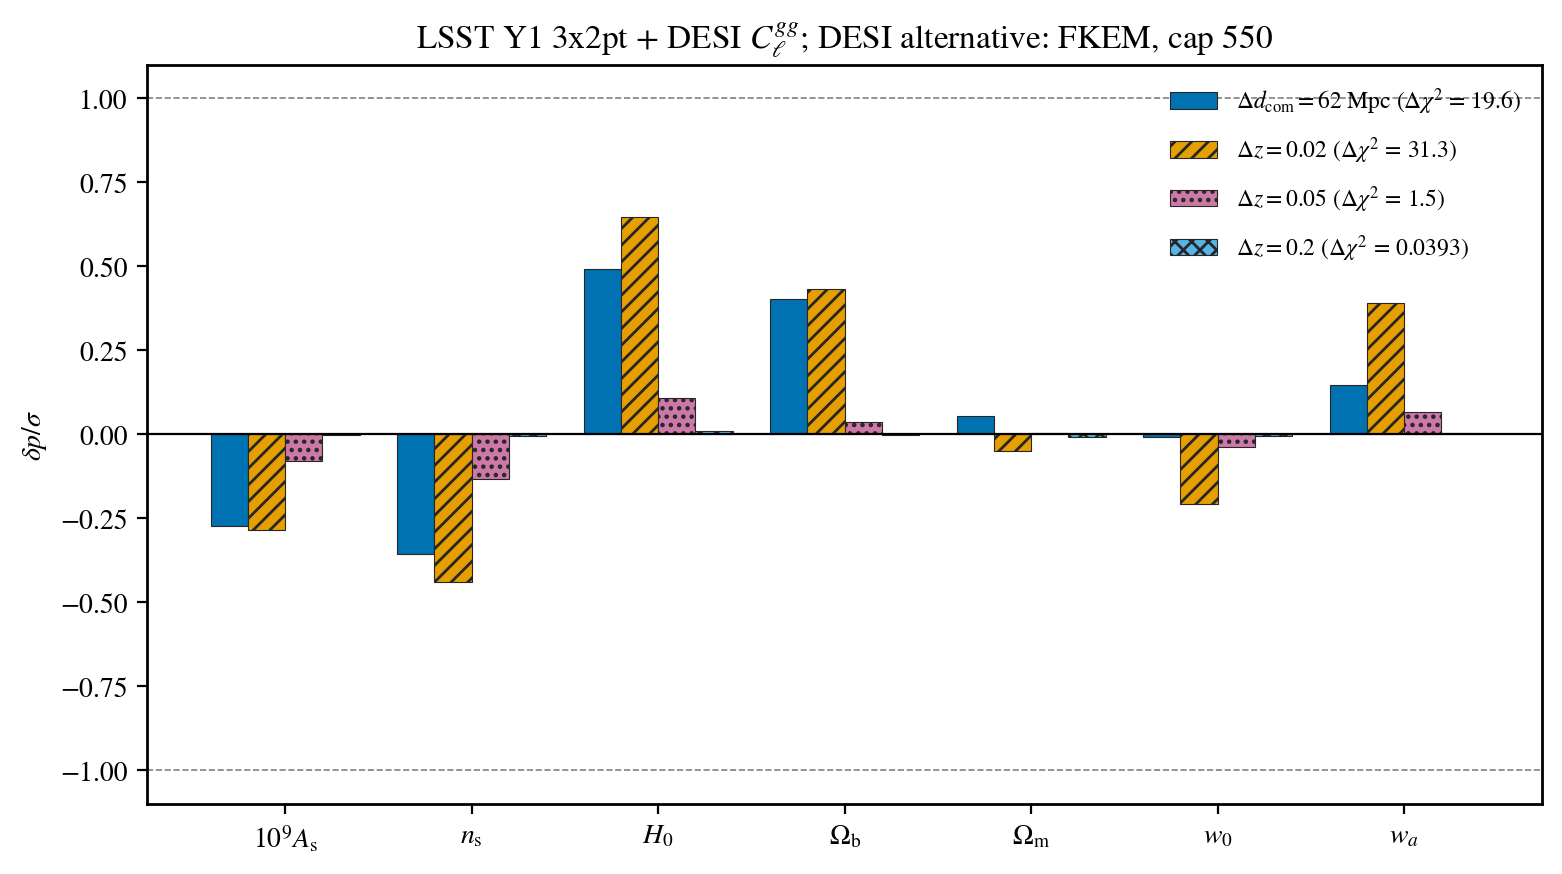

In [15]:
draw_bias_bars(JOINT_PROBE, 'FKEM, cap 550')

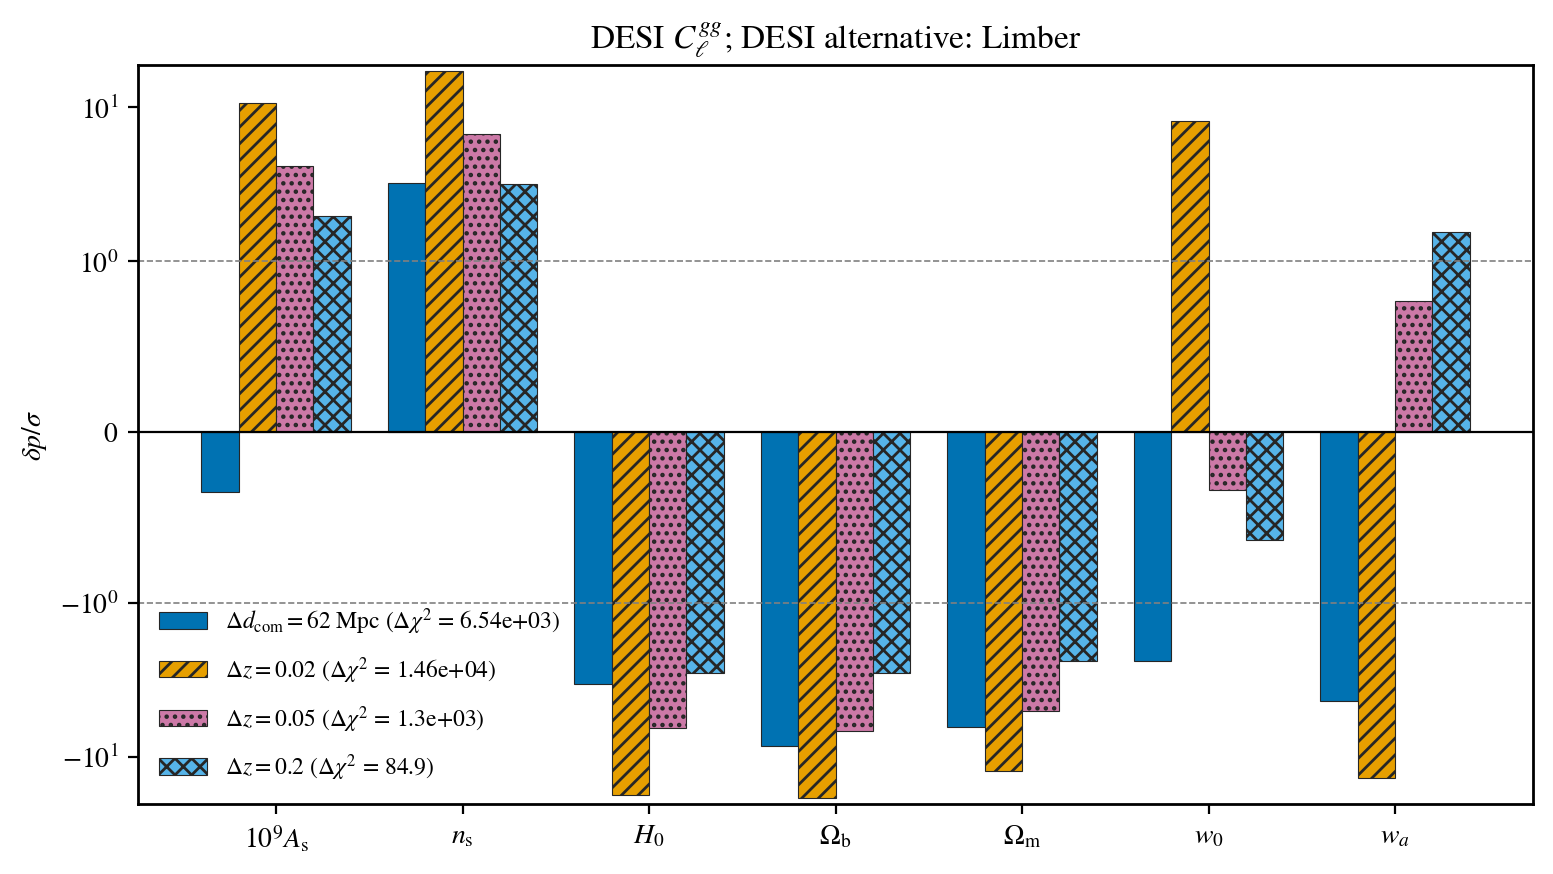

In [16]:
draw_bias_bars(DESI_PROBE, 'Limber')

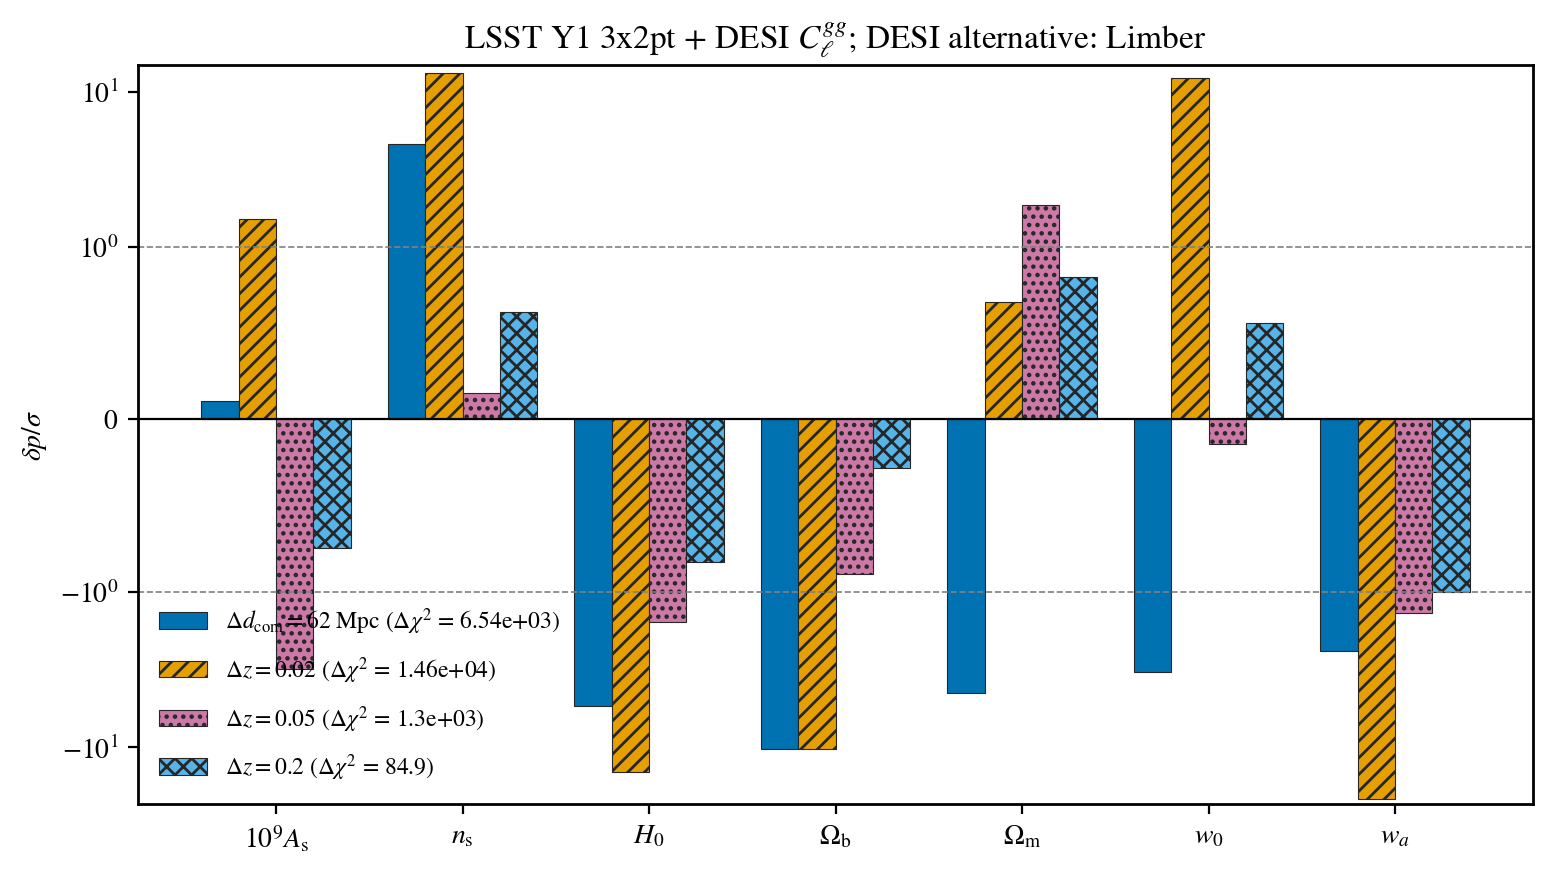

In [17]:
draw_bias_bars(JOINT_PROBE, 'Limber')

### Fisher-bias stability against $h$

The shifts depend on the derivatives too, so they carry the same step dependence as
the errors. The table repeats every $\Delta z = 0.2$ shift at each step of
`H_SCAN` = 0.01, 0.02, 0.03 and 0.05; only this layout has a step scan.

The heatmap below draws the same table. The rows are the (forecast, alternative)
pairs in the order of the section 7 tables, the columns the seven cosmological
parameters, and the color is $\delta p/\sigma$ at `H_MAIN` = 0.02, on a
symmetric-log color scale that is linear within $\pm 0.01$. Each cell's text gives
the value and, below it, the spread (max - min over `H_SCAN`). Every spread is at
most 0.013, against shifts that range from $7.5 \times 10^{-5}$ to 3.2 (the line
printed above the heatmap): the biases are step-independent.

In [18]:
rows = {}
for h in H_SCAN:
    for probe, frame in bias_tables(h).items():
        for label, row in frame.iterrows():
            rows[(probe, label, h)] = row
pd.DataFrame(rows).T.sort_index()

As_1e9        ns  \
DESI C_gg                 FKEM, cap 550      0.01   0.001771  0.002535   
                                             0.02   0.001671  0.002451   
                                             0.03   0.001635  0.002414   
                                             0.05   0.001637  0.002414   
                          Limber             0.01      1.972      3.18   
                                             0.02      1.979     3.184   
                                             0.03      1.981     3.186   
                                             0.05       1.98     3.185   
LSST Y1 3x2pt             Limber             0.01    -0.4056    0.2676   
                                             0.02    -0.4048    0.2673   
                                             0.03    -0.4051    0.2673   
                                             0.05    -0.4049    0.2674   
                          SVD engine         0.01 -0.0001294 0.0009737   
                                             0.02 -0.0001273 0.0009722   
                                             0.03 -0.0001276 0.0009726   
                                             0.05 -0.0001267 0.0009733   
LSST Y1 3x2pt + DESI C_gg DESI FKEM, cap 550 0.01  -0.001204 -0.005522   
                                             0.02  -0.001238 -0.005518   
                                             0.03   -0.00125 -0.005524   
                                             0.05  -0.001243 -0.005522   
                          DESI Limber        0.01     -0.745    0.6237   
                                             0.02    -0.7467    0.6232   
                                             0.03    -0.7456    0.6235   
                                             0.05    -0.7452     0.624   
                          LSST SVD engine    0.01 -0.0005578 7.666e-05   
                                             0.02 -0.0005559 7.499e-05   
                                             0.03 -0.0005563 7.585e-05   
                                             0.05 -0.0005551 7.657e-05   
                          Limber in both     0.01    -0.9106    0.7192   
                                             0.02    -0.9115    0.7185   
                                             0.03    -0.9106    0.7189   
                                             0.05      -0.91    0.7194   

                                                         H0     omegab  \
DESI C_gg                 FKEM, cap 550      0.01  0.003142  -0.006729   
                                             0.02  0.003175  -0.006603   
                                             0.03  0.003204  -0.006551   
                                             0.05  0.003211  -0.006564   
                          Limber             0.01     -2.84     -2.867   
                                             0.02    -2.844     -2.872   
                                             0.03    -2.846     -2.873   
                                             0.05    -2.845     -2.873   
LSST Y1 3x2pt             Limber             0.01   -0.2479    -0.2034   
                                             0.02   -0.2471    -0.2042   
                                             0.03   -0.2473    -0.2039   
                                             0.05    -0.247    -0.2042   
                          SVD engine         0.01 -0.002423  -0.001003   
                                             0.02  -0.00242  -0.001006   
                                             0.03  -0.00242  -0.001005   
                                             0.05 -0.002421  -0.001006   
LSST Y1 3x2pt + DESI C_gg DESI FKEM, cap 550 0.01  0.009467  -0.000953   
                                             0.02  0.009428 -0.0009167   
                                             0.03  0.009422  -0.000901   
                                             0.05  0.009424 -0.0009097   
                          DESI Limber        0.01   -0.82

largest spread over H_SCAN: 0.013; |delta p/sigma| at h = 0.02 from 7.5e-05 to 3.2


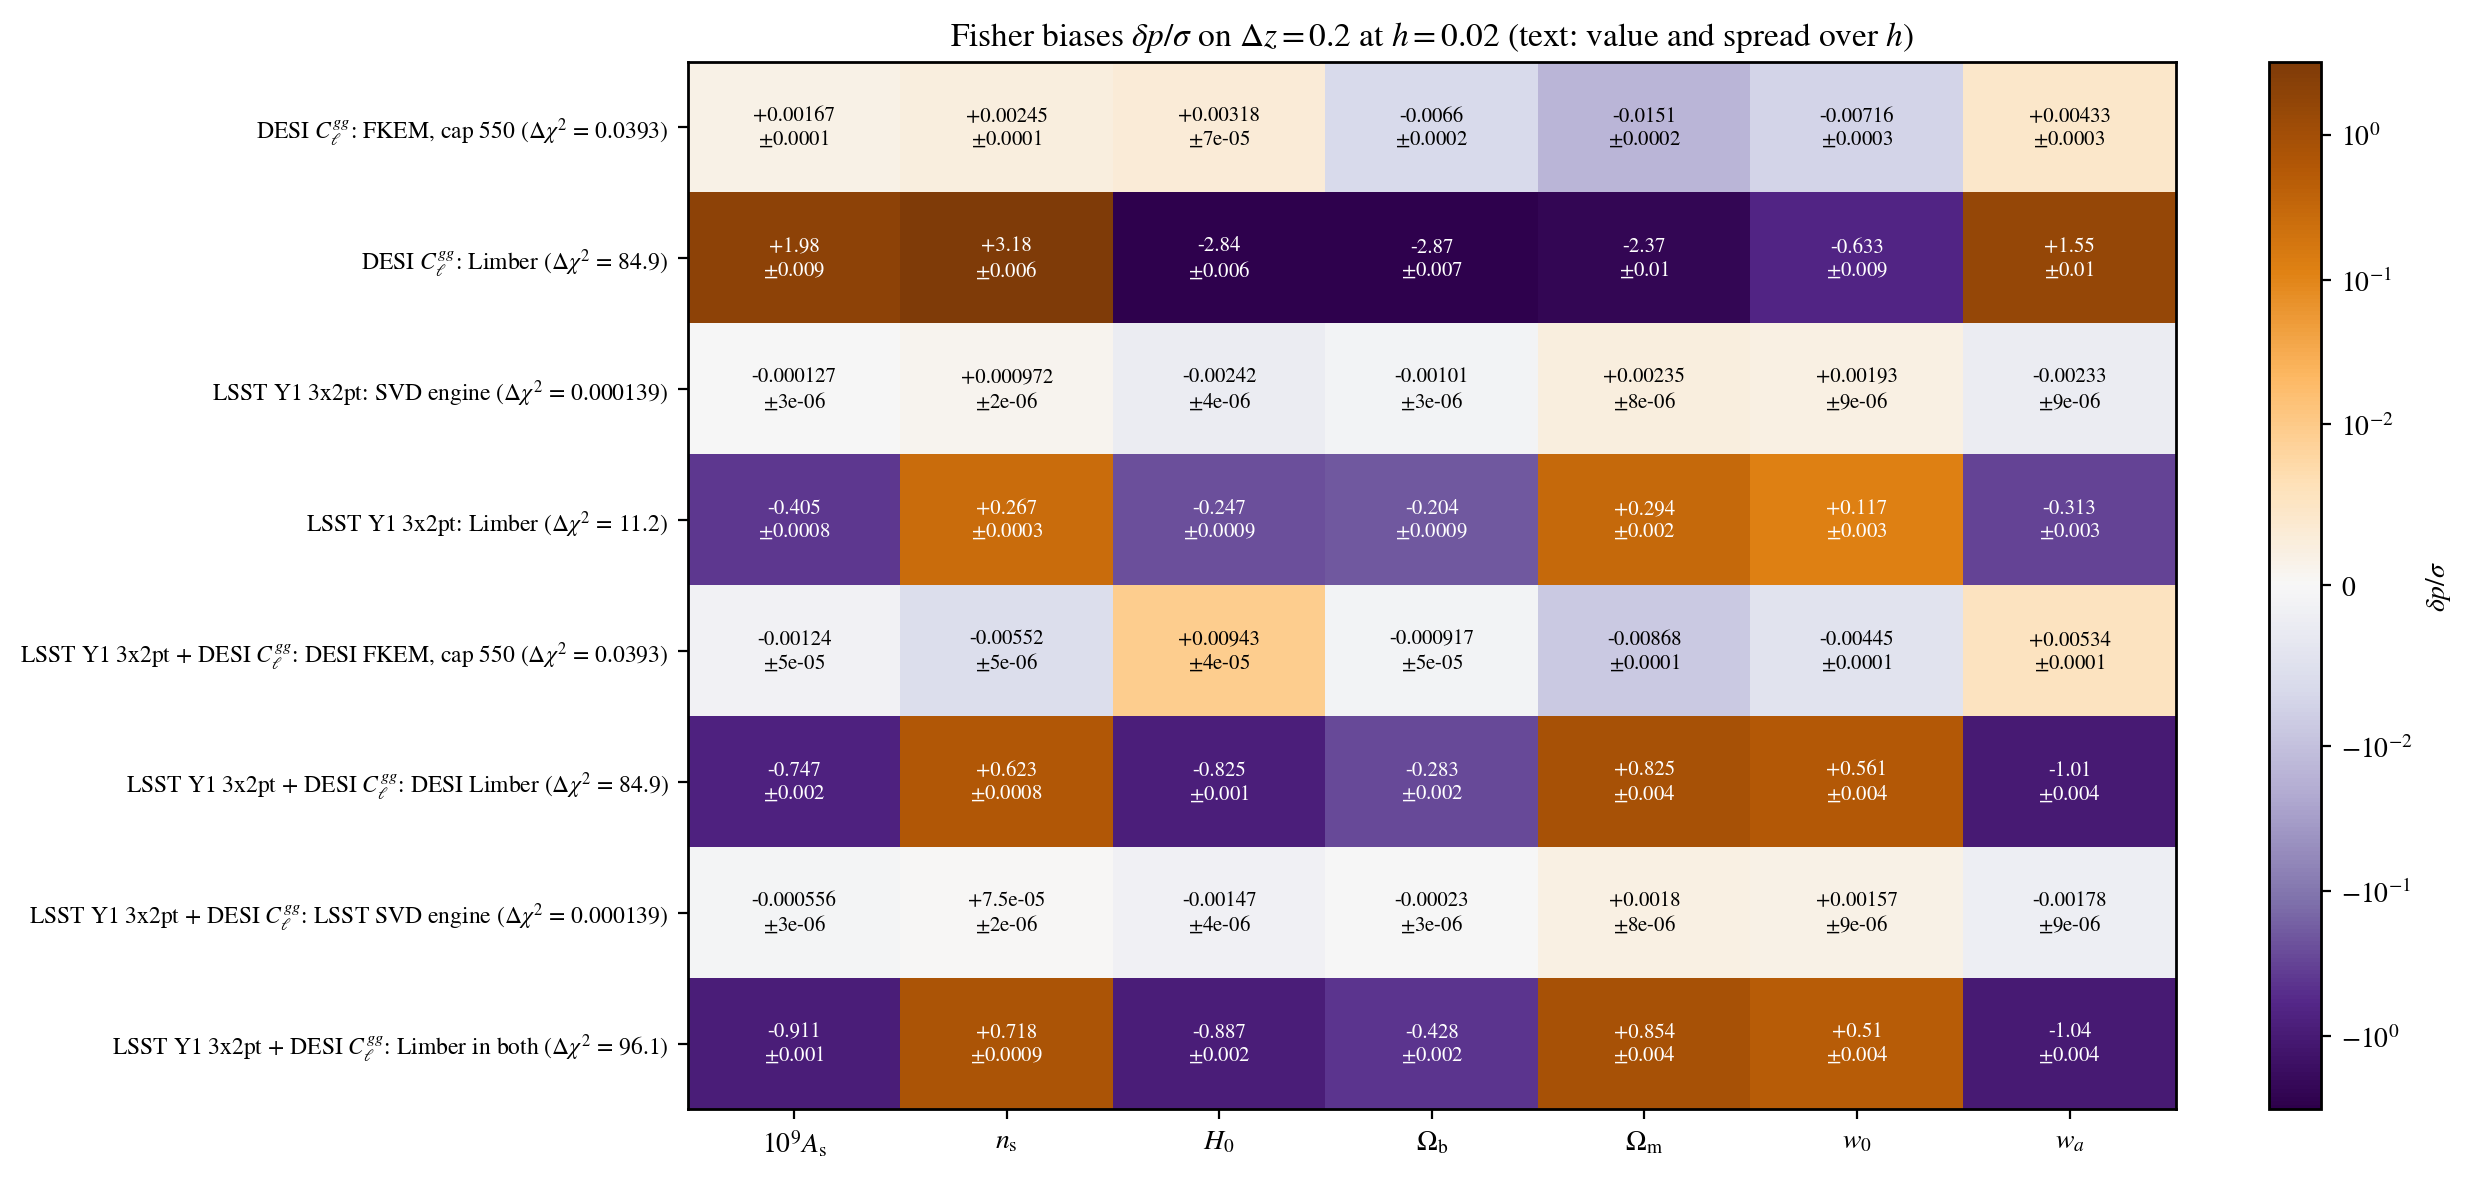

In [19]:
# One picture of the table above (Delta z = 0.2, the layout with the step
# scan): each cell is the shift delta_p/sigma of one parameter (column) for
# one probe and alternative (row) at the step H_MAIN, colored on a
# symmetric log scale; the text gives the value and, below it, the spread
# max - min over the steps of H_SCAN.
from matplotlib.colors import SymLogNorm

stability_bias = pd.DataFrame(rows).T.sort_index()
# rows in the order of the tables of section 7
row_keys = []
for probe, frame in biases.items():
    for label in frame.index:
        row_keys.append((probe, label))
at_main = np.zeros((len(row_keys), len(COSMO)))
spread = np.zeros((len(row_keys), len(COSMO)))
row_labels = []
for r, (probe, label) in enumerate(row_keys):
    for c, p in enumerate(COSMO):
        over_h = []
        for h in H_SCAN:
            over_h.append(stability_bias.loc[(probe, label, h), p])
        at_main[r, c] = stability_bias.loc[(probe, label, H_MAIN), p]
        spread[r, c] = max(over_h) - min(over_h)
    dchi2 = stability_bias.loc[(probe, label, H_MAIN), 'delta chi2']
    row_labels.append(f'{probe_label(probe)}: {label} '
                      f'($\\Delta\\chi^2$ = {dchi2:.3g})')

print(f'largest spread over H_SCAN: {spread.max():.2g}; '
      f'|delta p/sigma| at h = {H_MAIN} from {np.abs(at_main).min():.2g} '
      f'to {np.abs(at_main).max():.2g}')
largest = max(1.0, float(np.abs(at_main).max()))
fig, ax = plt.subplots(figsize=(12, 0.65*len(row_keys) + 1.6))
image = ax.imshow(at_main, cmap='PuOr_r', aspect='auto',
                  norm=SymLogNorm(linthresh=0.01, vmin=-largest, vmax=largest))
for r in range(len(row_keys)):
    for c in range(len(COSMO)):
        shade = image.norm(at_main[r, c])
        color = 'white' if shade < 0.2 or shade > 0.8 else 'black'
        ax.text(c, r, f'{at_main[r, c]:+.3g}\n$\\pm${spread[r, c]:.1g}',
                ha='center', va='center', fontsize=7.5, color=color)
ax.set_xticks(range(len(COSMO)))
ax.set_xticklabels(['$%s$' % s for s in COSMO_LABELS])
ax.set_yticks(range(len(row_keys)))
ax.set_yticklabels(row_labels, fontsize=8.5)
ax.set_title(rf'Fisher biases $\delta p/\sigma$ on $\Delta z = 0.2$ at $h = {H_MAIN}$ '
             r'(text: value and spread over $h$)')
fig.colorbar(image, ax=ax, label=r'$\delta p/\sigma$')
plt.show()

## 8. The amplitude cut against the Fisher forecast

The galaxy power of a lens bin is proportional to $A_s b_i^2$. The flat priors let
$10^9 A_s$ range over $[0.5, 5]$ and every bias amplitude over $[0.8, 4]$, so without
a cut the amplitude ratio $A_s b_i^2/(A_s b_i^2)_\mathrm{fid}$ reaches about 50 for
the ELG groups, whose fiducial bias is 0.84. There a fixed relative numerical error
of the data vector costs many units of $\chi^2$ against the fiducial covariance (the
cost grows as the ratio squared): the N-random-models check of the
[data-vector tests](tests/data_vector/README.md#nmodels_check) fails on every layout
through that corner of the box.

Cutting the boxes at a ratio `AMPLITUDE_CUT` removes that corner, and it can only move
an inference if the data allow points near the cut. This section draws, for every DESI
layout of the project, the cut against that layout's own DESI $C_{gg}$ Fisher
forecast. The triangle shades the excluded region gray and draws the Fisher $1\sigma$
and $2\sigma$ contours (68.3% and 95.4% of a two-dimensional Gaussian) about the
fiducial, every other parameter marginalized:

- an $A_s$ – $b_i$ panel shades bin $i$'s own cut;
- a $b_i$ – $b_j$ panel shades the region either bin excludes at the fiducial $A_s$;
- a diagonal panel shades the part of the box excluded with the other parameters at
  the fiducial, and draws each forecast's marginal Gaussian.

A cut far outside the $2\sigma$ contours removes only prior volume the data already
exclude. The DESI $2\sigma$ contours reach a ratio of 1.65 on $\Delta d_\mathrm{com} = 62$ Mpc, 1.60 on
$\Delta z = 0.02$, 1.93 on $\Delta z = 0.05$ and 3.13 on $\Delta z = 0.2$, so the default
cut of 8 keeps a wide margin on every layout while bounding the amplitude, and with
it the numerical error, of every bin. The value 8 is
the cut shared by all cosmolike projects in this group, and every example yaml carries
it as the cobaya prior `amplitude_cut`. Set `AMPLITUDE_CUT` and rerun the cells to
test another cut.

The Fisher matrices of the four layouts are those of section 4 (`layout_desi`),
at the step `H_MAIN`. Each layout's cells print the numbers its text quotes:
the largest ratio on the $2\sigma$ contour of every $A_s$ - $b_i$ panel, the
marginalized errors of the group biases, and the $2\sigma$ ranges of
$\Omega_m$, $w_0$ and $w_0 + w_a$ with the walls they cross.

In [20]:
def draw_amplitude_cut(key):
    '''Draw the amplitude cut against one layout's DESI C_gg forecast.

    The A_s box comes from the layout's example yaml, the bias boxes from
    its likelihood parameter file (a mapping with one entry per
    parameter); the contours are the DESI C_gg Fisher matrix at H_MAIN.

    Arguments:
      key = a key of LAYOUTS.

    Side effects: draws one figure, titled with the layout, and prints
    the largest amplitude ratio on the 2 sigma contour of every (A_s, b)
    panel and the marginalized errors of the group biases.
    '''
    layout = LAYOUTS[key]
    res = layout_desi[key]
    bias_labels = {}
    for leader, label in zip(layout['bias_leaders'], BIAS_GROUP_LABELS):
        bias_labels[f'DESI_B1_{leader}'] = label
    as_prior = yaml_load_file(layout['yaml'])['params']['As_1e9']['prior']
    bias_params = yaml_load_file(layout['bias_params'])
    boxes = {'As_1e9': (as_prior['min'], as_prior['max'])}
    for name in bias_labels:
        prior = bias_params[name]['prior']
        boxes[name] = (prior['min'], prior['max'])
    # the 2 sigma contour of a pair (delta chi2 = 6.18) in the pair's
    # marginalized 2 x 2 covariance, as the triangle draws it: the
    # fiducial plus sqrt(6.18) times the Cholesky factor applied to the
    # unit circle
    F = np.array(res['F'][H_MAIN])
    names = list(res['names'])
    fiducial = dict(zip(names, res['fiducial']))
    covariance = np.linalg.inv(0.5*(F + F.T))
    angle = np.linspace(0.0, 2.0*np.pi, 2001)
    circle = np.vstack([np.cos(angle), np.sin(angle)])
    ratios = []
    errors = []
    for name in bias_labels:
        rows = [names.index('As_1e9'), names.index(name)]
        cholesky = np.linalg.cholesky(covariance[np.ix_(rows, rows)])
        center = np.array([fiducial['As_1e9'], fiducial[name]])
        contour = center[:, None] + np.sqrt(6.18)*(cholesky @ circle)
        # (A_s/A_s,fid)(b/b_fid)^2 along the contour
        ratio = (contour[0]/center[0])*(contour[1]/center[1])**2
        ratios.append(f'{ratio.max():.3f}')
        errors.append(np.sqrt(covariance[rows[1], rows[1]]))
    print(f'{key}: largest (A_s/A_s,fid)(b/b_fid)^2 on the DESI C_gg 2 sigma '
          'contours, groups ' + ', '.join(BIAS_GROUP_NAMES) + ': '
          + ', '.join(ratios))
    print(f'{key}: marginalized sigma(b) of the group biases from '
          f'{min(errors):.3g} to {max(errors):.3g}')
    labels = dict(bias_labels)
    labels['As_1e9'] = COSMO_LABELS[0]
    fig, axes = cnu.plot_Fisher_amplitude_cut(
        F=[res['F'][H_MAIN]], names=[res['names']],
        fiducial=dict(zip(res['names'], res['fiducial'])),
        amplitude='As_1e9', biases=list(bias_labels), boxes=boxes,
        labels=labels, cut=AMPLITUDE_CUT,
        chain_names=[probe_label(DESI_PROBE)], show=None)
    fig.suptitle(layout['title'], fontsize=15)
    plt.show()

### The cosmological prior walls

The examples' flat prior also has walls in the cosmology: $\Omega_m \in [0.2, 0.5]$,
$w_0 \le -1/3$ (an accelerating universe today), $-3 \le w_0 + w_a \le -0.01$ and
$H_0 \in [55, 91]$ km/s/Mpc. Beyond the $w_0 + w_a = -3$ wall (an early phantom
regime) and at low $\Omega_m$ the numerical error of the data vector grows - the
low-$\Omega_m$ corner is why every likelihood ships `kmax_boltzmann: 20`, as the
[data-vector tests](tests/data_vector/README.md#nmodels_check) record. For each
layout a second triangle draws the Fisher contours of DESI clustering alone and of
LSST Y1 3x2pt + DESI $C_\ell^{gg}$ against the $\Omega_m$, $w_0$ and $w_0 + w_a$
walls. The cells
read the walls from each example yaml, so they redraw whatever prior the yamls hold.

In [21]:
def draw_prior_walls(key):
    '''Draw the cosmological prior walls against one layout's forecasts.

    The walls are the omegam and w0 (`w`) boxes and the w0 + wa (`w0pwa`)
    box of the layout's example yaml; the contours are its DESI C_gg and
    LSST Y1 3x2pt + DESI C_gg Fisher matrices at H_MAIN (layout_probes).

    Arguments:
      key = a key of LAYOUTS.

    Side effects: draws one figure, titled with the layout, and prints
    each forecast's 2 sigma ranges of Omega_m, w0 and w0 + wa with the
    walls they cross.
    '''
    layout = LAYOUTS[key]
    res = layout_desi[key]
    example_params = yaml_load_file(layout['yaml'])['params']
    wall_boxes = {}
    for name, yaml_name in (('omegam', 'omegam'), ('w0', 'w')):
        prior = example_params[yaml_name]['prior']
        wall_boxes[name] = (prior['min'], prior['max'])
    w0pwa_prior = example_params['w0pwa']['prior']
    walls = [({'w0': 1.0, 'wa': 1.0}, w0pwa_prior['min'], w0pwa_prior['max'])]
    forecasts = layout_probes(key)
    wall_labels = [DESI_PROBE, JOINT_PROBE]
    # the extent of a 2 sigma contour (delta chi2 = 6.18) along one
    # direction is the fiducial +- sqrt(6.18) times that direction's
    # marginalized error, so a contour crosses a wall exactly when this
    # range does
    walls_1d = {'Omega_m': (wall_boxes['omegam'][0], wall_boxes['omegam'][1]),
                'w0': (wall_boxes['w0'][0], wall_boxes['w0'][1]),
                'w0 + wa': (w0pwa_prior['min'], w0pwa_prior['max'])}
    fiducial = dict(zip(res['names'], res['fiducial']))
    for label in wall_labels:
        F, names = forecasts[label]
        covariance = np.linalg.inv(0.5*(F + F.T))
        iw0 = names.index('w0')
        iwa = names.index('wa')
        iom = names.index('omegam')
        sigma = {'Omega_m': np.sqrt(covariance[iom, iom]),
                 'w0': np.sqrt(covariance[iw0, iw0]),
                 'w0 + wa': np.sqrt(covariance[iw0, iw0] + covariance[iwa, iwa]
                                    + 2.0*covariance[iw0, iwa])}
        center = {'Omega_m': fiducial['omegam'], 'w0': fiducial['w0'],
                  'w0 + wa': fiducial['w0'] + fiducial['wa']}
        ranges_text = []
        crossed = []
        for name in ('Omega_m', 'w0', 'w0 + wa'):
            low = center[name] - np.sqrt(6.18)*sigma[name]
            high = center[name] + np.sqrt(6.18)*sigma[name]
            ranges_text.append(f'{name} {low:.3g} to {high:.3g}')
            wall_low, wall_high = walls_1d[name]
            if low < wall_low:
                crossed.append(f'{name} = {wall_low:g}')
            if high > wall_high:
                crossed.append(f'{name} = {wall_high:g}')
        if not crossed:
            crossed = ['none']
        print(f'{key}, {label}: 2 sigma ranges ' + ', '.join(ranges_text)
              + '; walls crossed: ' + ', '.join(crossed))
    matrices = []
    name_lists = []
    for label in wall_labels:
        matrices.append(forecasts[label][0])
        name_lists.append(forecasts[label][1])
    fig, axes = cnu.plot_Fisher_prior_walls(
        F=matrices, names=name_lists,
        fiducial=dict(zip(res['names'], res['fiducial'])),
        params=['omegam', 'w0', 'wa'],
        ranges={'omegam': (0.1, 0.6), 'w0': (-3.2, 0.4), 'wa': (-5.0, 5.0)},
        boxes=wall_boxes, walls=walls, labels=dict(zip(COSMO, COSMO_LABELS)),
        chain_names=[probe_label(p) for p in wall_labels], show=None)
    fig.suptitle(layout['title'], fontsize=15)
    plt.show()

### $\Delta d_\mathrm{com} = 62$ Mpc

76 comoving bins about 62 Mpc wide, at the derivative accuracy of
`LAYOUT_FISHER_OVERRIDES`. The matrix is cached in
`chains/EXAMPLE_EVALUATE_LINEAR1_FISHER.pkl`; a first run without the cache builds it
in about 45 minutes on a laptop with 4 threads. Measured at the step $h = 0.02$:

- the largest amplitude ratio on the DESI $2\sigma$ contours is 1.65, far inside the
  cut at 8; the ratio is nearly the same for every bias group (1.648-1.654 across
  the six groups), because the $A_s$ error dominates it;
- the DESI-alone $2\sigma$ contour crosses the $w_0 + w_a = -0.01$ wall: its
  ranges are $\Omega_m$ 0.246-0.354, $w_0$ from $-1.39$ to $-0.61$ and $w_0 + w_a$ from
  $-2.13$ to $0.13$; the $2\sigma$ contour of LSST Y1 3x2pt + DESI $C_\ell^{gg}$
  touches no wall;
- DESI alone reaches $\sigma(\Omega_m) = 0.0218$, $\sigma(w_0) = 0.156$ and
  $\sigma(w_a) = 0.595$, with FoM$(w_0, w_a) = 28.0$; the combination tightens
  them to 0.0116, 0.128 and 0.435, with FoM $= 62.7$.

The bias errors are so small ($\sigma(b) \approx 0.017$-$0.033$) that the bias-bias
$2\sigma$ ellipses of the amplitude-cut triangle are invisible at the plotted box
ranges: only the fiducial stars show in those panels.

Delta d_com = 62 Mpc: largest (A_s/A_s,fid)(b/b_fid)^2 on the DESI C_gg 2 sigma contours, groups BGS, LRG1, LRG2, LRG3, ELG1, ELG2: 1.653, 1.654, 1.651, 1.648, 1.651, 1.651
Delta d_com = 62 Mpc: marginalized sigma(b) of the group biases from 0.0169 to 0.0332


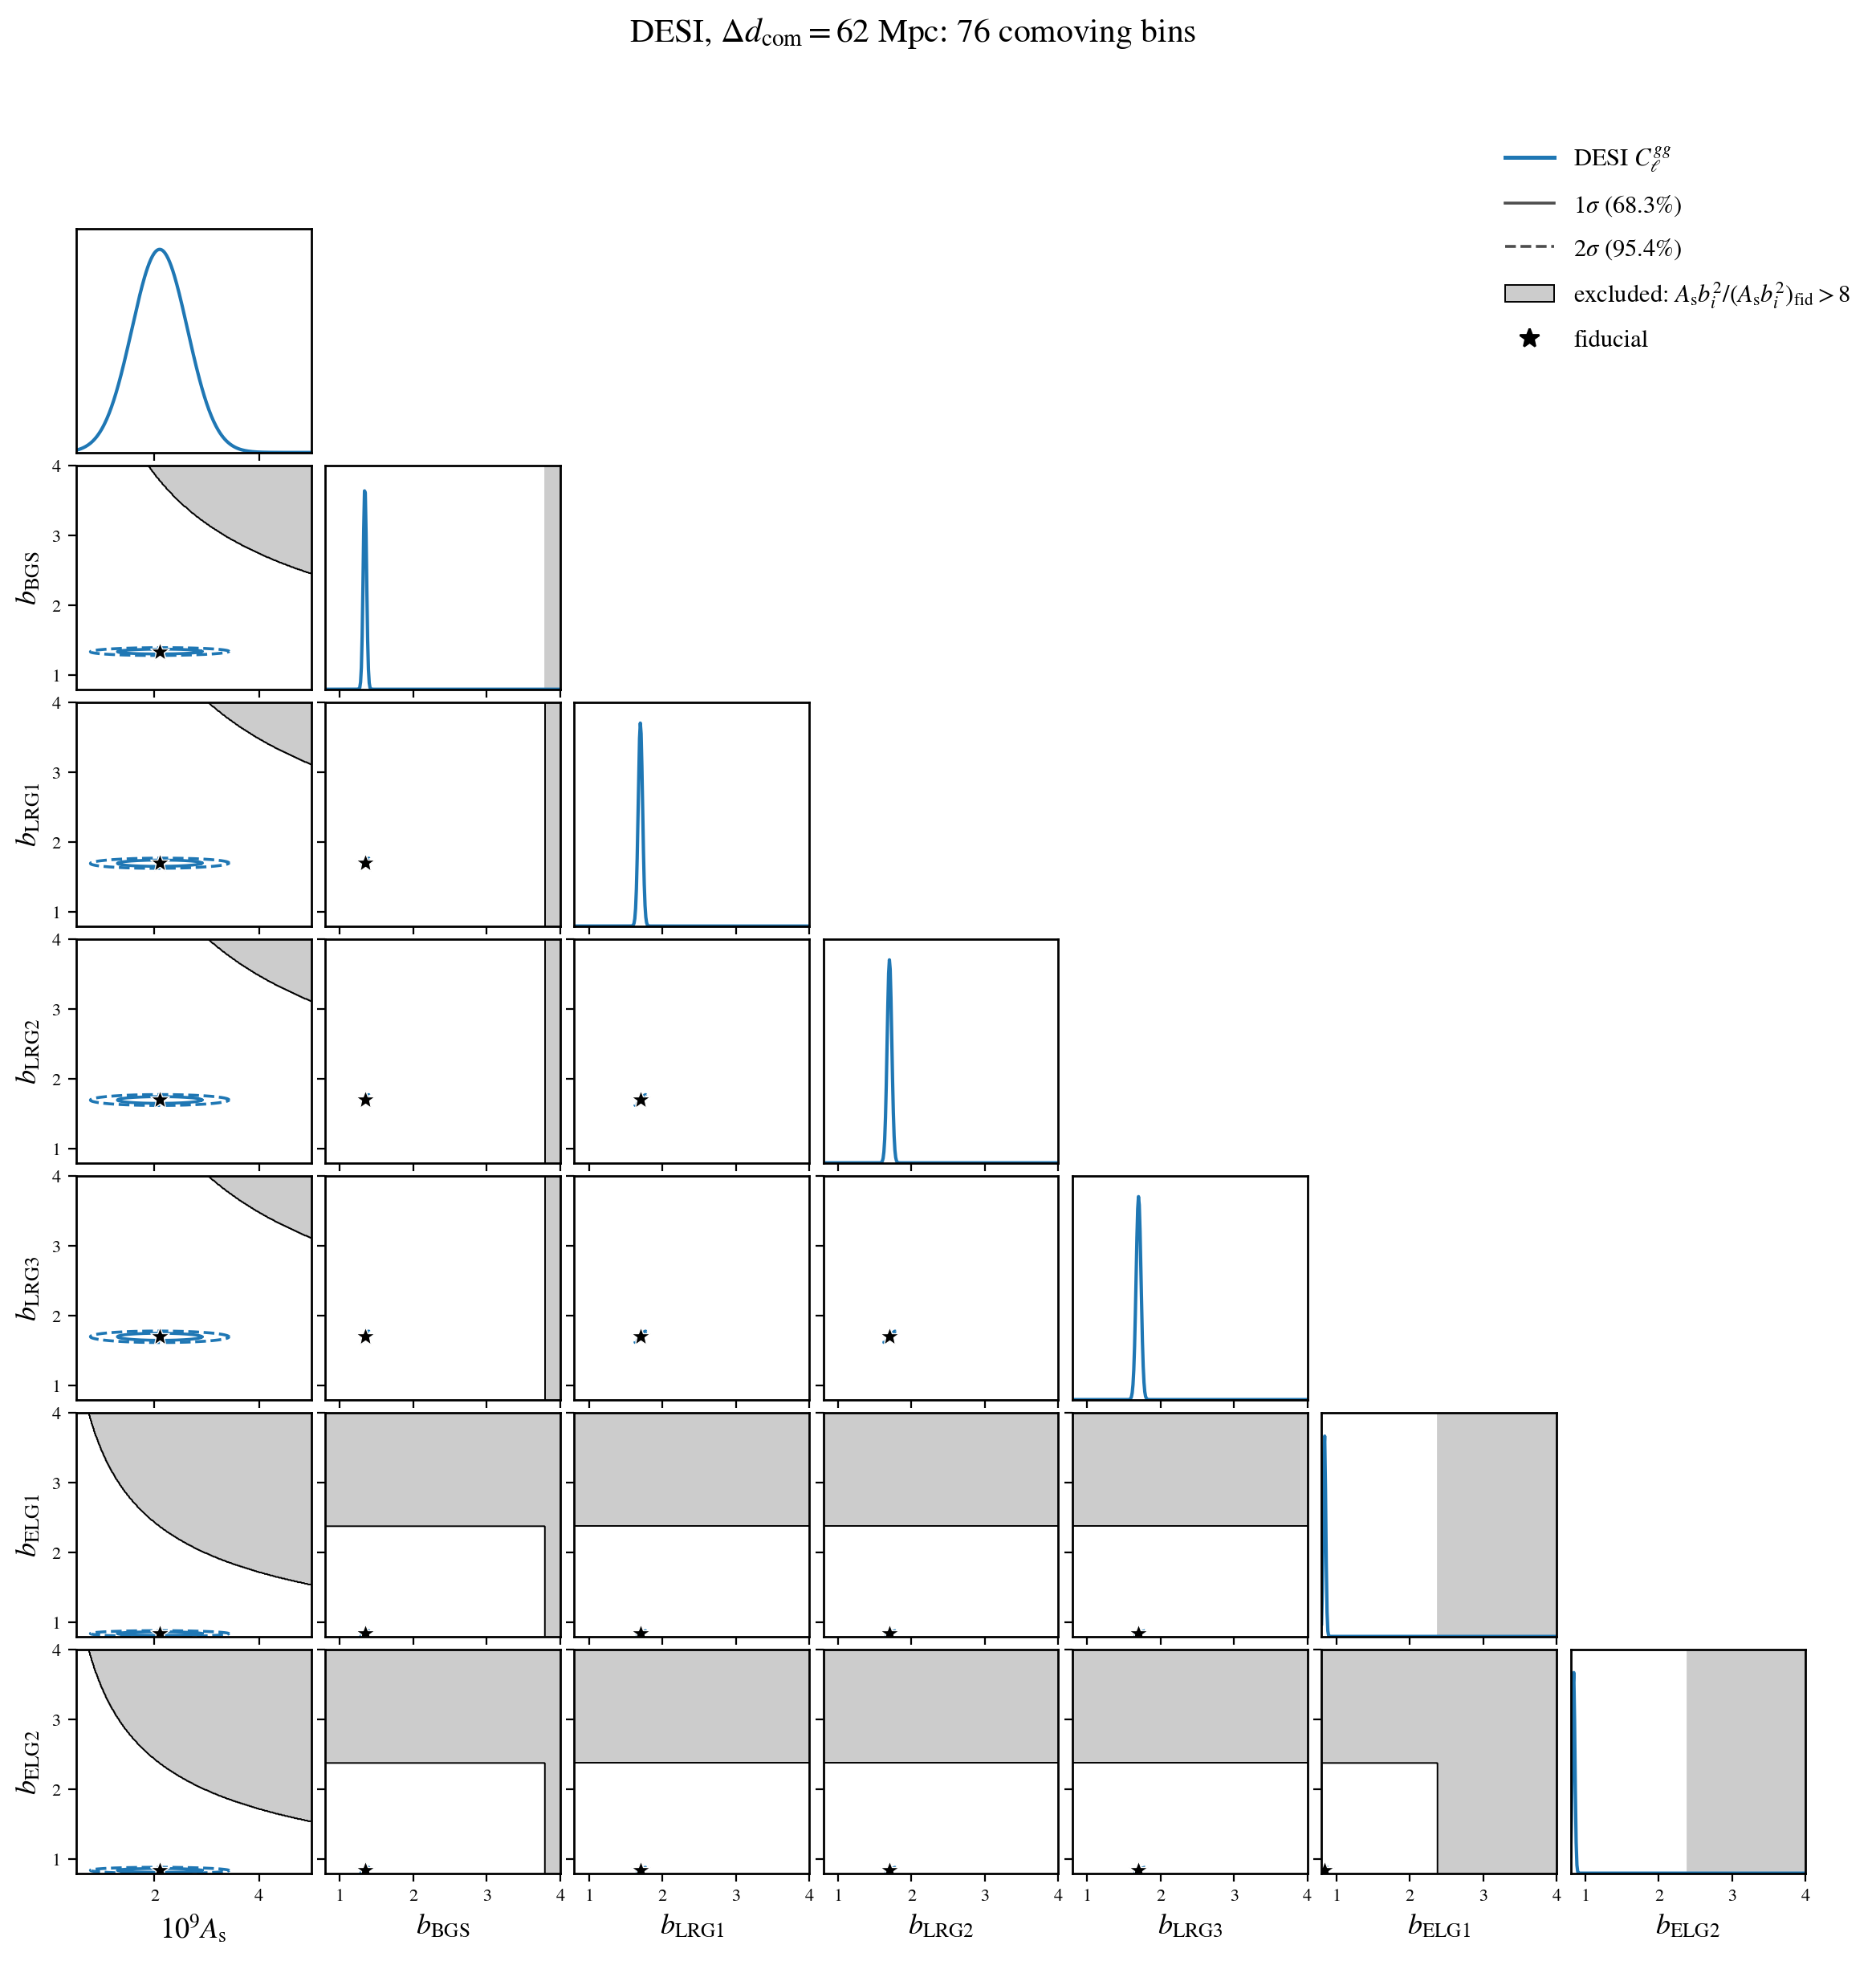

In [22]:
draw_amplitude_cut('Delta d_com = 62 Mpc')

Delta d_com = 62 Mpc, DESI C_gg: 2 sigma ranges Omega_m 0.246 to 0.354, w0 -1.39 to -0.612, w0 + wa -2.13 to 0.131; walls crossed: w0 + wa = -0.01
Delta d_com = 62 Mpc, LSST Y1 3x2pt + DESI C_gg: 2 sigma ranges Omega_m 0.271 to 0.329, w0 -1.32 to -0.682, w0 + wa -1.78 to -0.219; walls crossed: none


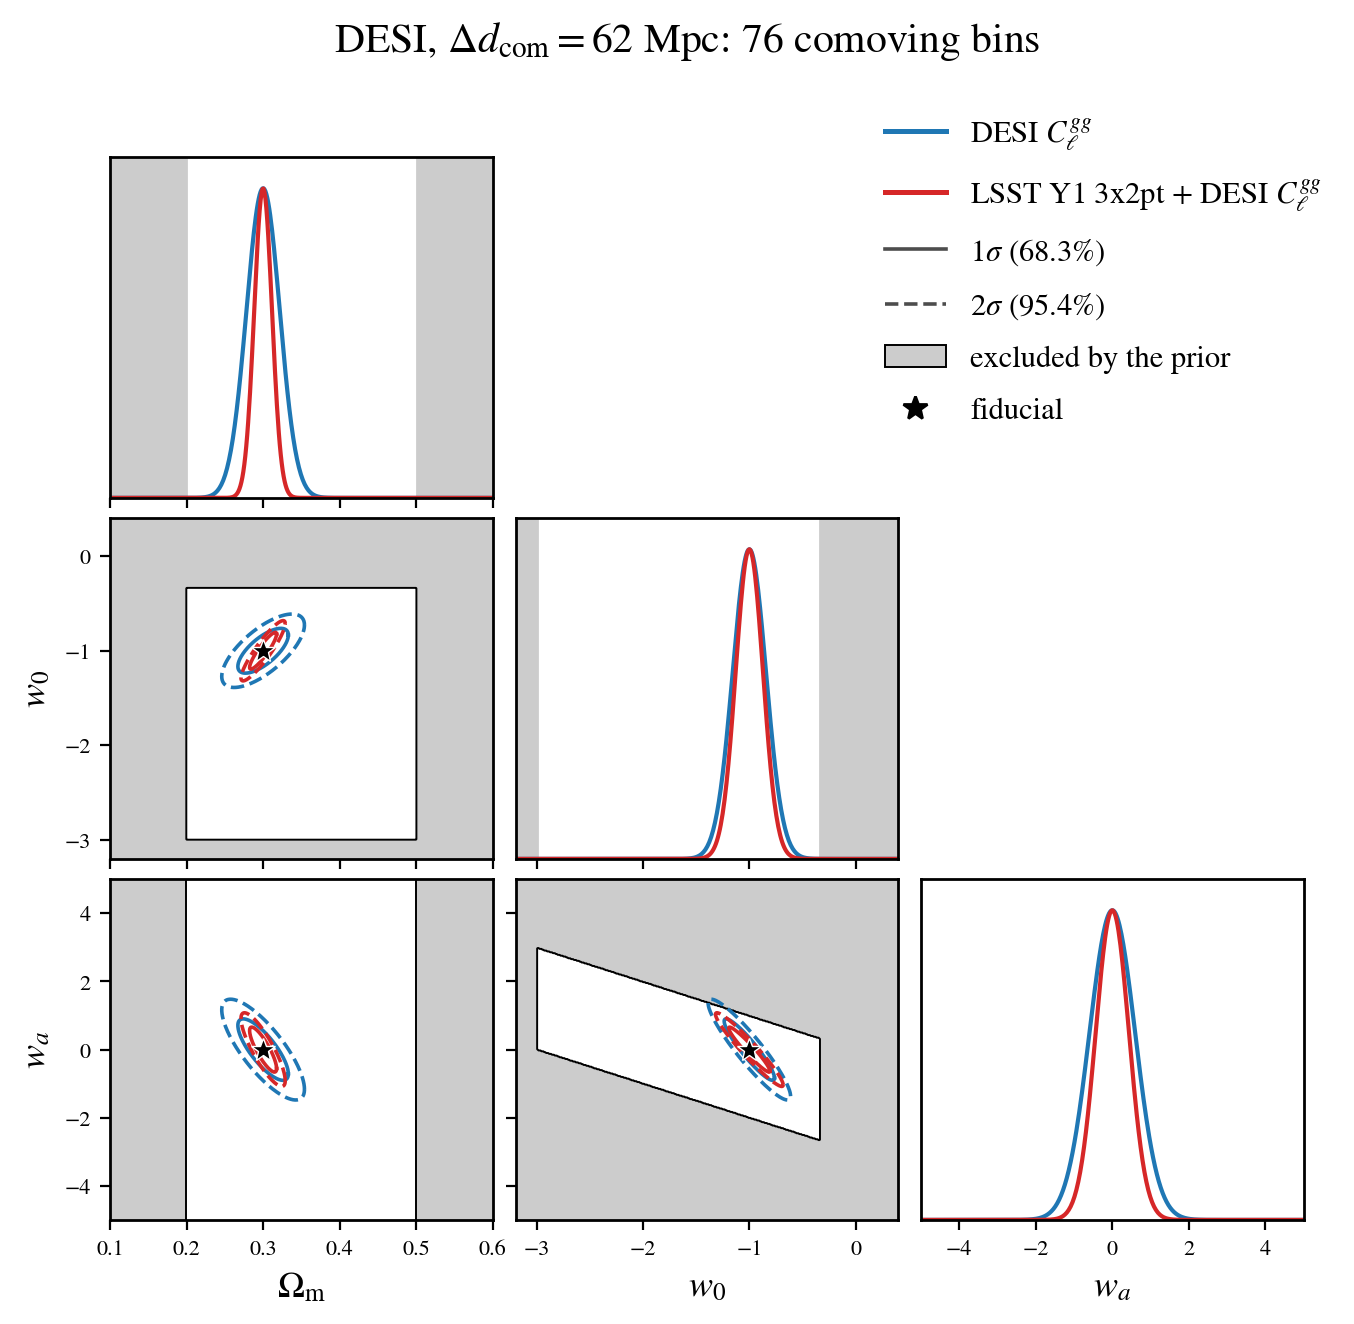

In [23]:
draw_prior_walls('Delta d_com = 62 Mpc')

### $\Delta z = 0.02$

90 bins of width $\Delta z = 0.02$, at the derivative accuracy of
`LAYOUT_FISHER_OVERRIDES`. The matrix is cached in
`chains/EXAMPLE_EVALUATE_LINEAR2_FISHER.pkl`; a first run without the cache builds it
in about 65 minutes on a laptop with 4 threads. Measured at the step $h = 0.02$:

- the largest amplitude ratio on the DESI $2\sigma$ contours is 1.60, far inside the
  cut at 8;
- the DESI-alone $2\sigma$ contour crosses the $w_0 + w_a = -0.01$ wall; the
  $2\sigma$ contour of LSST Y1 3x2pt + DESI $C_\ell^{gg}$ touches no wall;
- DESI alone reaches $\sigma(\Omega_m) = 0.0214$, $\sigma(w_0) = 0.153$ and
  $\sigma(w_a) = 0.560$, with FoM$(w_0, w_a) = 30.4$; the combination tightens
  them to 0.0119, 0.124 and 0.404, with FoM $= 69.0$. This layout's FoM is
  about 9% above that of $\Delta d_\mathrm{com} = 62$ Mpc.

Here too the bias-bias $2\sigma$ ellipses of the amplitude-cut triangle are too
small to see at the plotted box ranges: only the fiducial stars show.

Delta z = 0.02: largest (A_s/A_s,fid)(b/b_fid)^2 on the DESI C_gg 2 sigma contours, groups BGS, LRG1, LRG2, LRG3, ELG1, ELG2: 1.600, 1.602, 1.599, 1.596, 1.598, 1.598
Delta z = 0.02: marginalized sigma(b) of the group biases from 0.0171 to 0.0334


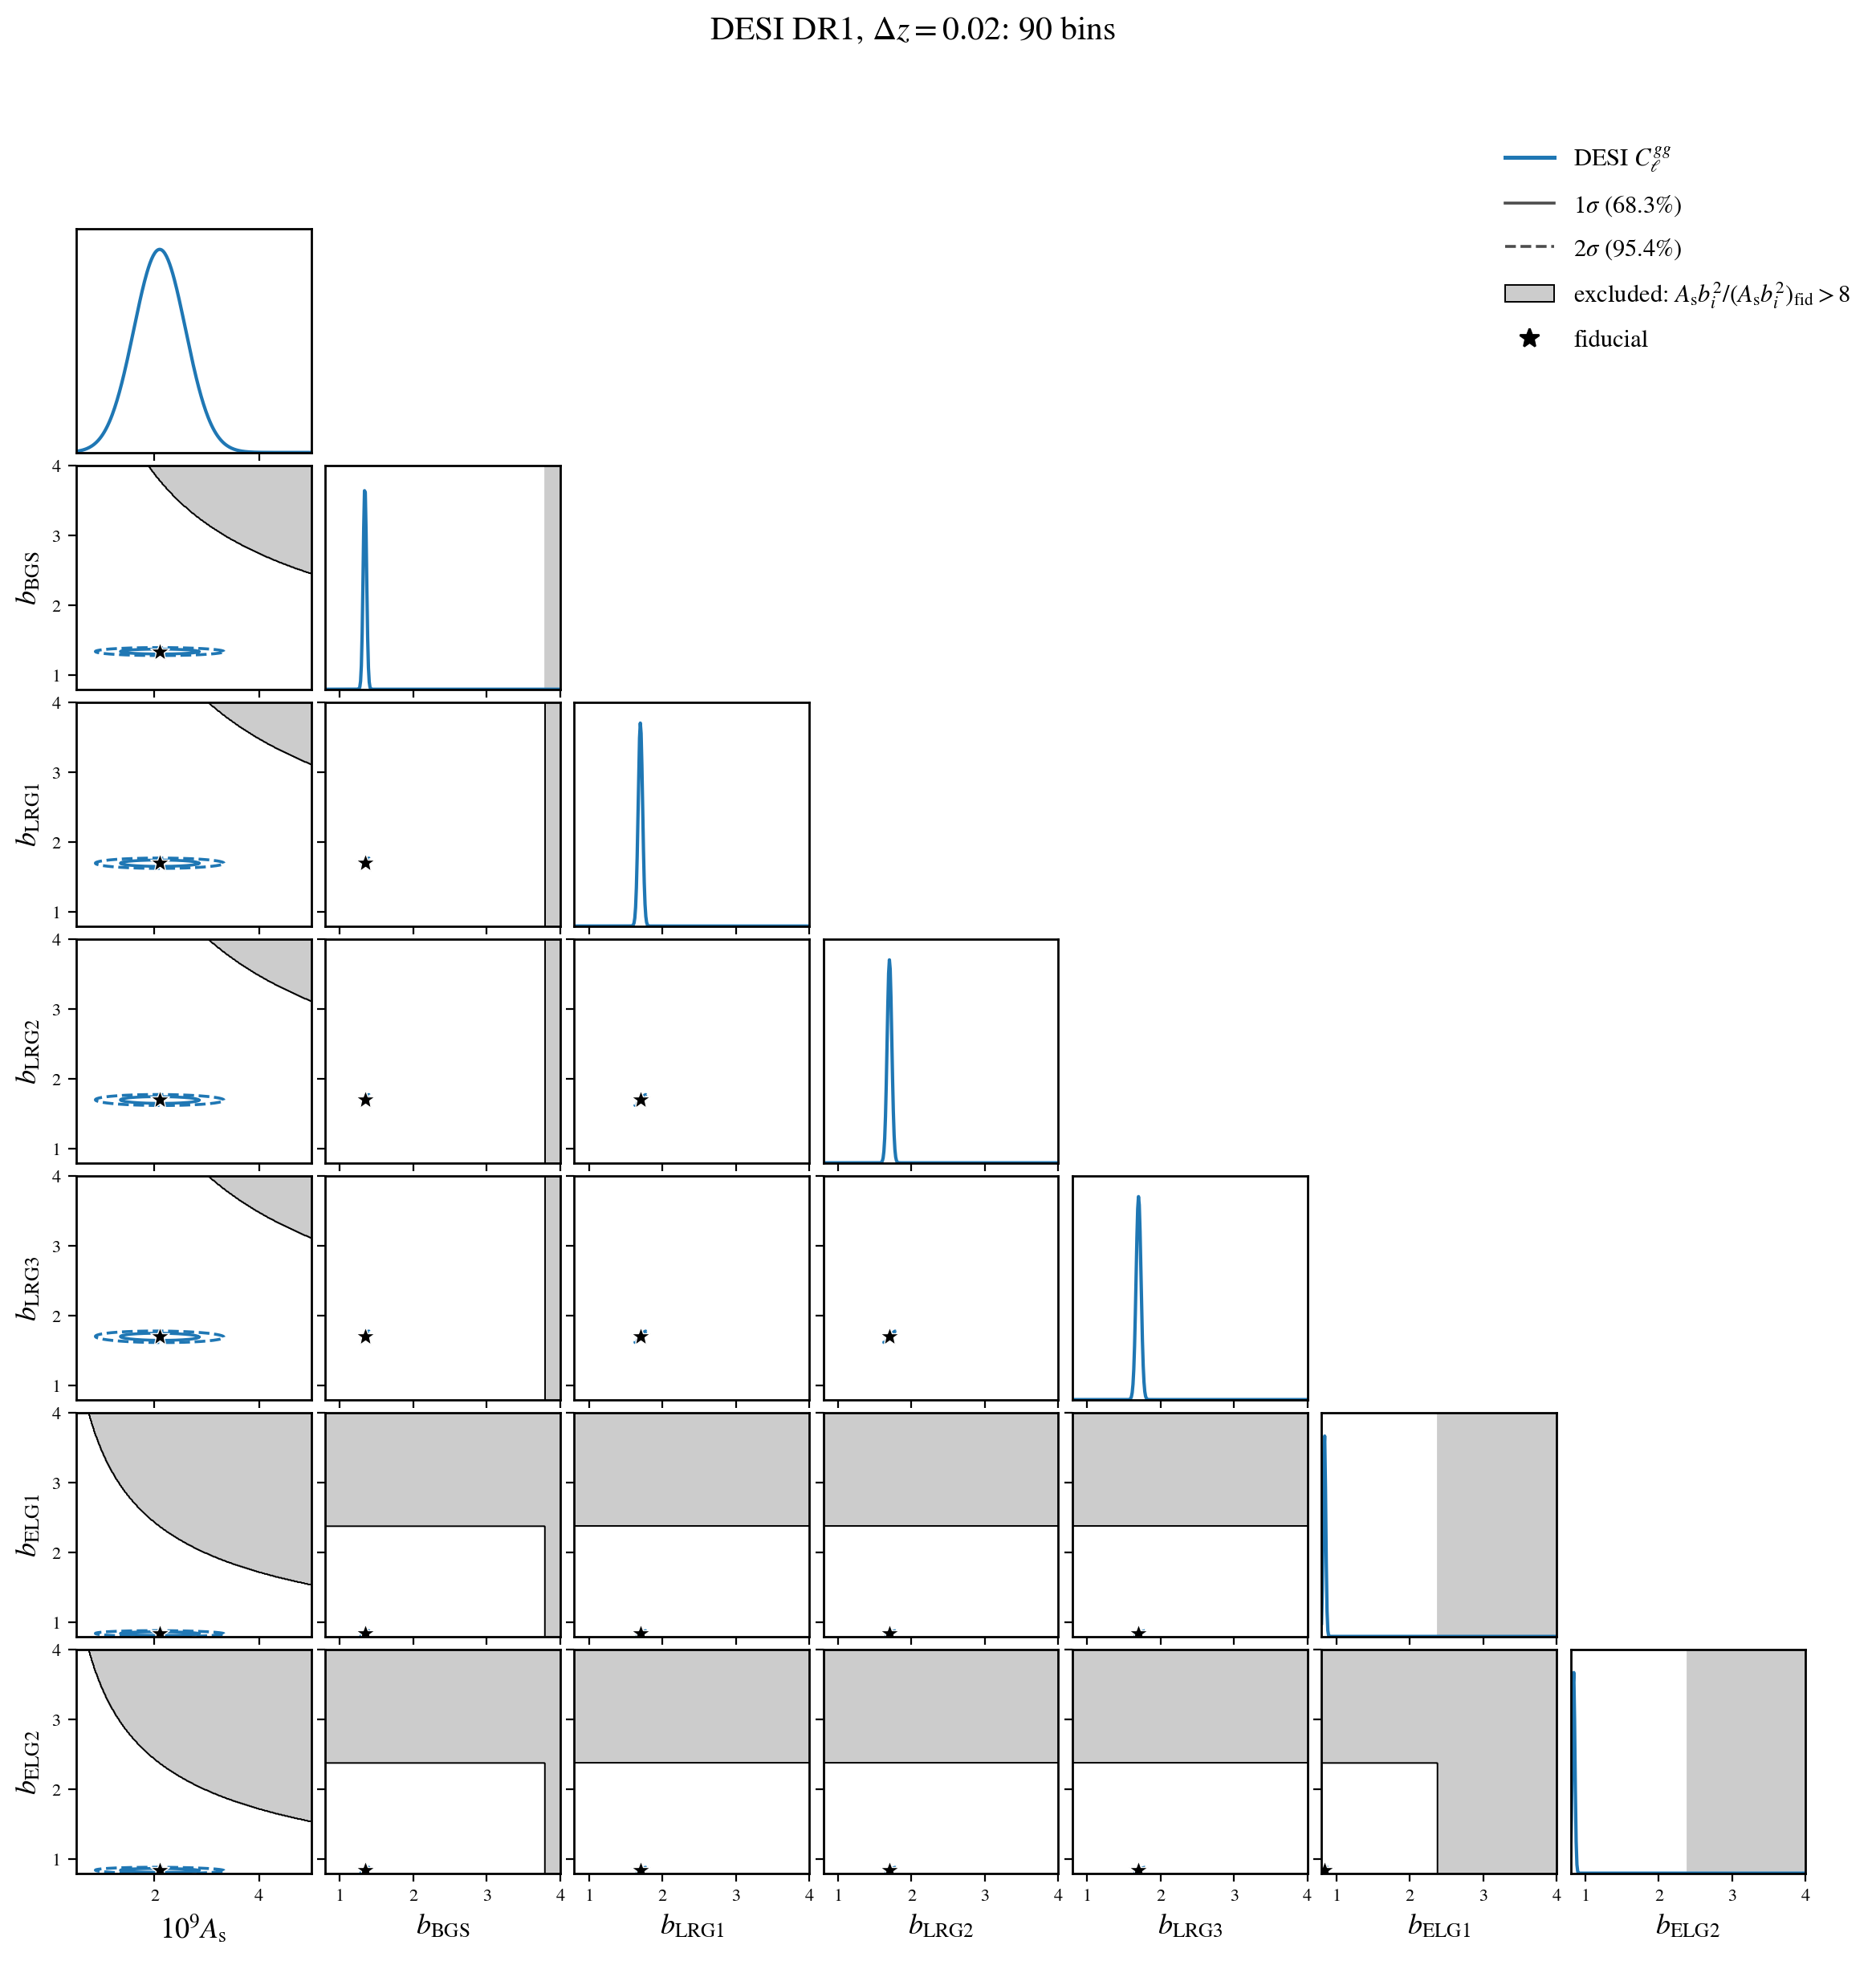

In [24]:
draw_amplitude_cut('Delta z = 0.02')

Delta z = 0.02, DESI C_gg: 2 sigma ranges Omega_m 0.247 to 0.353, w0 -1.38 to -0.62, w0 + wa -2.05 to 0.0509; walls crossed: w0 + wa = -0.01
Delta z = 0.02, LSST Y1 3x2pt + DESI C_gg: 2 sigma ranges Omega_m 0.27 to 0.33, w0 -1.31 to -0.693, w0 + wa -1.72 to -0.284; walls crossed: none


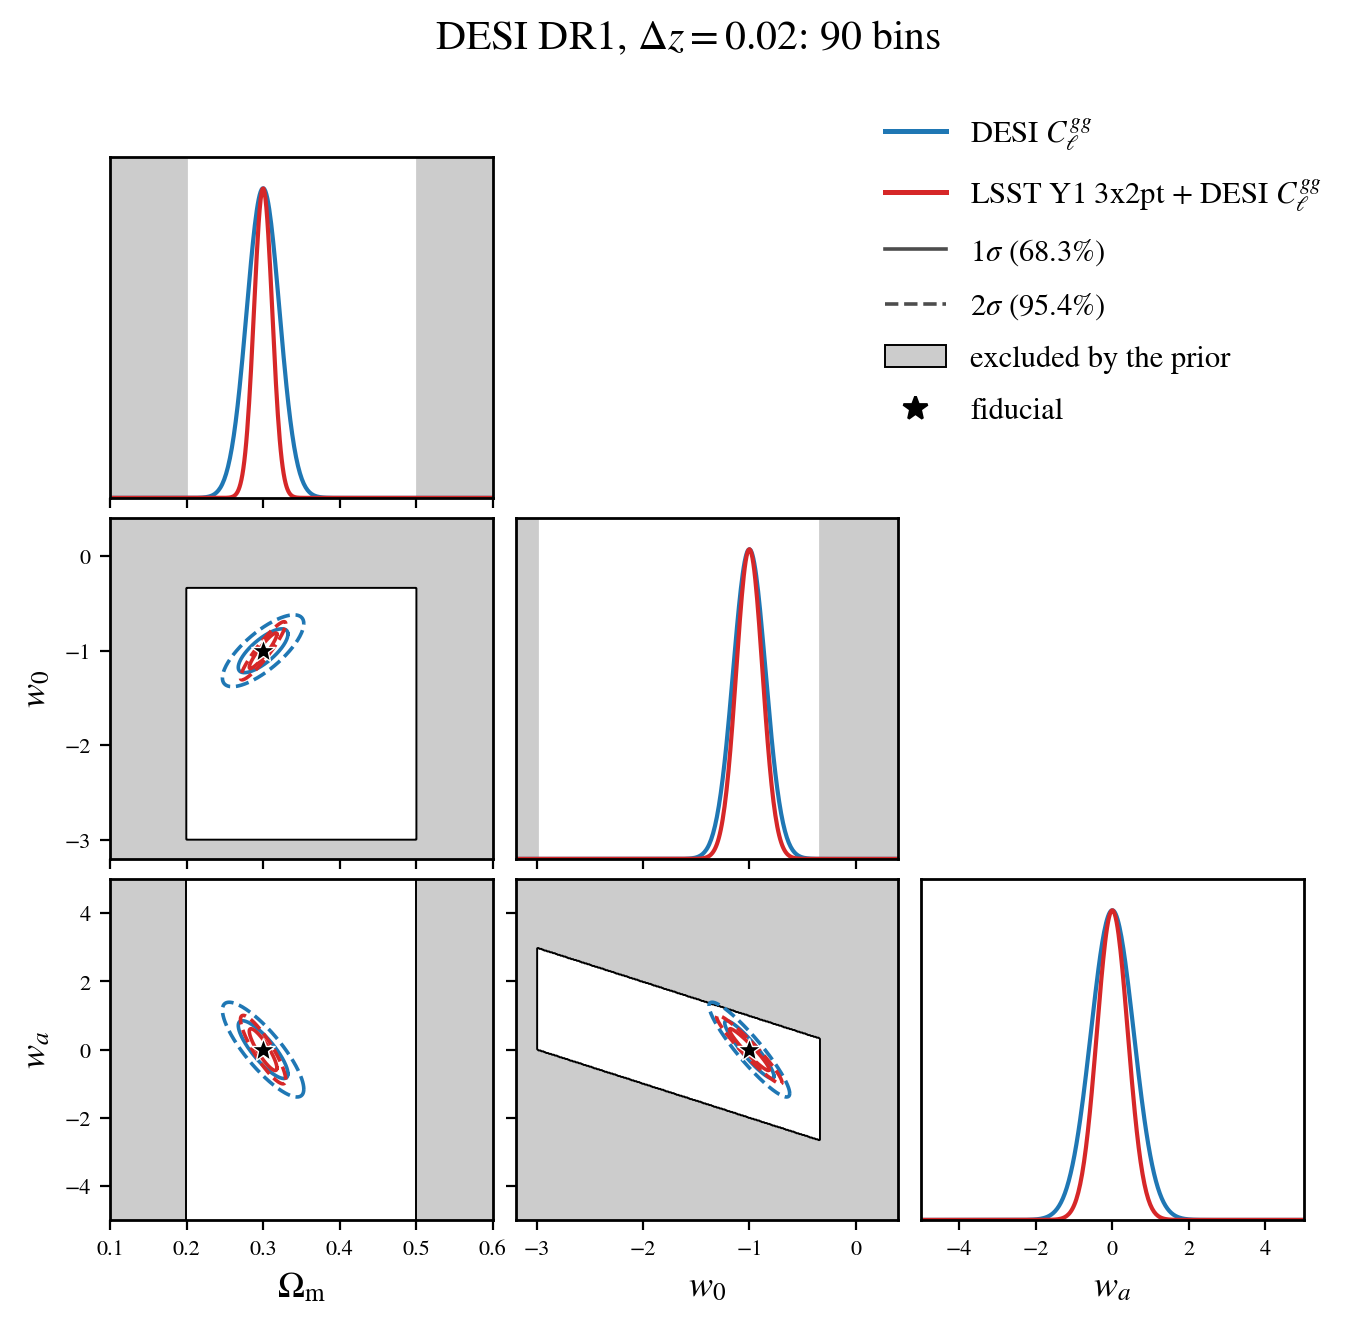

In [25]:
draw_prior_walls('Delta z = 0.02')

### $\Delta z = 0.05$

36 bins of width $\Delta z = 0.05$, at the derivative accuracy of
`LAYOUT_FISHER_OVERRIDES` (a derivative needs a denser $\chi$ grid than the
likelihood ships). Measured at the step $h = 0.02$:

- the largest amplitude ratio on the DESI $2\sigma$ contours is 1.93, far inside the
  cut at 8;
- the DESI-alone $2\sigma$ contours cross the $w_0 + w_a = -0.01$ wall: their
  ranges are $\Omega_m$ 0.225-0.375, $w_0$ up to $-0.41$ and $w_0 + w_a$ from
  $-2.62$ to $0.62$; the $2\sigma$ contour of LSST Y1 3x2pt + DESI $C_\ell^{gg}$
  also crosses that wall, reaching 0.002;
- DESI alone reaches $\sigma(\Omega_m) = 0.0302$, $\sigma(w_0) = 0.239$ and
  $\sigma(w_a) = 0.856$, with FoM$(w_0, w_a) = 10.9$; the combination reaches
  FoM $= 38.3$.

Here too the bias-bias $2\sigma$ ellipses of the amplitude-cut triangle are too
small to see at the plotted box ranges: only the fiducial stars show.

Delta z = 0.05: largest (A_s/A_s,fid)(b/b_fid)^2 on the DESI C_gg 2 sigma contours, groups BGS, LRG1, LRG2, LRG3, ELG1, ELG2: 1.925, 1.915, 1.906, 1.900, 1.902, 1.903
Delta z = 0.05: marginalized sigma(b) of the group biases from 0.0192 to 0.0378


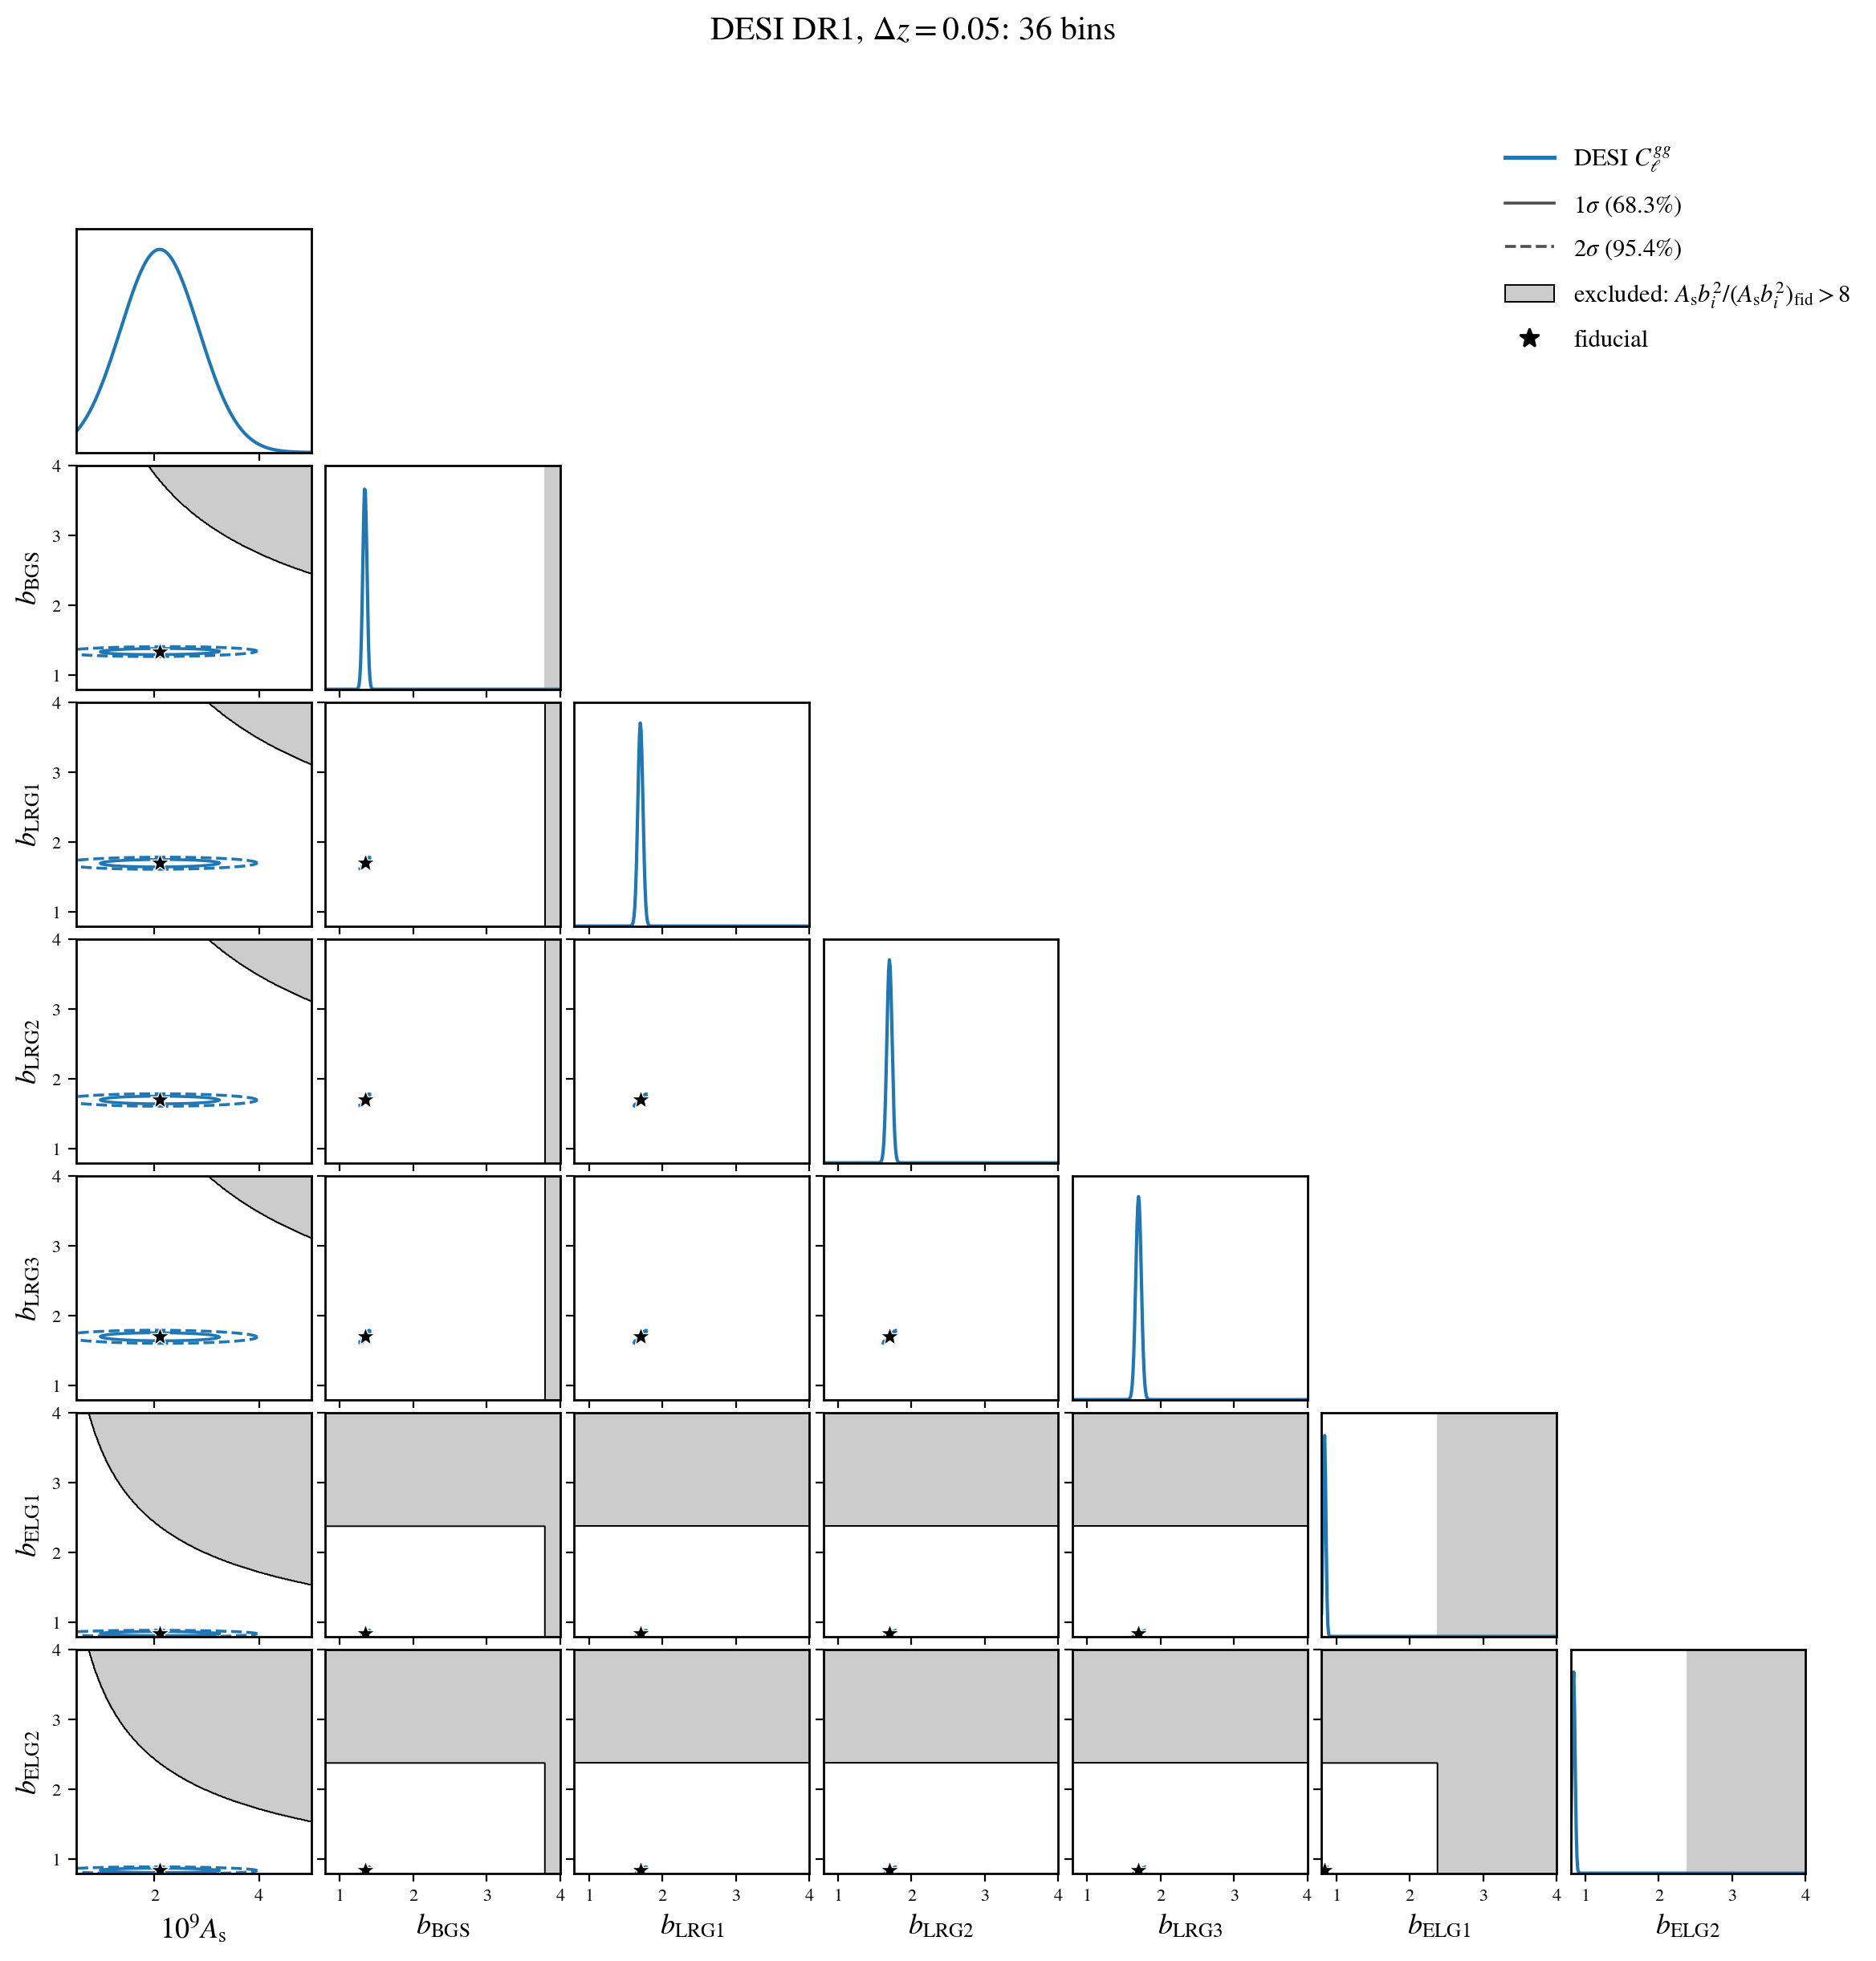

In [26]:
draw_amplitude_cut('Delta z = 0.05')

Delta z = 0.05, DESI C_gg: 2 sigma ranges Omega_m 0.225 to 0.375, w0 -1.59 to -0.405, w0 + wa -2.62 to 0.618; walls crossed: w0 + wa = -0.01
Delta z = 0.05, LSST Y1 3x2pt + DESI C_gg: 2 sigma ranges Omega_m 0.262 to 0.338, w0 -1.42 to -0.577, w0 + wa -2 to 0.00177; walls crossed: w0 + wa = -0.01


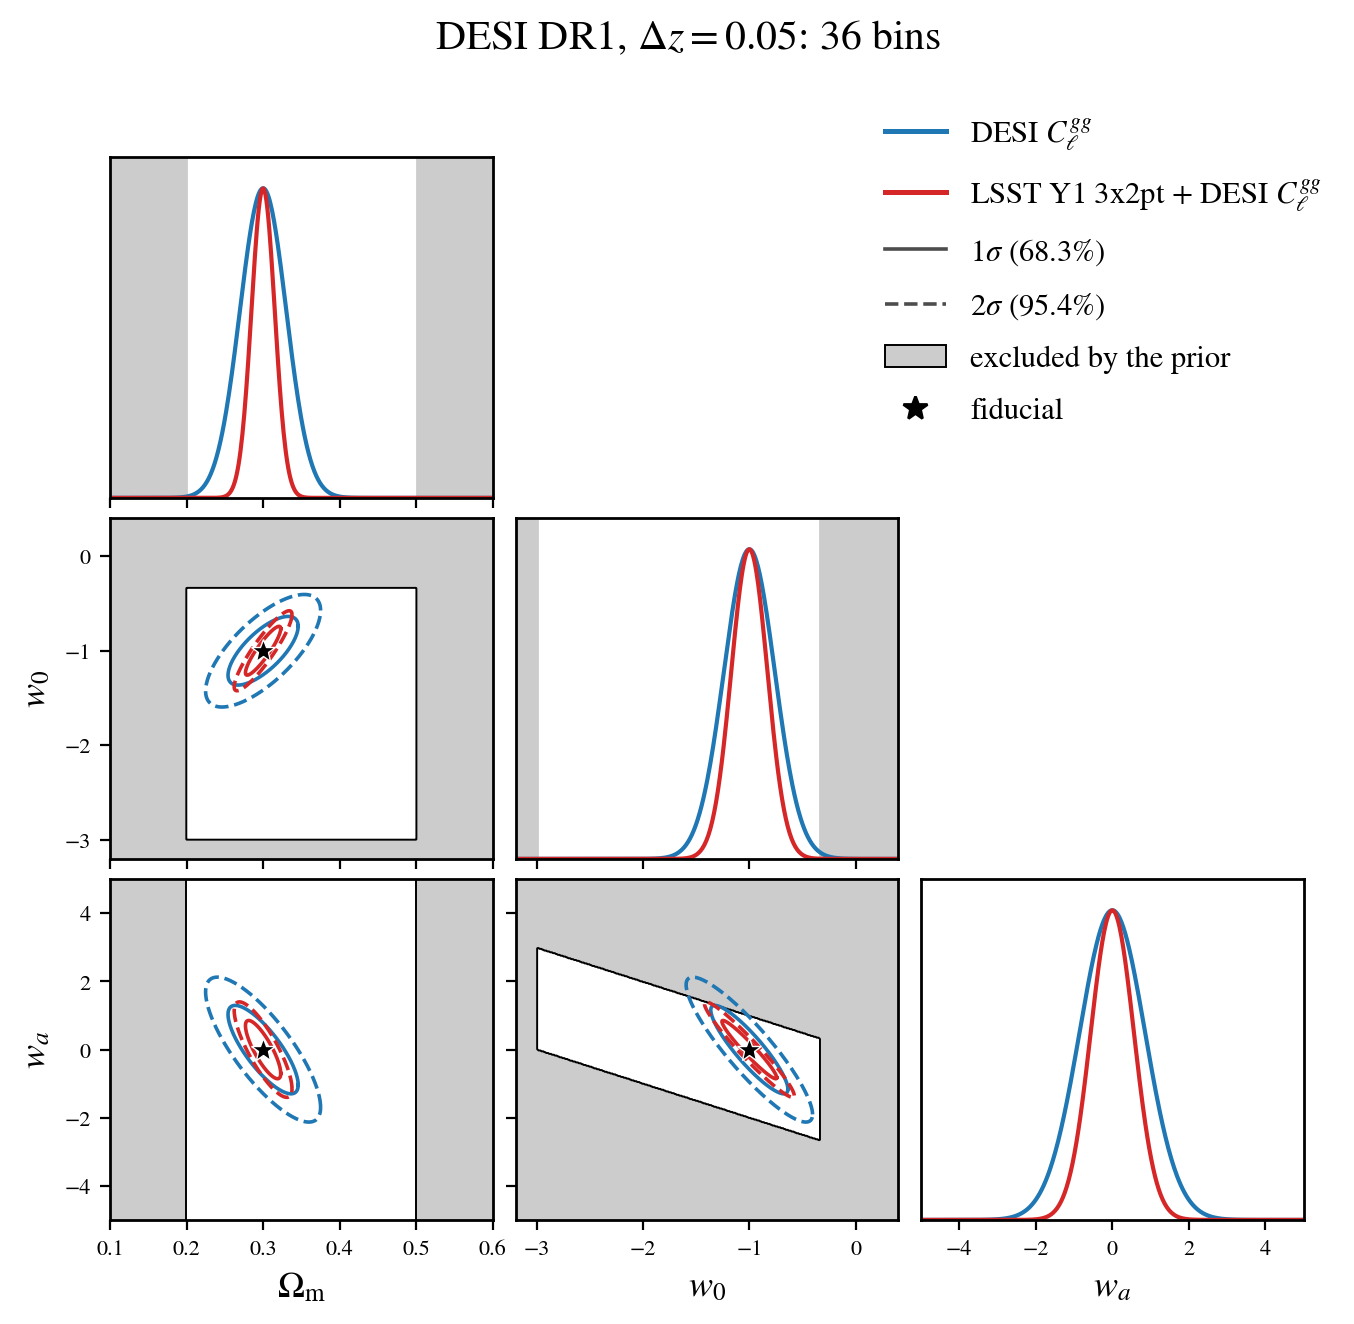

In [27]:
draw_prior_walls('Delta z = 0.05')

### $\Delta z = 0.2$

The ten wide bins of the main forecast; the matrices are those of section 3, at the
derivative accuracy of `DESI_FISHER_OVERRIDES` and `DESI_FISHER_CAMB`. Measured at the step $h = 0.02$:

- the largest amplitude ratio on the DESI $2\sigma$ contours is 3.13, still well
  inside the cut at 8;
- the DESI-alone $2\sigma$ contours cross the $\Omega_m = 0.2$ wall, the
  $w_0 = -1/3$ wall and both $w_0 + w_a$ walls ($\Omega_m$ spans 0.17 to 0.43 and
  $w_0 + w_a$ spans $-4.62$ to $2.62$): on these wide bins DESI clustering alone
  is partly prior-bounded;
- the $2\sigma$ contour of LSST Y1 3x2pt + DESI $C_\ell^{gg}$ crosses only the
  $w_0 + w_a = -0.01$ wall, reaching 0.30, and its $\Omega_m$ stays inside
  $[0.2, 0.5]$;
- FoM$(w_0, w_a)$: DESI alone 2.43, the combination 24.6.

Delta z = 0.2: largest (A_s/A_s,fid)(b/b_fid)^2 on the DESI C_gg 2 sigma contours, groups BGS, LRG1, LRG2, LRG3, ELG1, ELG2: 3.126, 3.042, 2.979, 2.945, 2.936, 2.933
Delta z = 0.2: marginalized sigma(b) of the group biases from 0.0548 to 0.119


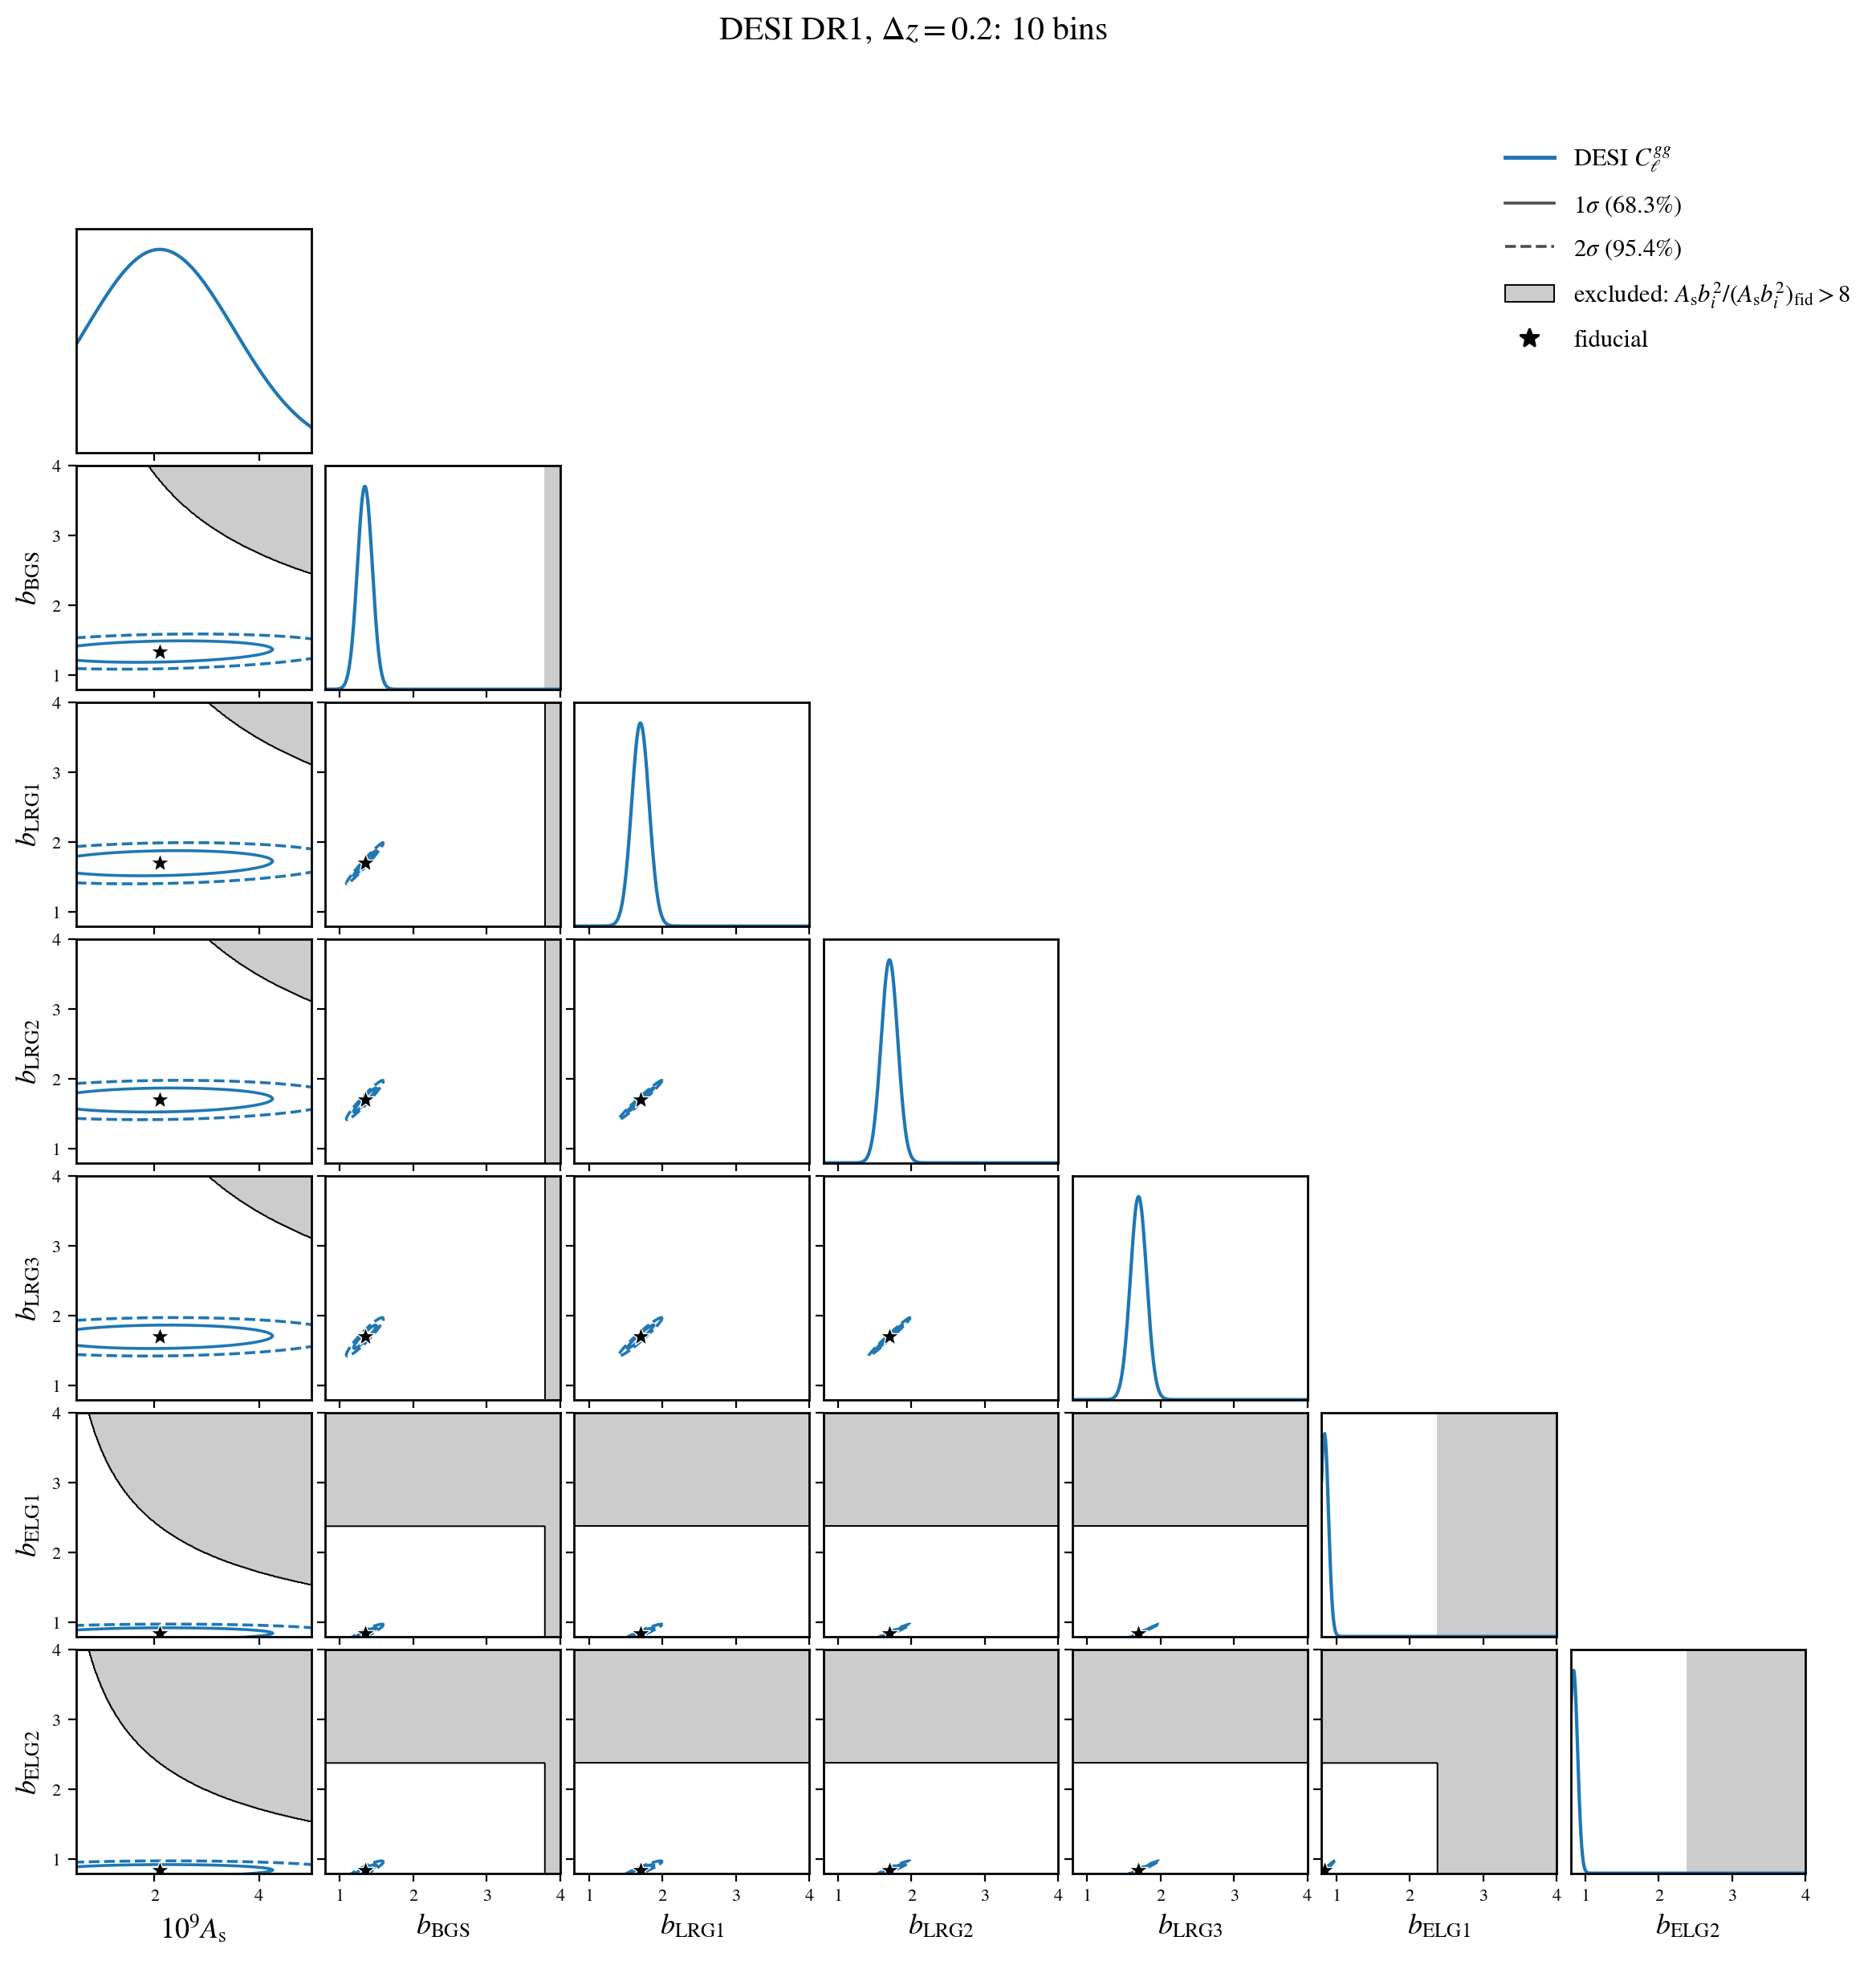

In [28]:
draw_amplitude_cut('Delta z = 0.2')

Delta z = 0.2, DESI C_gg: 2 sigma ranges Omega_m 0.17 to 0.43, w0 -2.14 to 0.143, w0 + wa -4.62 to 2.62; walls crossed: Omega_m = 0.2, w0 = -0.33333, w0 + wa = -3, w0 + wa = -0.01
Delta z = 0.2, LSST Y1 3x2pt + DESI C_gg: 2 sigma ranges Omega_m 0.254 to 0.346, w0 -1.54 to -0.464, w0 + wa -2.3 to 0.297; walls crossed: w0 + wa = -0.01


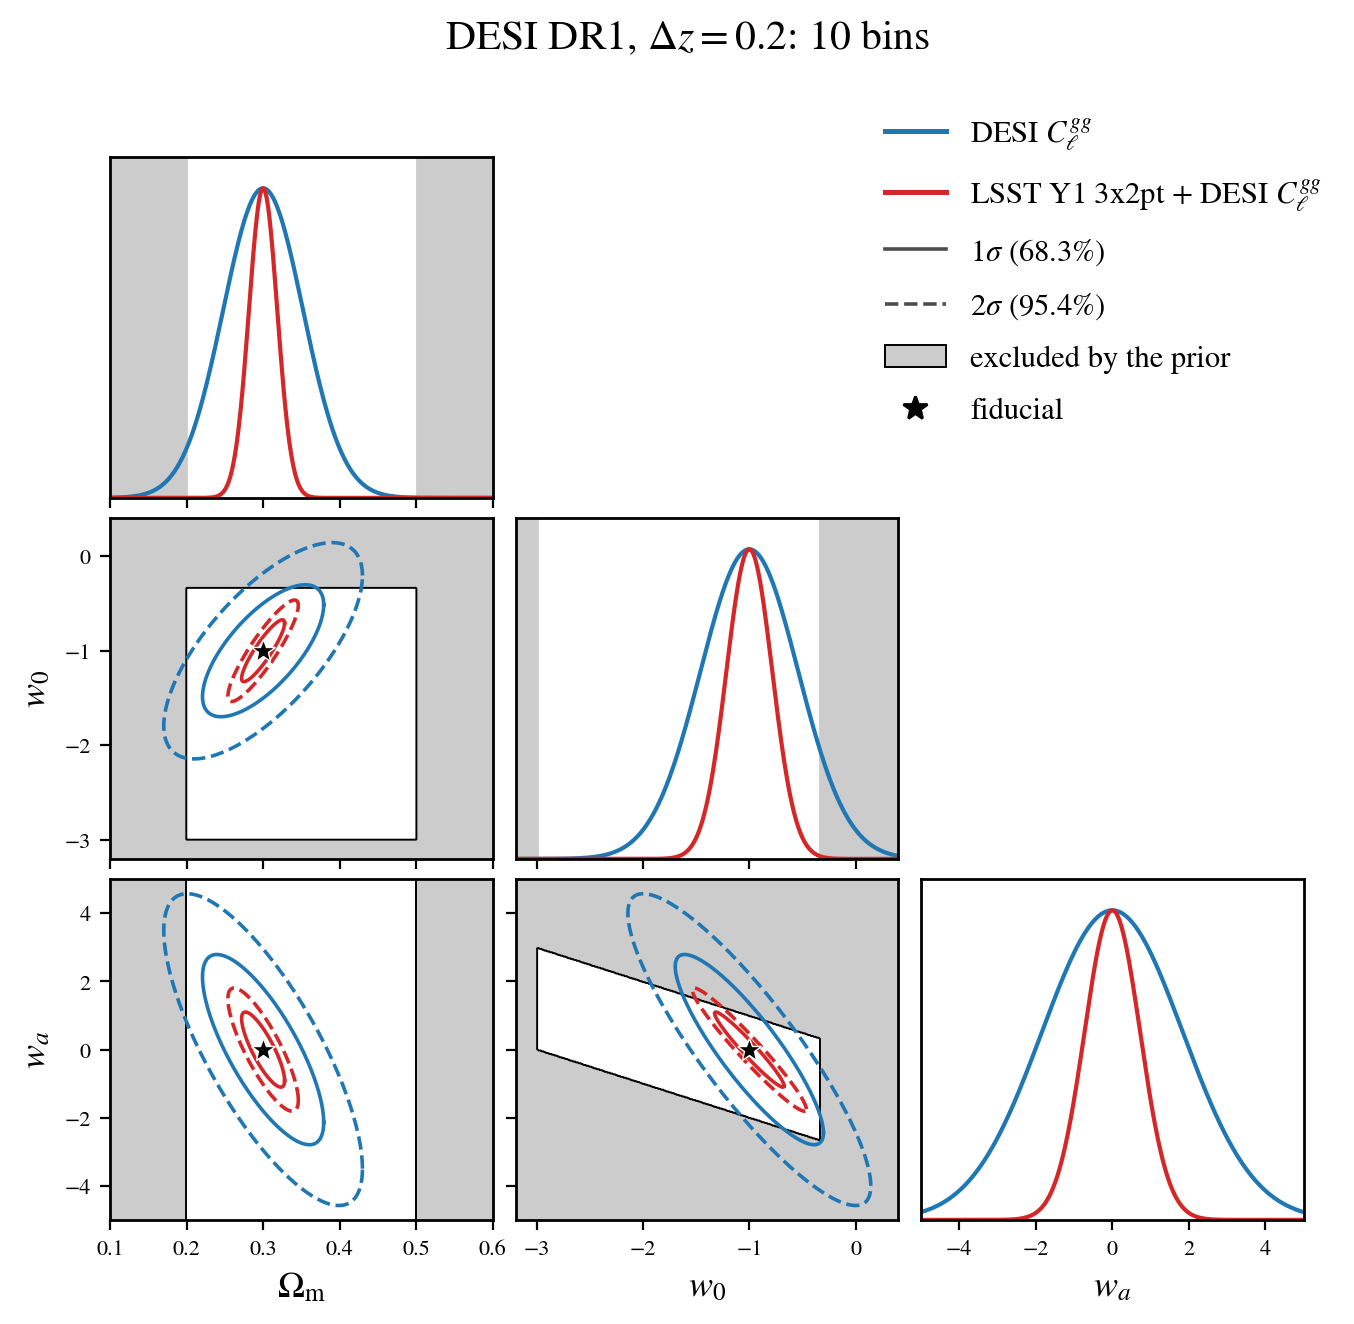

In [29]:
draw_prior_walls('Delta z = 0.2')

### The figure of merit against the scale cut

**Preliminary: linear bias only.** The galaxy model is linear bias times the
nonlinear matter power spectrum; the FoM values of this subsection are a
preliminary read of the information content until the higher-order bias model
is in place.

A scale cut drops the small scales the model cannot be trusted to predict. The
cut here is the non-Limber UV-fraction scale cut, following
arXiv:2603.13031. Each band power $C_\ell$ is split in two by a step on
the 3D power spectrum:
$C_\ell^\mathrm{IR}$ is computed with $P(k)$ multiplied by a step that keeps
only $k \le k_\mathrm{max}/D(z)$, and $C_\ell^\mathrm{UV} = C_\ell -
C_\ell^\mathrm{IR}$ is the rest. Here $D(z)$ is the linear growth factor,
normalized to $D(0) = 1$, and $k_\mathrm{max}$ is quoted in $h$ Mpc$^{-1}$ at
$z = 0$. A band is kept while its UV fraction stays below $\alpha$,

$$\frac{|C_\ell^\mathrm{UV}|}{|C_\ell^\mathrm{UV}| + |C_\ell^\mathrm{IR}|}
< \alpha, \qquad \alpha = 0.05,$$

the paper's baseline (it also uses 0.01).

Why divide by the growth factor? Nonlinear structure forms late: at redshift
$z$ the density fluctuations are smaller than today's by $D(z)$, so the scale
where linear bias and perturbation theory degrade sits at a higher $k$ than at
$z = 0$. Cutting at $k_\mathrm{max}/D(z)$ keeps a roughly constant degree of
nonlinearity at every redshift, instead of a fixed comoving scale.

Because the criterion is a step on the power spectrum, not a relation between
$\ell$ and $k$, it needs no Limber approximation: the step multiplies $P(k)$
inside every $C_\ell^{gg}$ engine of the compiled code - the Limber integral,
the FKEM split and the low-rank non-Limber engine the DESI layouts use. That
is decisive for thin bins. A bin of comoving width $\Delta\chi$ collects
radial modes up to $k_\parallel \sim 2\pi/\Delta\chi$, and for the thin
layouts those lie beyond the cut at every multipole, so even the lowest bands
have a large UV part. The Limber relation
$\ell \le k_\mathrm{max}\,\chi(\bar z) - 1/2$ counts only the transverse
modes and misses this completely: a Limber-based cut would keep low-$\ell$
bands whose value the model does not actually predict.

The cross spectra of adjacent thin bins are the sharpest case. Their signal
comes mostly from galaxy pairs that straddle the shared bin edge - close
pairs, small radial separations, large $k_\parallel$ - so they are strongly
UV-dominated and lose most of their bands at every $k_\mathrm{max}$ of the
scan.

The kept bands of a spectrum form a prefix in $\ell$: every band up to the
first that fails the criterion. Where the UV fraction is not monotonic in
$k_\mathrm{max}$, each prefix is shortened to the prefix of the next larger
$k_\mathrm{max}$, so the cut can only tighten as $k_\mathrm{max}$ falls.

The shipped masks still apply on top of the cut: the covariance files have
entries only inside them, and they stop every bin at the fixed
$k = 0.1185$ Mpc$^{-1}$ ($\approx 0.176\,h$ Mpc$^{-1}$), with no growth
scaling. The fit therefore uses (shipped mask) AND (UV-fraction cut), and the
shipped mask caps every band count and every curve below.

The next cell computes the cuts of every layout with the compiled interface
(`gg_scale_cuts_tomo`) and counts the kept band powers; each cell of its table
is autos / cross pairs. Down a column the counts grow with $k_\mathrm{max}$
until the shipped mask saturates them; across a row the thin layouts keep the
smallest fraction of their bands, the cross pairs most of all. At
$k_\mathrm{max} = 0.05\,h$ Mpc$^{-1}$ the $\Delta z = 0.02$ layout keeps
nothing, and the $\Delta d_\mathrm{com} = 62$ Mpc layout keeps only the bins above
$z \approx 0.9$, where the $1/D(z)$ scaling raises the cut the most.

In [30]:
# The non-Limber UV-fraction scale cuts (arXiv:2603.13031) of every DESI layout,
# computed by the compiled interface (gg_scale_cuts_tomo). Each C_gg band
# power splits into the part sourced by modes k <= k_max/D(z) (IR) and the
# rest (UV): the step multiplies the 3D power spectrum inside every gg
# engine, Limber and non-Limber alike, so a thin bin's radial modes count.
# A band is kept while |C_UV|/(|C_UV| + |C_IR|) < ALPHA_UV, and the kept
# bands of each spectrum are a prefix in ell that tightens as k_max falls.
# k_max is quoted in h/Mpc at z = 0.
#
# Each layout's model is built at its Fisher settings (section 4) and
# evaluated at the fiducial point; the cuts are cached, and RECOMPUTE_CUTS
# = True rebuilds them.
KMAX_CUTS = np.round(np.arange(0.05, 0.2501, 0.025), 3)  # h/Mpc at z = 0
ALPHA_UV = 0.05
CUTS_CACHE = (ROOTDIR + '/projects/lssty1xdesi/chains/'
              'EXAMPLE_EVALUATE_FISHER_SCALE_CUTS.pkl')
RECOMPUTE_CUTS = False


def cut_settings(key):
    '''The model settings of one layout's scale cuts: its Fisher settings.'''
    if key in LAYOUT_FISHER_OVERRIDES:
        overrides = dict(LAYOUT_FISHER_OVERRIDES[key])
        camb = dict(LAYOUT_FISHER_CAMB)
        boost = LAYOUT_ACCURACY_BOOST
    else:
        overrides = dict(DESI_FISHER_OVERRIDES)
        camb = dict(DESI_FISHER_CAMB)
        boost = DESI_FISHER_BOOST
    fingerprint = fm.settings_fingerprint(LAYOUTS[key]['yaml'],
                                          likelihood_overrides=overrides,
                                          accuracy_boost=boost, camb_overrides=camb,
                                          tier=DERIVATIVE_TIER)
    return {'yaml': LAYOUTS[key]['yaml'], 'likelihood_overrides': overrides,
            'camb_overrides': camb, 'accuracy_boost': boost,
            'kmax': [float(k) for k in KMAX_CUTS], 'alpha': ALPHA_UV,
            'tier': DERIVATIVE_TIER, 'fingerprint': fingerprint}


def layout_scale_cuts(key):
    '''The UV-fraction scale cuts of one layout at KMAX_CUTS.

    Returns:
      dict of gg_scale_cuts_tomo (rows: the autos, then the cross pairs,
      in the data-vector order of the gg and gg-cross blocks), with numpy
      arrays: 'lmax' (nspec, nk), 'mask' and 'uv_fraction' (nspec, nell,
      nk), 'ell', 'kmax' and 'nautos'.
    '''
    settings = cut_settings(key)
    model = fm.ModelFisher(settings['yaml'], COSMO,
                           likelihood_overrides=settings['likelihood_overrides'],
                           accuracy_boost=settings['accuracy_boost'],
                           camb_overrides=settings['camb_overrides'])
    model.dv()  # the fiducial point sets the interface's cosmology
    cuts = fm.ci.gg_scale_cuts_tomo(np.array(KMAX_CUTS, dtype=float), ALPHA_UV)
    out = {}
    for name in ('kmax', 'ell', 'lmax', 'mask', 'uv_fraction'):
        out[name] = np.array(cuts[name])
    out['nautos'] = int(cuts['nautos'])
    del model
    return out


settings_now = {key: cut_settings(key) for key in LAYOUT_DATASETS}
if RECOMPUTE_CUTS or not os.path.exists(CUTS_CACHE):
    scale_cuts = {}
    for key in LAYOUT_DATASETS:
        start = time.time()
        scale_cuts[key] = layout_scale_cuts(key)
        print(f'{key}: {time.time() - start:.0f} s', flush=True)
    with open(CUTS_CACHE, 'wb') as f:
        pickle.dump({'cuts': scale_cuts, 'settings': settings_now}, f)
else:
    with open(CUTS_CACHE, 'rb') as f:
        cached = pickle.load(f)
    if cached['settings'] != settings_now:
        raise RuntimeError(f'{CUTS_CACHE} holds other settings: set '
                           'RECOMPUTE_CUTS = True to rebuild it')
    scale_cuts = cached['cuts']


def combined_mask(key, k_index):
    '''The shipped mask AND the UV-fraction cut at KMAX_CUTS[k_index].

    Returns:
      (mask over the full data vector, the layout_covariance dict).
    '''
    cov = layout_covariance(key)
    cuts = scale_cuts[key]
    uv_keep = cuts['mask'][:, :, k_index].ravel() > 0
    mask = cov['mask'].copy()
    mask[cov['n_ee']:] &= uv_keep
    return mask, cov


summary = {}
for key in LAYOUT_DATASETS:
    cov = layout_covariance(key)
    nautos = scale_cuts[key]['nautos']
    nell = len(scale_cuts[key]['ell'])
    split = cov['n_ee'] + nautos*nell
    for m, kmax in enumerate(KMAX_CUTS):
        mask, _ = combined_mask(key, m)
        summary[(key, 'autos')] = summary.get((key, 'autos'), {})
        summary[(key, 'pairs')] = summary.get((key, 'pairs'), {})
        summary[(key, 'autos')][kmax] = int(mask[cov['n_ee']:split].sum())
        summary[(key, 'pairs')][kmax] = int(mask[split:].sum())
    summary[(key, 'autos')]['shipped'] = int(cov['mask'][cov['n_ee']:split].sum())
    summary[(key, 'pairs')]['shipped'] = int(cov['mask'][split:].sum())
print(f'band powers kept (shipped mask AND the non-Limber UV-fraction cut, '
      f'alpha = {ALPHA_UV}); '
      'rows: k_max [h/Mpc at z = 0]')
display(pd.DataFrame(summary))

band powers kept (shipped mask AND the non-Limber UV-fraction cut, alpha = 0.05); rows: k_max [h/Mpc at z = 0]


Delta d_com = 62 Mpc       Delta z = 0.02       Delta z = 0.05        \
                        autos pairs          autos pairs          autos pairs   
0.05                      167    74              0     0            367    70   
0.075                     903   812            904   952            663   183   
0.1                      1585  1186           1928  2471            945   269   
0.125                    2049  1510           2755  3062           1148   522   
0.15                     2220  2242           2982  3118           1195   623   
0.175                    2268  3004           3016  3556           1204  1091   
0.2                      2276  3254           3016  4496           1205  1242   
0.225                    2276  3347           3016  4605           1205  1587   
0.25                     2276  3390           3016  4605           1205  1589   
 shipped                 2276  3398           3016  4605           1205  1777   

         Delta z = 0.2        
                 autos pairs  
0.05               122    44  
0.075              198    82  
0.1                267   111  
0.125              307   138  
0.15               319   156  
0.175              325   263  
0.2                325   306  
0.225              326   367  
0.25               327   415  
 shipped           329   415

The figure below turns the same cuts into a per-bin
$\ell_\mathrm{max}$: for every bin's auto spectrum, the highest multipole
the criterion keeps, against the bin's mean redshift. One panel per layout,
one color per $k_\mathrm{max}$, one marker per sample (BGS, LRG, ELG); the
black dashed line is the shipped mask's own $\ell_\mathrm{max}$, which caps
every colored curve because the covariance has no entries beyond it. A bin
with no band left sits at $\ell_\mathrm{max} = 0$.

Two trends to read. First, $\ell_\mathrm{max}$ rises with redshift, for two
compounding reasons: a fixed comoving scale subtends a smaller angle at a
larger distance, so it sits at a higher $\ell$, and the cut itself grows as
$k_\mathrm{max}/D(z)$. Second, on the thin layouts the curves sit far below
where the Limber relation $\ell \le k_\mathrm{max}\,\chi(\bar z) - 1/2$
would put them: the radial modes of a thin bin dominate the UV part already
at low $\ell$, so the criterion removes bands that relation would keep.

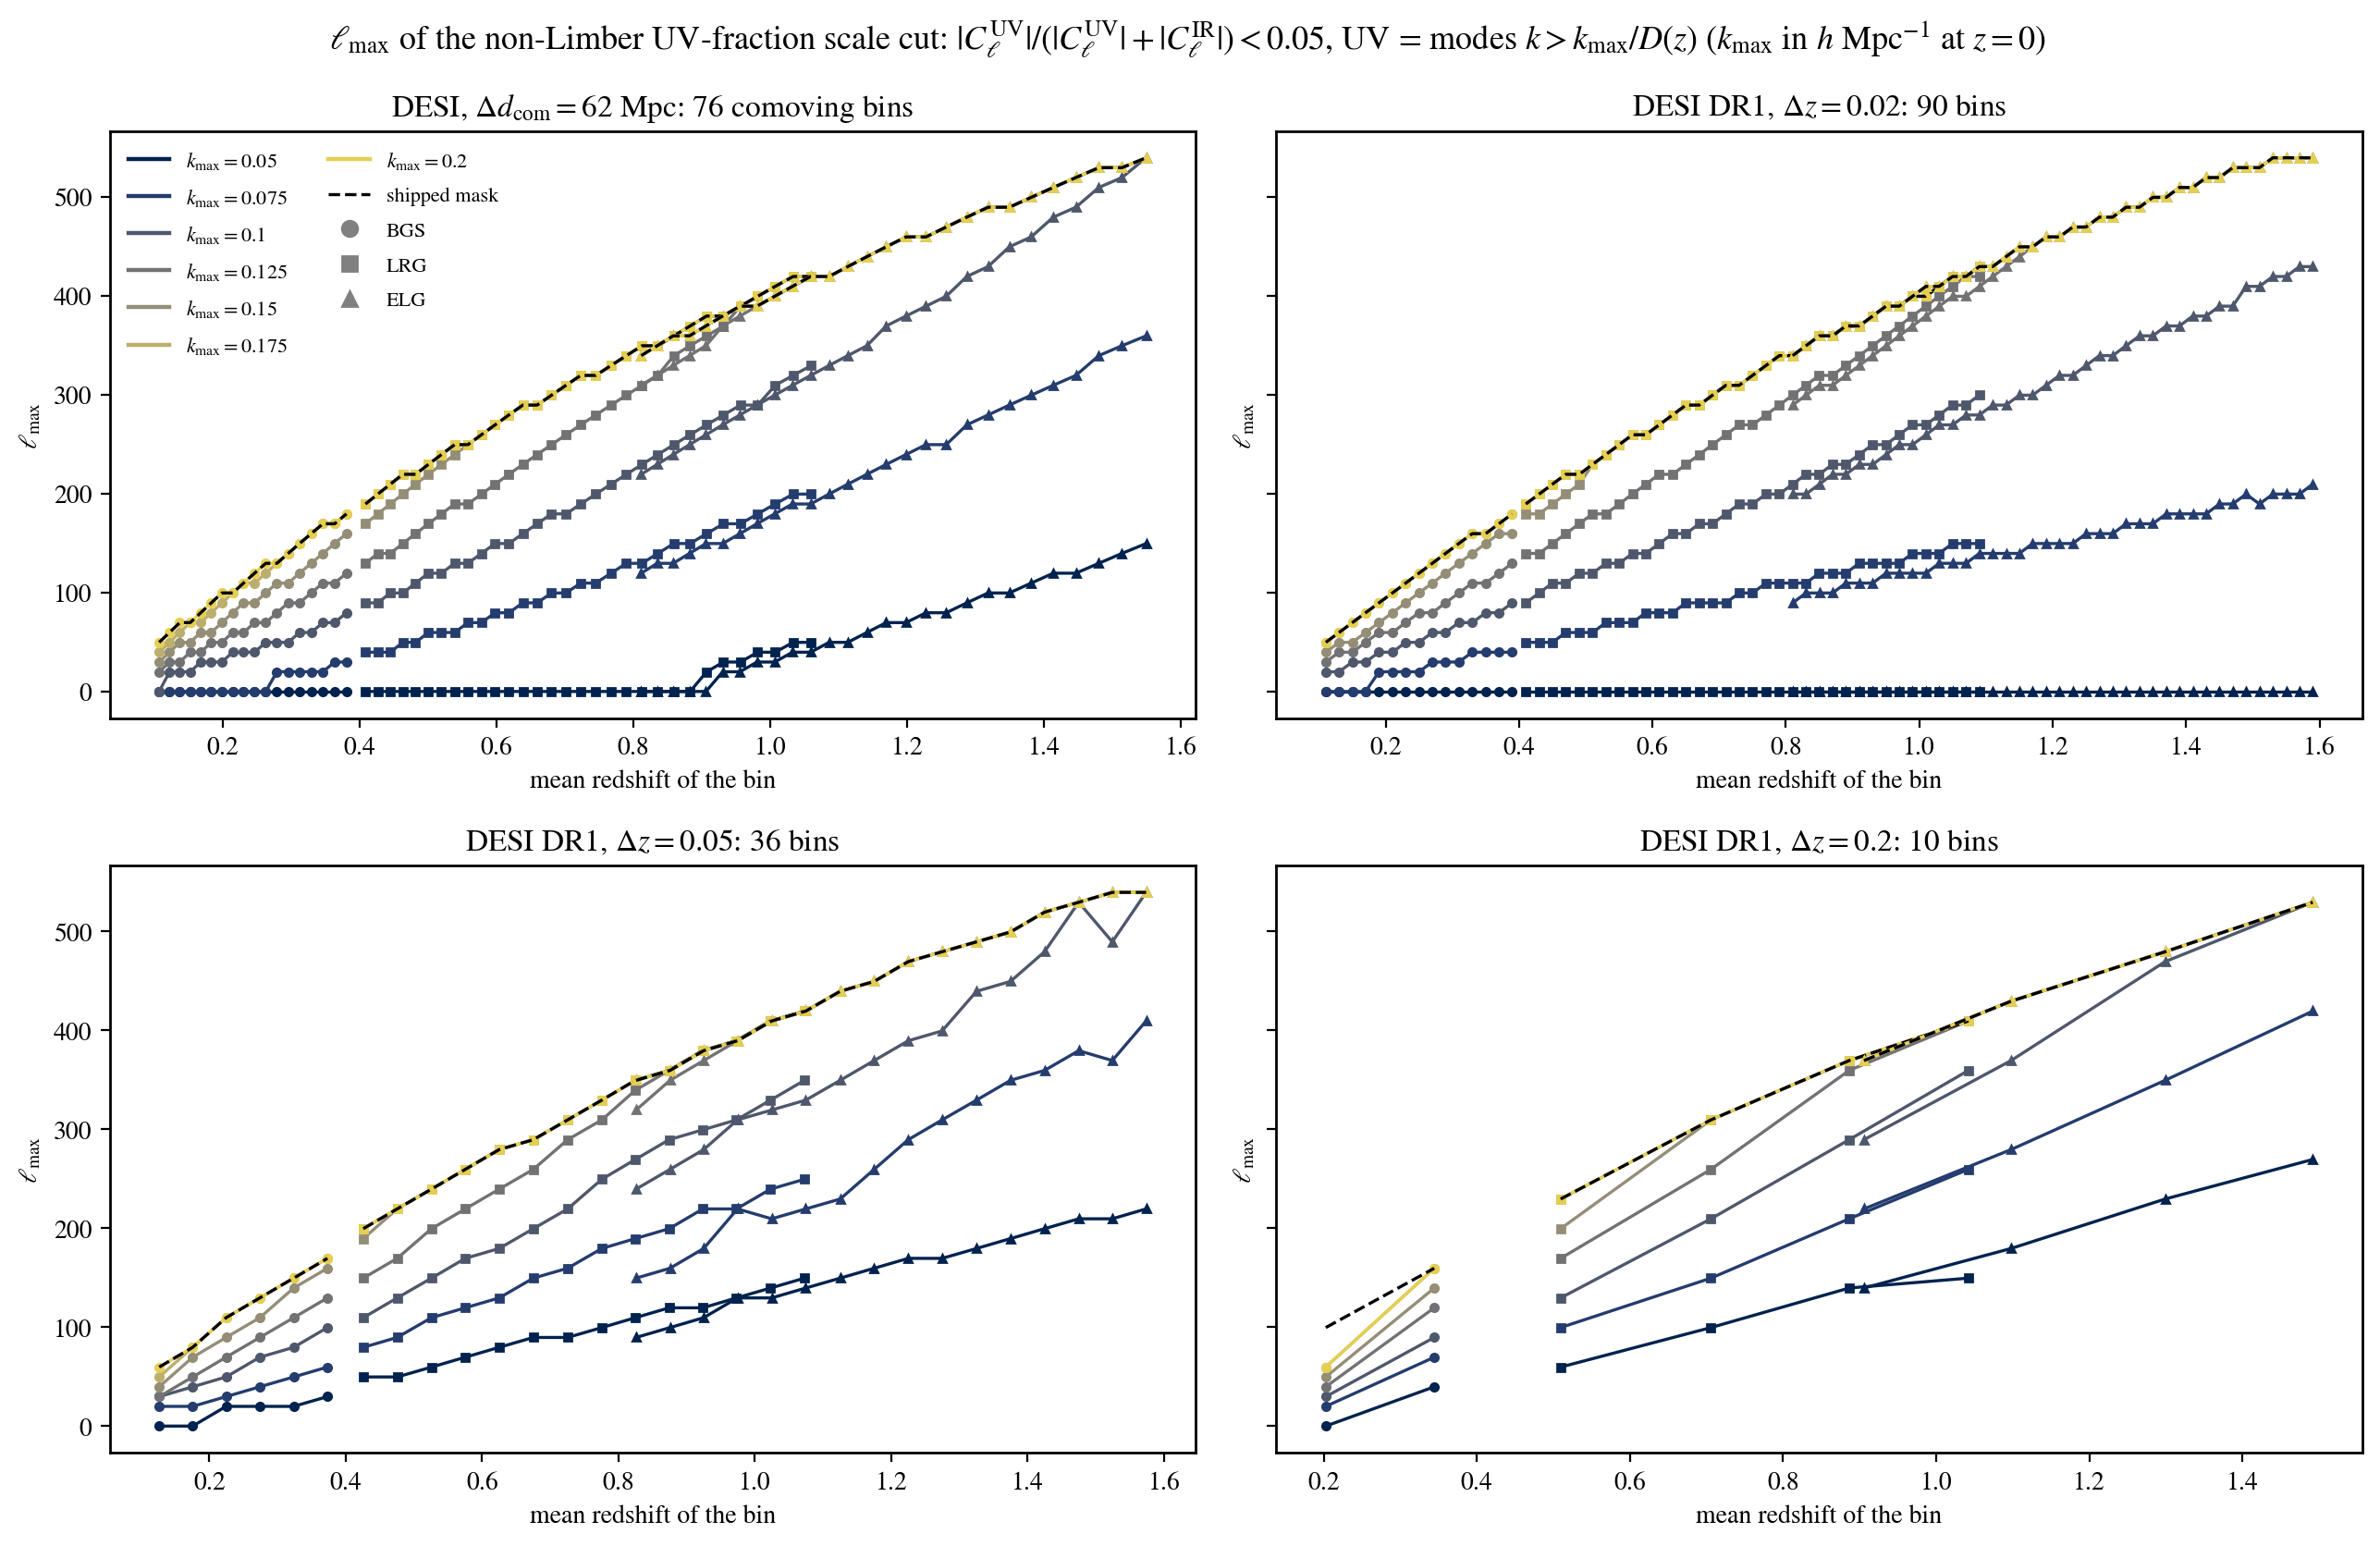

In [31]:
# ell_max of every bin's auto spectrum against the bin's mean redshift:
# one panel per layout, one color per k_max of KMAX_CUTS, and the shipped
# mask's own ell_max (the covariance has no entries beyond it, so it caps
# every cut). The samples overlap in redshift and differ in bias, so each
# sample gets its own line and marker. A bin with no band left sits at
# ell_max = 0.
from matplotlib import cm
from matplotlib.lines import Line2D

SAMPLE_MARKERS = {'bgs': 'o', 'lrg': 's', 'elg': '^'}

# the cuts shown: 0.2 h/Mpc and below (the cut cache holds larger ones)
KMAX_FIGURE_MAX = 0.2
KMAX_SHOWN = KMAX_CUTS[KMAX_CUTS <= KMAX_FIGURE_MAX + 1.0e-9]
# cividis runs from blue to yellow, with no red or green
colors = cm.cividis(np.linspace(0.0, 0.9, len(KMAX_SHOWN)))
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5), sharey=True)
for ax, key in zip(axes.ravel(), LAYOUT_DATASETS):
    cuts = scale_cuts[key]
    cov = layout_covariance(key)
    nautos = cuts['nautos']
    ells = cuts['ell']
    zbar = np.array([float(row[4]) for row in cov['bins']])
    sample = np.array([row[1].lower() for row in cov['bins']])
    shipped = cov['mask'][cov['n_ee']:cov['n_ee'] + nautos*len(ells)]
    shipped = shipped.reshape(nautos, len(ells))
    shipped_lmax = np.array([ells[row].max() if row.any() else 0.0 for row in shipped])
    for s, marker in SAMPLE_MARKERS.items():
        rows = np.where(sample == s)[0]
        if len(rows) == 0:
            continue
        rows = rows[np.argsort(zbar[rows])]
        for m, kmax in enumerate(KMAX_SHOWN):
            lmax = np.minimum(cuts['lmax'][rows, m], shipped_lmax[rows])
            ax.plot(zbar[rows], lmax, color=colors[m], marker=marker, ms=3,
                    lw=1.2)
        ax.plot(zbar[rows], shipped_lmax[rows], color='black', ls='--', lw=1.2)
    ax.set_title(LAYOUTS[key]['title'])
    ax.set_xlabel(r'mean redshift of the bin')
    ax.set_ylabel(r'$\ell_\mathrm{max}$')
handles = []
for m, kmax in enumerate(KMAX_SHOWN):
    handles.append(Line2D([], [], color=colors[m], lw=1.6,
                          label=f'$k_{{\\max}} = {kmax:g}$'))
handles.append(Line2D([], [], color='black', ls='--', lw=1.2,
                      label='shipped mask'))
for s, marker in SAMPLE_MARKERS.items():
    handles.append(Line2D([], [], color='gray', marker=marker, ls='none',
                          label=s.upper()))
axes[0][0].legend(handles=handles, fontsize=8, ncol=2, frameon=False)
fig.suptitle(rf'$\ell_\mathrm{{max}}$ of the non-Limber UV-fraction scale cut: '
             rf'$|C_\ell^\mathrm{{UV}}|/(|C_\ell^\mathrm{{UV}}| + |C_\ell^\mathrm{{IR}}|) < {ALPHA_UV}$, '
             r'UV = modes $k > k_\mathrm{max}/D(z)$ '
             r'($k_\mathrm{max}$ in $h$ Mpc$^{-1}$ at $z = 0$)', fontsize=13)
fig.tight_layout()
plt.show()

The last step rebuilds the Fisher matrix of DESI $C_\ell^{gg}$
alone at each $k_\mathrm{max}$, from the cached derivatives and the inverse
of the kept block of the covariance - the cut removes rows and columns of the
covariance before inverting it, which is not the same as truncating the full
inverse - keeping the Gaussian priors on the velocity dispersions. A
galaxy-bias parameter whose bins lost every band has a flat prior and no
data: its derivative on the kept band powers is round-off (below
`DEAD_BIAS_TOLERANCE` = $10^{-10}$ of its largest entry), so the fit drops it,
and the cosmology is unchanged. When no band power survives at all there is no
$w_0$ - $w_a$ constraint left, so the figure of merit is reported as 0:
$\Delta z = 0.02$ at $k_\mathrm{max} = 0.05\,h$ Mpc$^{-1}$. The FoMs are cached
in `chains/EXAMPLE_EVALUATE_FISHER_FOM_SCALE_CUTS.pkl` with the sha256 of every
layout's covariance file, so a regenerated covariance recomputes them.

Read the figure as information against scale. The model is linear galaxy bias
times the nonlinear matter power, and that model is accurate only up to about
$k = 0.08$-$0.12\,h$ Mpc$^{-1}$; on smaller scales the neglected
second-order bias, counterterms and stochastic terms matter, and holding them
at zero turns modeling error into apparent information. The left part of each
curve is therefore the trusted region for this model; using the full
shipped range requires the higher-order galaxy bias model, the next modeling
step. Inside that window, at $k_\mathrm{max} = 0.1\,h$
Mpc$^{-1}$, the FoM is 7.68 on $\Delta d_\mathrm{com} = 62$ Mpc, 11.9 on $\Delta z = 0.02$, 4.09 on
$\Delta z = 0.05$ and 1.17 on $\Delta z = 0.2$. The figure stops at
$k_\mathrm{max} = 0.2\,h$ Mpc$^{-1}$, where the FoM reaches 26.1, 29.8, 10.5 and
2.14; the table above also carries the values at the shipped masks
(28.0, 30.4, 10.9 and 2.43). The $y$ axis is logarithmic, from 0.05
to 100; a FoM of 0 has no place on a log axis, so the $\Delta z = 0.02$ point at
$k_\mathrm{max} = 0.05\,h$ Mpc$^{-1}$ is left off its curve and marked "no band
left". The dashed gray line is a fixed reference, not cut in $k_\mathrm{max}$:
LSST Y1 3x2pt at FoM$(w_0, w_a) = 17.3$, the lsst_y1 project's real-space Fisher
forecast of the SRD Y1 setup with that project's own scale cuts (section 18 of
its EXAMPLE_EVALUATE2.ipynb reports 17.26; its fiducial has $w_0 = -0.9$ against
$-1$ here, and this notebook's own LSST Y1 3x2pt in band powers gives 17.4 in
section 4, so the reference is consistent). DESI $C_\ell^{gg}$ alone passes it
between $k_\mathrm{max} = 0.1$ and $0.125\,h$ Mpc$^{-1}$ on $\Delta z = 0.02$
(FoM 11.9 and 18.6 there) and between 0.125 and $0.15\,h$ Mpc$^{-1}$ on
$\Delta d_\mathrm{com} = 62$ Mpc (14.1 and 20.8); $\Delta z = 0.05$, at most
10.9 on the shipped mask, and $\Delta z = 0.2$, at most 2.43, never pass it.

Delta d_com = 62 Mpc: 51 s


Delta z = 0.02: 126 s


Delta z = 0.05: 6 s


Delta z = 0.2: 0 s


FoM(w0, wa) of DESI C_gg alone; columns: k_max [h/Mpc at z = 0]


,0.05,0.075,0.1,0.125,0.15,0.175,0.2,shipped
Delta d_com = 62 Mpc,0.06136,2.977,7.676,14.05,20.82,24.18,26.11,28.03
Delta z = 0.02,0,2.667,11.86,18.64,24.55,28.02,29.75,30.43
Delta z = 0.05,0.4183,2.044,4.088,6.908,9.024,10.1,10.48,10.89
Delta z = 0.2,0.2056,0.6512,1.167,1.537,1.901,2.124,2.138,2.429


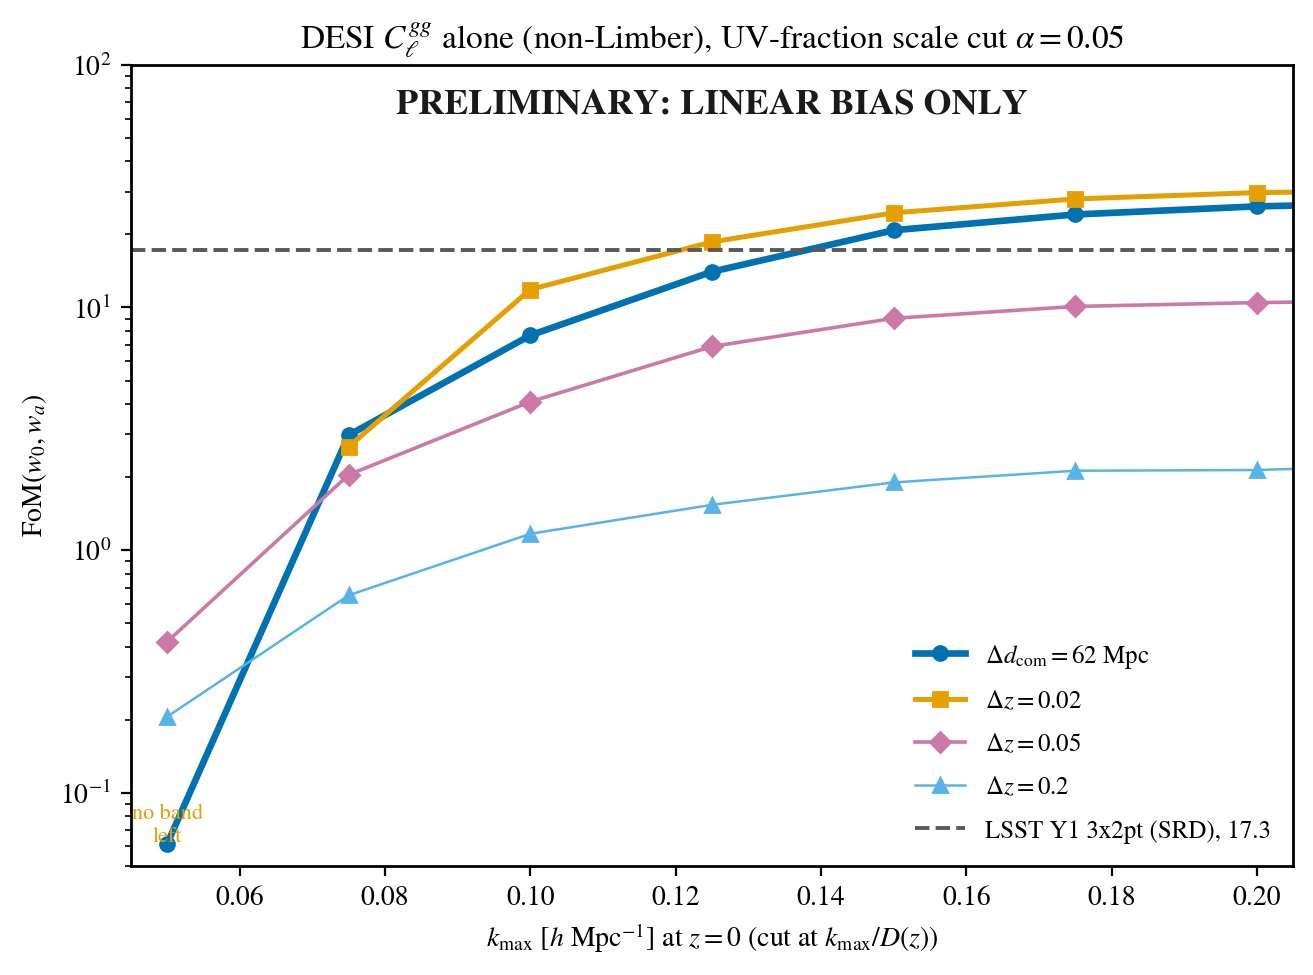

In [32]:
# FoM(w0, wa) of DESI C_gg alone at each k_max of KMAX_CUTS. The Fisher
# matrix is rebuilt from the cached derivatives with the inverse of the
# kept block of the covariance (shipped mask AND the UV-fraction cut): the cut
# removes rows and columns of the covariance before inverting it. The
# Gaussian priors on the velocity dispersions are kept. The FoMs depend on
# the covariance and the derivatives as well as on the cuts, so the cache
# stores the sha256 of every layout's covariance file and of its derivative
# matrix next to the cut settings, and a cache made with other settings,
# another covariance or other derivatives is recomputed.
FOM_CUTS_CACHE = (ROOTDIR + '/projects/lssty1xdesi/chains/'
                  'EXAMPLE_EVALUATE_FISHER_FOM_SCALE_CUTS.pkl')
RECOMPUTE_FOM_CUTS = RECOMPUTE_CUTS
# a group-bias derivative entry below this fraction of the column's largest
# entry is round-off: the stencil derivative of a group bias on the spectra
# of other groups' bins stays below 5e-14 of its own entries on every layout
DEAD_BIAS_TOLERANCE = 1.0e-10


def scale_cut_fom(key):
    '''FoM(w0, wa) of DESI C_gg alone at every k_max of KMAX_CUTS.'''
    res = layout_desi[key]
    D = np.array(res['D'][H_MAIN])
    names = list(res['names'])
    F_full = np.array(res['F'][H_MAIN])
    scale = AREA_DEG2/DESI_COV_AREA_DEG2
    cov = layout_covariance(key)
    # the Gaussian priors of the example yaml (refresh_fisher): the velocity
    # dispersions; every other parameter has a flat prior
    priors = np.diag(res['prior'])
    out = {'fom': [], 'entries': []}
    for m in range(len(KMAX_CUTS)):
        mask, _ = combined_mask(key, m)
        kept = np.where(mask)[0]
        F = D[kept].T @ np.linalg.inv(cov['C'][np.ix_(kept, kept)]) @ D[kept]*scale + priors
        # a galaxy bias whose bins lost every band power has no data and a
        # flat prior. Its stencil derivative on the kept entries (spectra of
        # other groups' bins) is then round-off, not zero, so the bias is
        # dropped when those entries stay below DEAD_BIAS_TOLERANCE times its
        # largest entry. Dropping it leaves the cosmology unchanged; keeping
        # it would leave a direction with no information, and the inverse
        # of the then singular matrix would be round-off too.
        live = []
        for j in range(len(names)):
            if names[j].startswith('DESI_B1_'):
                column = np.abs(D[:, j])
                if len(kept) == 0 or (np.max(column[kept])
                                      <= DEAD_BIAS_TOLERANCE*np.max(column)):
                    continue
            if np.any(F[j] != 0.0):
                live.append(j)
        F_live = F[np.ix_(live, live)]
        names_live = [names[j] for j in live]
        if all(p in names_live for p in COSMO):
            out['fom'].append(cosmo_errors(F_live, names_live)[1])
        else:
            # no band power left: nothing constrains the cosmology, FoM = 0
            out['fom'].append(0.0)
        out['entries'].append(len(kept))
    out['fom_shipped'] = cosmo_errors(F_full, names)[1]
    return out


fom_settings_now = {}
for key in LAYOUT_DATASETS:
    entry = dict(settings_now[key])
    entry['covariance_sha256'] = covariance_sha256(LAYOUT_DATASETS[key])
    derivatives = np.ascontiguousarray(layout_desi[key]['D'][H_MAIN], dtype=np.float64)
    entry['derivative_sha256'] = hashlib.sha256(derivatives.tobytes()).hexdigest()
    entry['dead_bias_tolerance'] = DEAD_BIAS_TOLERANCE
    fom_settings_now[key] = entry
fom_cuts = None
if not RECOMPUTE_FOM_CUTS and os.path.exists(FOM_CUTS_CACHE):
    with open(FOM_CUTS_CACHE, 'rb') as f:
        cached = pickle.load(f)
    if cached['settings'] == fom_settings_now:
        fom_cuts = cached['fom']
    else:
        print(f'{FOM_CUTS_CACHE} holds the FoMs of other cut settings or another '
              'covariance: recomputing them', flush=True)
if fom_cuts is None:
    fom_cuts = {}
    for key in LAYOUT_DATASETS:
        start = time.time()
        fom_cuts[key] = scale_cut_fom(key)
        print(f'{key}: {time.time() - start:.0f} s', flush=True)
    with open(FOM_CUTS_CACHE, 'wb') as f:
        pickle.dump({'fom': fom_cuts, 'settings': fom_settings_now}, f)

fom_table = {}
for key in LAYOUT_DATASETS:
    row = {}
    # the table stops at 0.2 h/Mpc, like the figure
    for m, kmax in enumerate(KMAX_CUTS):
        if kmax <= 0.2 + 1.0e-9:
            row[kmax] = fom_cuts[key]['fom'][m]
    row['shipped'] = fom_cuts[key]['fom_shipped']
    fom_table[key] = row
print('FoM(w0, wa) of DESI C_gg alone; columns: k_max [h/Mpc at z = 0]')
display(pd.DataFrame(fom_table).T)

# LSST Y1 3x2pt in real space, the SRD Y1 setup with its own scale cuts: the
# Fisher forecast of the lsst_y1 project (EXAMPLE_EVALUATE2.ipynb, section
# 18; fiducial w0 = -0.9). A fixed reference, not cut in k_max; this
# notebook's own LSST Y1 3x2pt in band powers gives 17.4 (section 4).
LSST_Y1_SRD_FOM = 17.26

fiducial = dict(zip(desi['names'], desi['fiducial']))
fig, ax = plt.subplots(figsize=(7.5, 5.2))
for key in LAYOUT_DATASETS:
    fom = np.array(fom_cuts[key]['fom'], dtype=float)
    # a FoM of 0 (no band power left) has no place on a log axis: the
    # curve skips it and a note marks the k_max
    ax.plot(KMAX_CUTS, np.where(fom > 0.0, fom, np.nan),
            color=LAYOUT_COLORS[key], marker=LAYOUT_STYLE[key]['marker'], ms=5,
            lw=LAYOUT_STYLE[key]['lw'], label=LAYOUT_LABELS[key])
    for kmax, value in zip(KMAX_CUTS, fom):
        if value == 0.0:
            ax.text(kmax, 0.06, 'no band\nleft', color=LAYOUT_COLORS[key],
                    fontsize=8, ha='center', va='bottom')
ax.axhline(LSST_Y1_SRD_FOM, color='0.35', ls='--', lw=1.4,
           label=f'LSST Y1 3x2pt (SRD), {LSST_Y1_SRD_FOM:.1f}')
ax.set_yscale('log')
ax.set_ylim(0.05, 100.0)
# the k_max range of the figure stops at 0.2 h/Mpc
ax.set_xlim(0.045, 0.205)
# the galaxy model is linear bias times the nonlinear matter power: a
# preliminary read until the higher-order bias model is in place
ax.text(0.5, 0.97, 'PRELIMINARY: LINEAR BIAS ONLY', transform=ax.transAxes,
        ha='center', va='top', fontsize=13, fontweight='bold',
        color='0.1')
ax.set_xlabel(r'$k_\mathrm{max}$ [$h$ Mpc$^{-1}$] at $z = 0$ (cut at $k_\mathrm{max}/D(z)$)')
ax.set_ylabel(r'FoM$(w_0, w_a)$')
ax.set_title(rf'DESI $C_\ell^{{gg}}$ alone (non-Limber), UV-fraction scale cut '
             rf'$\alpha = {ALPHA_UV}$')
ax.legend(fontsize=9, loc='lower right', frameon=False)
plt.show()

### How much bias freedom costs

**Preliminary: linear bias only.** As in the rest of this section, the galaxy
model is linear bias times the nonlinear matter power spectrum, so every FoM
of this subsection is a preliminary read of the information content.

Every forecast above ties the bins of a tracer group to one amplitude: bin
$i$ of group $g$ has linear bias

$$b_i = \frac{B_g}{D(z_i)},$$

with $B_g$ a free amplitude per group (6 groups on every layout), $z_i$ the
bin's mean redshift and $D(z)$ the linear growth factor, normalized to
$D(0) = 1$. The $1/D$ shape keeps the group's clustering amplitude
$b(z)\,D(z)$ constant. That is an assumption, not a law: a conserved
population, whose excess clumping the continuity equation freezes, has
$b - 1 \propto 1/D$ instead and drifts away from the constant-amplitude
shape by a few percent across a group, and a DESI sample is selected rather
than conserved, so its flux limits and color cuts move the bias further.
Part of the FoM of the thin layouts could therefore rest on the tying
itself.

This subsection measures how much. Three bias models share the same data
and the same derivatives: the tied model above, one independent bias per
bin with a flat prior, and an intermediate model in which bins may deviate
from the group's trend but neighboring bins must deviate together.
Everything runs on DESI $C_\ell^{gg}$ alone (non-Limber) at the UV-fraction
cut $k_\mathrm{max} = 0.075\,h$ Mpc$^{-1}$ of the previous subsection,
inside the window where linear bias can be trusted. The derivations and the
literature behind the intermediate model are in the project note
`notes/correlated_bias_prior_v2/correlated_bias_prior_v2.pdf` (its appendix
"The models"); this subsection quotes its results and does not repeat the
derivations.

The first ingredient is the derivative of the DESI data vector with respect
to every bin's own bias amplitude; the cached Fisher derivatives vary only
the six group amplitudes. Two facts keep the cost down. Each band power of
a bin pair is at most quadratic in the two biases (the $b_i b_j$ density
term and the $b_i f$ redshift-space terms, with $f$ the growth rate), so the
five-point stencil of every derivative of this project is exact here up to
round-off, whatever the step.
And bins that share no measured cross spectrum can be stepped together,
because every spectrum then involves at most one stepped bin; a greedy
coloring of the pair graph splits the bins into a few such sets, so a
layout costs four model evaluations per set instead of four per bin (76 bins
on $\Delta d_\mathrm{com} = 62$ Mpc). The table below is the check: the
per-bin columns of a group, summed, must reproduce the cached column of the
group's amplitude, because the tied amplitude moves all its bins at once.
The last column is the worst relative difference over the groups.

In [33]:
# The derivatives of each layout's DESI vector with respect to every bin's
# own bias amplitude DESI_B1_i (b_i = DESI_B1_i/D(z_i)), for the experiment
# below where the bins of a group no longer share one bias.
#
# C_l of a pair of bins is at most quadratic in their biases (the b_i b_j
# density term and the b f RSD terms), so the five-point stencil of every
# derivative here (fm.FIVE_POINT_OFFSETS) is exact for it up to round-off.
# Scaling the biases of a set of bins that share no measured cross pair by
# (1 + o BIN_BIAS_STEP), o = +-1, +-2, then gives b_i dm/db_i for every bin
# of the set from four evaluations: each spectrum involves at most one bin
# of the set. A greedy coloring of the pair graph picks the sets (a few
# colors), so a layout costs a handful of evaluations instead of one model
# per bin. The step reaches the compiled interface through a wrapper of
# ci.set_nuisance_bias, the call where the likelihood hands over the
# per-bin biases.
#
# Check: the per-bin columns of each group sum to the group's own column of
# the cached Fisher derivatives (the tied bias moves all its bins at once).
import re

BIN_BIAS_STEP = 0.01
BIN_BIAS_CACHE = (ROOTDIR + '/projects/lssty1xdesi/chains/'
                  'EXAMPLE_EVALUATE_FISHER_BIN_BIAS.pkl')
RECOMPUTE_BIN_BIAS = False


def bin_bias_settings(key):
    '''The model settings of one layout's derivatives: its Fisher ones.'''
    if key in LAYOUT_FISHER_OVERRIDES:
        settings = {'yaml': LAYOUTS[key]['yaml'],
                    'likelihood_overrides': dict(LAYOUT_FISHER_OVERRIDES[key]),
                    'camb_overrides': dict(LAYOUT_FISHER_CAMB),
                    'accuracy_boost': LAYOUT_ACCURACY_BOOST}
    else:
        settings = {'yaml': LAYOUTS[key]['yaml'],
                    'likelihood_overrides': dict(DESI_FISHER_OVERRIDES),
                    'camb_overrides': dict(DESI_FISHER_CAMB),
                    'accuracy_boost': DESI_FISHER_BOOST}
    settings['step'] = BIN_BIAS_STEP
    settings['stencil'] = 'five-point'
    settings['tier'] = DERIVATIVE_TIER
    settings['fingerprint'] = fm.settings_fingerprint(
        settings['yaml'], likelihood_overrides=settings['likelihood_overrides'],
        accuracy_boost=settings['accuracy_boost'],
        camb_overrides=settings['camb_overrides'], tier=DERIVATIVE_TIER)
    return settings


def bias_leaders(key):
    '''The group leader of every bin bias, from the layout's params file.

    Returns:
      list: leader[i] = the sampled DESI_B1_<n> that bin i + 1 is tied to.
    '''
    params = yaml_load_file(LAYOUTS[key]['bias_params'])
    params = params.get('params', params)
    leader = {}
    for name, spec in params.items():
        if not name.startswith('DESI_B1_'):
            continue
        value = str(spec.get('value', '')) if isinstance(spec, dict) else ''
        found = re.search(r'lambda\s+(DESI_B1_\d+)\s*:', value)
        leader[name] = found.group(1) if found else name
    return [leader[f'DESI_B1_{i + 1}'] for i in range(len(leader))]


def bin_bias_derivatives(key):
    '''d m / d DESI_B1_i for every bin i of one layout, and the check.

    Returns:
      dict: 'D' (n x nbins), 'leaders' (per bin), 'colors' (number of
      bin sets) and 'check' ({leader: max |sum of its bins' columns -
      cached group column| / max |cached group column|}).
    '''
    settings = bin_bias_settings(key)
    cov = layout_covariance(key)
    nbins = len(cov['bins'])
    nell = len(cov['ells'])
    pairs = [(int(r[0]), int(r[1])) for r in cov['pairs']]
    leaders = bias_leaders(key)
    # greedy coloring: no pair joins two bins of one color
    neighbors = [set() for _ in range(nbins)]
    for a, b in pairs:
        neighbors[a].add(b)
        neighbors[b].add(a)
    color = []
    for i in range(nbins):
        used = {color[j] for j in neighbors[i] if j < i}
        c = 0
        while c in used:
            c += 1
        color.append(c)
    model = fm.ModelFisher(settings['yaml'], COSMO, extra_prefixes=('DESI_',),
                           likelihood_overrides=settings['likelihood_overrides'],
                           accuracy_boost=settings['accuracy_boost'],
                           camb_overrides=settings['camb_overrides'])
    m0 = np.array(model.dv())
    fiducial = dict(zip(model.names, model.fiducial))
    n = len(m0)
    n_ee = cov['n_ee']
    # the data-vector rows of every spectrum that involves bin i
    rows = []
    for i in range(nbins):
        r = list(range(n_ee + i*nell, n_ee + (i + 1)*nell))
        for p, (a, b) in enumerate(pairs):
            if i in (a, b):
                start = n_ee + (nbins + p)*nell
                r += list(range(start, start + nell))
        rows.append(np.array(r))
    original = fm.ci.set_nuisance_bias
    factor = {'s': None}

    def scaled(**kw):
        if factor['s'] is not None:
            kw['B1'] = np.asarray(kw['B1'], dtype=float)*factor['s']
        return original(**kw)

    D = np.zeros((n, nbins))
    fm.ci.set_nuisance_bias = scaled
    try:
        for c in range(max(color) + 1):
            members = [i for i in range(nbins) if color[i] == c]
            vectors = []
            for offset in fm.FIVE_POINT_OFFSETS:
                s = np.ones(nbins)
                s[members] = 1.0 + offset*BIN_BIAS_STEP
                factor['s'] = s
                vectors.append(np.array(model.dv()))
            d = fm.five_point(vectors, BIN_BIAS_STEP)  # b_i dm/db_i
            for i in members:
                # b_i dm/db_i = DESI_B1_i dm/dDESI_B1_i
                D[rows[i], i] = d[rows[i]]/fiducial[leaders[i]]
    finally:
        fm.ci.set_nuisance_bias = original
        factor['s'] = None
    del model
    res = layout_desi[key]
    D_cached = np.array(res['D'][H_MAIN])
    names = list(res['names'])
    live = m0 != 0.0
    check = {}
    for ld in dict.fromkeys(leaders):
        members = [i for i in range(nbins) if leaders[i] == ld]
        ref = D_cached[:, names.index(ld)]
        diff = D[:, members].sum(axis=1) - ref
        check[ld] = float(np.max(np.abs(diff[live]))/np.max(np.abs(ref[live])))
    return {'D': D, 'leaders': leaders, 'colors': max(color) + 1, 'check': check}


bin_settings_now = {key: bin_bias_settings(key) for key in LAYOUT_DATASETS}
if RECOMPUTE_BIN_BIAS or not os.path.exists(BIN_BIAS_CACHE):
    bin_bias = {}
    for key in LAYOUT_DATASETS:
        start = time.time()
        bin_bias[key] = bin_bias_derivatives(key)
        print(f'{key}: {bin_bias[key]["colors"]} bin sets, '
              f'{time.time() - start:.0f} s', flush=True)
    with open(BIN_BIAS_CACHE, 'wb') as f:
        pickle.dump({'bin_bias': bin_bias, 'settings': bin_settings_now}, f)
else:
    with open(BIN_BIAS_CACHE, 'rb') as f:
        cached = pickle.load(f)
    if cached['settings'] != bin_settings_now:
        raise RuntimeError(f'{BIN_BIAS_CACHE} holds other settings: set '
                           'RECOMPUTE_BIN_BIAS = True to rebuild it')
    bin_bias = cached['bin_bias']

check_table = {}
for key in LAYOUT_DATASETS:
    check_table[key] = {'bins': len(bin_bias[key]['leaders']),
                        'bin sets': bin_bias[key]['colors'],
                        'max |sum - group column|': max(bin_bias[key]['check'].values())}
print('per-bin bias derivatives, summed over each group, against the cached '
      'group columns:')
display(pd.DataFrame(check_table).T)

per-bin bias derivatives, summed over each group, against the cached group columns:


,bins,bin sets,max |sum - group column|
Delta d_com = 62 Mpc,76,4,5.964e-13
Delta z = 0.02,90,4,5.651e-13
Delta z = 0.05,36,4,3.754e-13
Delta z = 0.2,10,4,4.214e-13


The same derivatives feed two Fisher matrices per layout: the biases tied
per group (6 amplitudes, the model of every table above) and one
independent bias per bin with a flat prior. Both keep the cosmology, the
velocity dispersions per group and their Gaussian priors. The table runs
over every $k_\mathrm{max}$ of the scan; the bar chart reads out
$k_\mathrm{max} = 0.075\,h$ Mpc$^{-1}$, where the FoM falls from 2.977 to
1.386 on $\Delta d_\mathrm{com} = 62$ Mpc, from 2.667 to 1.150 on
$\Delta z = 0.02$, from 2.044 to 0.349 on $\Delta z = 0.05$ and from 0.6512 to
0.1776 on $\Delta z = 0.2$: a factor of 2.1 to 5.9, and at this cut no layout
reaches the LSST Y1 3x2pt reference even with tied biases. The ordering of
the layouts survives, but the absolute FoM of a thin-bin forecast depends
on the bias model as strongly as on the binning. Neither extreme is the
physical answer, so the next cells price the ground between them.

FoM(w0, wa) of DESI C_gg alone; columns: k_max [h/Mpc at z = 0]


0.05   0.075  0.1    0.125  0.15   \
Delta d_com = 62 Mpc tied per group      0.06136  2.977  7.676  14.05  20.82   
                     independent per bin 0.01159  1.386  3.416  8.131  12.67   
Delta z = 0.02       tied per group            0  2.667  11.86  18.64  24.55   
                     independent per bin       0   1.15   6.85  11.69  15.93   
Delta z = 0.05       tied per group       0.4183  2.044  4.088  6.908  9.024   
                     independent per bin 0.09882 0.3488  1.113   2.43  3.464   
Delta z = 0.2        tied per group       0.2056 0.6512  1.167  1.537  1.901   
                     independent per bin 0.06698 0.1776 0.3213 0.4339 0.6084   

                                          0.175  0.2    0.225  0.25   
Delta d_com = 62 Mpc tied per group       24.18  26.11  27.09  27.89  
                     independent per bin  15.32  15.94  16.38  16.59  
Delta z = 0.02       tied per group       28.02  29.75  30.43  30.43  
                     independent per bin  17.99  19.16  19.34  19.34  
Delta z = 0.05       tied per group        10.1  10.48  10.72  10.73  
                     independent per bin  4.021  4.166  4.296  4.299  
Delta z = 0.2        tied per group       2.124  2.138   2.26  2.349  
                     independent per bin 0.6732 0.6824 0.7091 0.7329

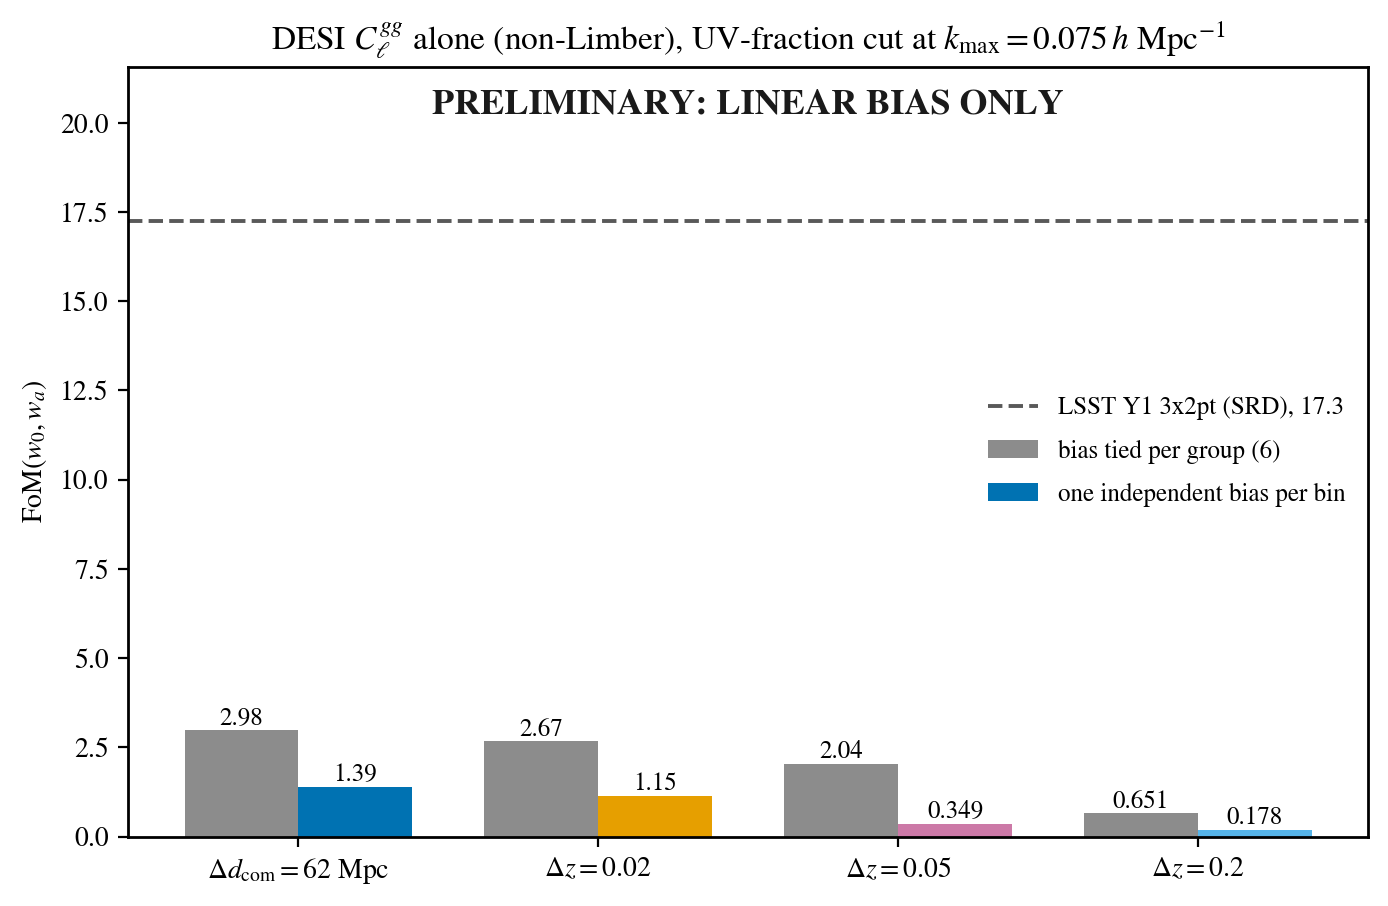

In [34]:
# FoM(w0, wa) of DESI C_gg alone with the galaxy biases tied per group (6
# amplitudes, the default model) against one independent bias per bin (the
# same fiducial values, flat priors), at the UV-fraction cuts of KMAX_CUTS.
# Both keep the cosmology, the velocity dispersions per group and their
# Gaussian priors. bin_bias_precision adds a prior on the bin biases (an
# nbins x nbins precision matrix; None = flat), the hook for correlated
# neighboring bins.
KMAX_BIAS = 0.075  # h/Mpc at z = 0: where linear bias is still defensible


def fom_bin_biases(key, k_index, bin_bias_precision=None):
    '''FoM(w0, wa) of DESI C_gg alone with one bias per bin.

    Arguments:
      key       = a LAYOUT_DATASETS key.
      k_index   = the index of the cut in KMAX_CUTS.
      bin_bias_precision = optional (nbins, nbins) prior precision on the
                  bin biases DESI_B1_i; None = flat priors.

    Returns:
      the FoM, 0 when no band power survives the cut.
    '''
    res = layout_desi[key]
    names_tied = list(res['names'])
    D_tied = np.array(res['D'][H_MAIN])
    cov = layout_covariance(key)
    scale = AREA_DEG2/DESI_COV_AREA_DEG2
    # the Gaussian priors of the tied names, from the example yaml
    # (refresh_fisher): the velocity dispersions
    prior_diag = np.array(res['prior'])
    keep_cols = [j for j, nm in enumerate(names_tied) if not nm.startswith('DESI_B1_')]
    nbins = bin_bias[key]['D'].shape[1]
    names = [names_tied[j] for j in keep_cols] + [f'DESI_B1_{i + 1}' for i in range(nbins)]
    D = np.hstack([D_tied[:, keep_cols], bin_bias[key]['D']])
    priors = np.zeros((len(names), len(names)))
    priors[:len(keep_cols), :len(keep_cols)] = np.diag(prior_diag[keep_cols])
    if bin_bias_precision is not None:
        priors[len(keep_cols):, len(keep_cols):] += bin_bias_precision
    mask, _ = combined_mask(key, k_index)
    kept = np.where(mask)[0]
    F = D[kept].T @ np.linalg.inv(cov['C'][np.ix_(kept, kept)]) @ D[kept]*scale + priors
    # a bias whose bin lost every band power has no data and a flat prior
    live = [j for j in range(len(names)) if np.any(F[j] != 0.0)]
    F_live = F[np.ix_(live, live)]
    names_live = [names[j] for j in live]
    if not all(p in names_live for p in COSMO):
        return 0.0
    return cosmo_errors(F_live, names_live)[1]


bias_table = {}
for key in LAYOUT_DATASETS:
    for m, kmax in enumerate(KMAX_CUTS):
        bias_table[(key, 'tied per group')] = bias_table.get((key, 'tied per group'), {})
        bias_table[(key, 'independent per bin')] = bias_table.get((key, 'independent per bin'), {})
        bias_table[(key, 'tied per group')][kmax] = fom_cuts[key]['fom'][m]
        bias_table[(key, 'independent per bin')][kmax] = fom_bin_biases(key, m)
print('FoM(w0, wa) of DESI C_gg alone; columns: k_max [h/Mpc at z = 0]')
display(pd.DataFrame(bias_table).T)

m_bias = int(np.argmin(np.abs(KMAX_CUTS - KMAX_BIAS)))
x = np.arange(len(LAYOUT_DATASETS))
tied = [bias_table[(key, 'tied per group')][KMAX_CUTS[m_bias]] for key in LAYOUT_DATASETS]
indep = [bias_table[(key, 'independent per bin')][KMAX_CUTS[m_bias]] for key in LAYOUT_DATASETS]
fig, ax = plt.subplots(figsize=(8, 5))
width = 0.38
bars_t = ax.bar(x - width/2, tied, width=width, color='0.55', label='bias tied per group (6)')
bars_i = ax.bar(x + width/2, indep, width=width,
                color=[LAYOUT_COLORS[key] for key in LAYOUT_DATASETS],
                label='one independent bias per bin')
for bars in (bars_t, bars_i):
    for b in bars:
        ax.text(b.get_x() + b.get_width()/2, b.get_height(), f'{b.get_height():.3g}',
                ha='center', va='bottom', fontsize=9)
ax.axhline(LSST_Y1_SRD_FOM, color='0.35', ls='--', lw=1.4,
           label=f'LSST Y1 3x2pt (SRD), {LSST_Y1_SRD_FOM:.1f}')
ax.set_xticks(x)
ax.set_xticklabels([LAYOUT_LABELS[key] for key in LAYOUT_DATASETS])
ax.set_ylabel(r'FoM$(w_0, w_a)$')
ax.set_title(rf'DESI $C_\ell^{{gg}}$ alone (non-Limber), UV-fraction cut at '
             rf'$k_\mathrm{{max}} = {KMAX_CUTS[m_bias]:g}\,h$ Mpc$^{{-1}}$')
ax.text(0.5, 0.97, 'PRELIMINARY: LINEAR BIAS ONLY', transform=ax.transAxes,
        ha='center', va='top', fontsize=13, fontweight='bold', color='0.1')
ax.set_ylim(0.0, 1.25*max(max(tied), max(indep), LSST_Y1_SRD_FOM))
ax.legend(fontsize=9, loc='center right', frameon=False)
plt.show()

The intermediate model multiplies the tied bias by a fractional deviation
$\delta_i$ with a correlated Gaussian prior,

$$b_i = \frac{B_g}{D(z_i)}\,\bigl(1 + \delta_i\bigr), \qquad
\langle \delta_i\,\delta_j \rangle = \sigma_b^2\,
e^{-|z_i - z_j|/L} \ \text{(same group)},$$

and no correlation across groups. $\sigma_b$ is the prior standard
deviation of one bin's deviation; $L$ is the correlation length in
redshift, so two bins $\Delta z$ apart have correlation coefficient
$e^{-\Delta z/L}$ and their deviations differ by
$\sigma_b \sqrt{2\,(1 - e^{-\Delta z/L})}$ rms. The group amplitude $B_g$
keeps its flat prior: the uniform shift of a group is projected out of the
prior precision, so the prior charges the shape of $b(z)$ inside a group
and never its level, and the comparison against the tied model stays fair.
The note `notes/correlated_bias_prior_v2/correlated_bias_prior_v2.pdf` derives
the projection and weighs the physics: the cell scans
$\sigma_b \in \{1, 3, 5, 7, 10\}\%$ and $L \in \{0.02, 0.05, 0.1, 0.2\}$;
the plausible region is $\sigma_b = 1$-$5\%$, $L = 0.02$-$0.1$, with the
provisional baseline $L = 0.05$, $\sigma_b = 3\%$. A conserved population
drifts by about 1% per $\Delta z = 0.05$, which sets the low end of
$\sigma_b$; the measured drifts are smooth across a group and favor the
long end of the $L$ grid (the note's appendix "Which $L$ and $\sigma_b$ are
physical"). The first table is the
scan. The second table checks the limits of the construction, and both are
exact: $\sigma_b = 0.01\%$ returns the tied FoM (the shape is pinned, the
amplitude still free) and $\sigma_b = 1000\%$ the independent one.

In [35]:
# Correlated bin biases. Each bin's bias is
#
#   b_i = B_g/D(z_i) * (1 + delta_i),
#
# with B_g the group amplitude (flat prior, as in the tied model) and
# delta_i the bin's fractional deviation from the group's trend B_g/D(z_i)
# (constant clustering amplitude b D). The deviations get a Gaussian prior of rms sigma_b and a
# correlation that falls by one e-fold every L in redshift,
#
#   <delta_i delta_j> = sigma_b^2 exp(-|z_i - z_j|/L)   (same group),
#
# and zero across groups (different tracers or chunks). The correlation
# coefficient of two bins is exp(-dz/L), whatever sigma_b is; sigma_b sets
# how far each bin may wander, so two bins dz apart differ by
# sigma_b sqrt(2 (1 - exp(-dz/L))), about sigma_b sqrt(2 dz/L) for dz << L.
# In one dimension this exponential kernel is a Markov chain: its inverse
# couples only adjacent bins.
#
# The group amplitude stays free: the uniform shift of a group's biases is
# removed from the prior precision, so the prior only constrains the shape
# of b(z) inside a group. The limits are the two earlier cases: L -> infinity
# gives the tied model, sigma_b -> infinity the independent one.
BIAS_CORR_LENGTHS = [0.02, 0.05, 0.1, 0.2]  # e-fold length L in redshift
BIAS_SIGMAS = [0.01, 0.03, 0.05, 0.07, 0.10]  # sigma_b, fractional
# the plausible region of the summary figure; the physical reasons are in
# notes/correlated_bias_prior_v2 (appendix "Which L and sigma_b are physical")
PLAUSIBLE_L = (0.02, 0.1)
PLAUSIBLE_SIGMA = (0.01, 0.05)
BASELINE = (0.05, 0.03)  # (L, sigma_b), provisional until the literature review


def bin_bias_precision(key, L, sigma_b):
    '''Prior precision on the bin biases DESI_B1_i of one layout.

    Arguments:
      key     = a LAYOUT_DATASETS key.
      L       = the correlation e-fold length in redshift.
      sigma_b = the rms fractional deviation of a bin's bias from its
                group trend.

    Returns:
      (nbins, nbins) array, block-diagonal by group, with each group's
      uniform-shift direction removed (the group amplitude is free).
    '''
    cov = layout_covariance(key)
    zbar = np.array([float(row[4]) for row in cov['bins']])
    leaders = bin_bias[key]['leaders']
    fiducial = dict(zip(layout_desi[key]['names'], layout_desi[key]['fiducial']))
    P = np.zeros((len(leaders), len(leaders)))
    for ld in dict.fromkeys(leaders):
        idx = np.array([i for i, x in enumerate(leaders) if x == ld])
        # DESI_B1_i = B_g (1 + delta_i): sigma(DESI_B1_i) = sigma_b B_g
        width = sigma_b*fiducial[ld]
        dz = np.abs(zbar[idx][:, None] - zbar[idx][None, :])
        Q = np.linalg.inv(width**2*np.exp(-dz/L))
        q1 = Q.sum(axis=1)
        P[np.ix_(idx, idx)] = Q - np.outer(q1, q1)/q1.sum()
    return P


m_bias = int(np.argmin(np.abs(KMAX_CUTS - KMAX_BIAS)))
fom_tied = {}
fom_indep = {}
fom_grid = {}  # [sigma_b index, L index]
for key in LAYOUT_DATASETS:
    fom_tied[key] = bias_table[(key, 'tied per group')][KMAX_CUTS[m_bias]]
    fom_indep[key] = bias_table[(key, 'independent per bin')][KMAX_CUTS[m_bias]]
    grid = np.zeros((len(BIAS_SIGMAS), len(BIAS_CORR_LENGTHS)))
    for a, sigma_b in enumerate(BIAS_SIGMAS):
        for c, L in enumerate(BIAS_CORR_LENGTHS):
            grid[a, c] = fom_bin_biases(key, m_bias, bin_bias_precision(key, L, sigma_b))
    fom_grid[key] = grid

scan_table = {}
for key in LAYOUT_DATASETS:
    for a, sigma_b in enumerate(BIAS_SIGMAS):
        scan_table[(key, f'sigma_b = {sigma_b:.0%}')] = dict(zip(BIAS_CORR_LENGTHS, fom_grid[key][a]))
    scan_table[(key, 'tied')] = {L: fom_tied[key] for L in BIAS_CORR_LENGTHS}
    scan_table[(key, 'independent, flat')] = {L: fom_indep[key] for L in BIAS_CORR_LENGTHS}
print(f'FoM(w0, wa) of DESI C_gg alone at k_max = {KMAX_CUTS[m_bias]:g} h/Mpc; '
      'columns: L (e-fold length in redshift)')
display(pd.DataFrame(scan_table).T)

# the two limits of the prior: a vanishing width sigma_b gives back the
# tied model (the shape is fixed, the amplitude free), a very wide prior
# the independent one
limits = {}
for key in LAYOUT_DATASETS:
    limits[key] = {
        'L = 0.05, sigma_b = 0.01%': fom_bin_biases(key, m_bias, bin_bias_precision(key, 0.05, 1.0e-4)),
        'tied': fom_tied[key],
        'L = 0.05, sigma_b = 1000%': fom_bin_biases(key, m_bias, bin_bias_precision(key, 0.05, 10.0)),
        'independent, flat': fom_indep[key],
    }
print('limits of the correlated prior:')
display(pd.DataFrame(limits).T)

FoM(w0, wa) of DESI C_gg alone at k_max = 0.075 h/Mpc; columns: L (e-fold length in redshift)


0.02   0.05   0.1    0.2 
Delta d_com = 62 Mpc sigma_b = 1%       2.281  2.141  2.106  2.154
                     sigma_b = 3%       1.635  1.579  1.576  1.609
                     sigma_b = 5%       1.495   1.47  1.472   1.49
                     sigma_b = 7%       1.446  1.433  1.435  1.447
                     sigma_b = 10%      1.417  1.411  1.412   1.42
                     tied               2.977  2.977  2.977  2.977
                     independent, flat  1.386  1.386  1.386  1.386
Delta z = 0.02       sigma_b = 1%       2.252  2.115  2.074  2.109
                     sigma_b = 3%       1.579   1.49  1.484  1.529
                     sigma_b = 5%       1.367  1.319  1.319  1.352
                     sigma_b = 7%        1.28   1.25  1.251  1.275
                     sigma_b = 10%      1.221  1.204  1.206  1.221
                     tied               2.667  2.667  2.667  2.667
                     independent, flat   1.15   1.15   1.15   1.15
Delta z = 0.05       sigma_b = 1%       1.451  1.384  1.372  1.424
                     sigma_b = 3%      0.8387 0.8017 0.8043  0.855
                     sigma_b = 5%      0.6521 0.6244 0.6258 0.6632
                     sigma_b = 7%      0.5571 0.5353 0.5366  0.566
                     sigma_b = 10%     0.4786 0.4635 0.4651 0.4869
                     tied               2.044  2.044  2.044  2.044
                     independent, flat 0.3488 0.3488 0.3488 0.3488
Delta z = 0.2        sigma_b = 1%      0.4805  0.483 0.4954 0.5215
                     sigma_b = 3%      0.3327 0.3351 0.3449 0.3651
                     sigma_b = 5%      0.2807 0.2833 0.2932 0.3119
                     sigma_b = 7%      0.2495 0.2519 0.2612 0.2794
                     sigma_b = 10%     0.2221  0.224 0.2315 0.2471
                     tied              0.6512 0.6512 0.6512 0.6512
                     independent, flat 0.1776 0.1776 0.1776 0.1776

limits of the correlated prior:


,"L = 0.05, sigma_b = 0.01%",tied,"L = 0.05, sigma_b = 1000%","independent, flat"
Delta d_com = 62 Mpc,2.977,2.977,1.386,1.386
Delta z = 0.02,2.667,2.667,1.15,1.15
Delta z = 0.05,2.044,2.044,0.3488,0.3488
Delta z = 0.2,0.6512,0.6512,0.1776,0.1776


In [36]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

One figure carries the bottom line, a column per layout on a log scale.
The black cap is the tied FoM and the gray cap the independent one; the
faint dots are the twenty scanned $(L, \sigma_b)$ points, the shaded band
spans the plausible region and the diamond marks the baseline, its FoM
printed beside it: 1.58, 1.49, 0.802 and 0.335. On every layout the
plausible band covers a large part of the gap between the caps, so inside
the plausible region the prior decides the FoM as much as the data do; on
$\Delta d_\mathrm{com} = 62$ Mpc the baseline (1.58) sits closer to the
independent cap (1.386) than to the tied one (2.977). A thin-bin FoM is a statement about the bias prior
as much as about the layout, and the baseline values stand only together
with $(L, \sigma_b) = (0.05, 3\%)$.

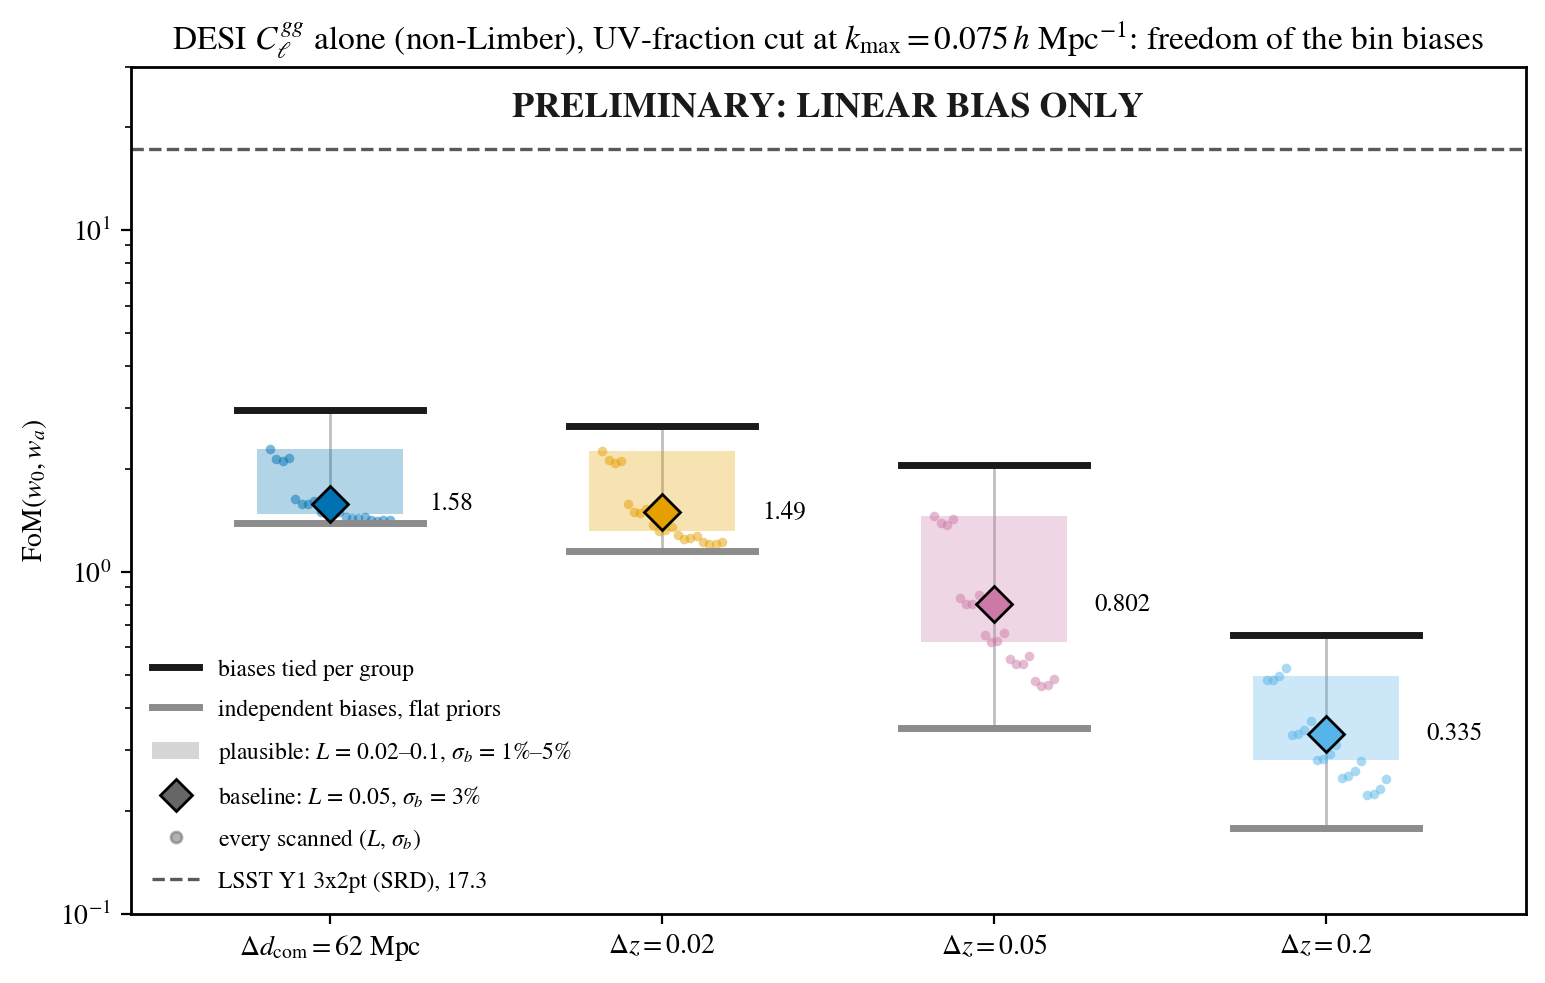

In [37]:
# The bottom line per layout: the FoM range the bias freedom allows. The
# black cap is the tied model, the gray cap independent biases; the band
# spans the plausible region (L and sigma_b of PLAUSIBLE_L and PLAUSIBLE_SIGMA),
# the faint dots every scanned point and the large
# marker the baseline.
fig, ax = plt.subplots(figsize=(9, 5.5))
npts = len(BIAS_SIGMAS)*len(BIAS_CORR_LENGTHS)
for k, key in enumerate(LAYOUT_DATASETS):
    color = LAYOUT_COLORS[key]
    grid = fom_grid[key]
    ia = [a for a, s in enumerate(BIAS_SIGMAS) if PLAUSIBLE_SIGMA[0] <= s <= PLAUSIBLE_SIGMA[1]]
    ic = [c for c, L in enumerate(BIAS_CORR_LENGTHS) if PLAUSIBLE_L[0] <= L <= PLAUSIBLE_L[1]]
    band = grid[np.ix_(ia, ic)]
    ax.plot([k, k], [fom_indep[key], fom_tied[key]], color='0.75', lw=1.0, zorder=0)
    ax.fill_between([k - 0.22, k + 0.22], band.min(), band.max(), color=color,
                    alpha=0.3, lw=0)
    ax.scatter(k + np.linspace(-0.18, 0.18, npts), grid.ravel(), s=12, color=color,
               alpha=0.5, lw=0)
    ax.plot([k - 0.28, k + 0.28], [fom_tied[key]]*2, color='0.1', lw=2.5)
    ax.plot([k - 0.28, k + 0.28], [fom_indep[key]]*2, color='0.55', lw=2.5)
    base = grid[BIAS_SIGMAS.index(BASELINE[1]), BIAS_CORR_LENGTHS.index(BASELINE[0])]
    ax.plot(k, base, marker='D', ms=9, color=color, mec='black', zorder=5)
    ax.text(k + 0.3, base, f'{base:.3g}', va='center', fontsize=9)
ax.axhline(LSST_Y1_SRD_FOM, color='0.35', ls='--', lw=1.2)
ax.set_yscale('log')
ax.set_ylim(0.1, 30.0)
ax.set_xlim(-0.6, len(LAYOUT_DATASETS) - 0.4)
ax.set_xticks(range(len(LAYOUT_DATASETS)))
ax.set_xticklabels([LAYOUT_LABELS[key] for key in LAYOUT_DATASETS])
ax.set_ylabel(r'FoM$(w_0, w_a)$')
ax.set_title(rf'DESI $C_\ell^{{gg}}$ alone (non-Limber), UV-fraction cut at '
             rf'$k_\mathrm{{max}} = {KMAX_CUTS[m_bias]:g}\,h$ Mpc$^{{-1}}$: freedom of the bin biases')
ax.text(0.5, 0.97, 'PRELIMINARY: LINEAR BIAS ONLY', transform=ax.transAxes,
        ha='center', va='top', fontsize=13, fontweight='bold', color='0.1')
handles = [
    Line2D([], [], color='0.1', lw=2.5, label='biases tied per group'),
    Line2D([], [], color='0.55', lw=2.5, label='independent biases, flat priors'),
    Patch(facecolor='0.6', alpha=0.4,
          label=rf'plausible: $L$ = {PLAUSIBLE_L[0]:g}–{PLAUSIBLE_L[1]:g}, '
                rf'$\sigma_b$ = {PLAUSIBLE_SIGMA[0]:.0%}–{PLAUSIBLE_SIGMA[1]:.0%}'),
    Line2D([], [], color='0.4', marker='D', ls='none', ms=8, mec='black',
           label=rf'baseline: $L$ = {BASELINE[0]:g}, $\sigma_b$ = {BASELINE[1]:.0%}'),
    Line2D([], [], color='0.4', marker='o', ls='none', ms=4, alpha=0.5,
           label=r'every scanned ($L$, $\sigma_b$)'),
    Line2D([], [], color='0.35', ls='--', lw=1.2,
           label=f'LSST Y1 3x2pt (SRD), {LSST_Y1_SRD_FOM:.1f}'),
]
ax.legend(handles=handles, fontsize=8.5, loc='lower left', frameon=False)
plt.show()

Which knob does the work? The heatmaps show the fraction of the tied FoM
kept, FoM/FoM$_\mathrm{tied}$, on the $(L, \sigma_b)$ grid of every
layout, on one shared color scale; each cell prints the fraction and, in
parentheses, the FoM. Down a column $\sigma_b$ grows, across a row $L$
grows. $\sigma_b$ dominates: at $\sigma_b = 1\%$ the layouts keep
0.67-0.85 of their tied FoM, and at $\sigma_b \ge 5\%$ the
$\Delta d_\mathrm{com} = 62$ Mpc layout stays within 8% of its independent
value, where the prior no longer ties much that the data can feel. $L$
now matters little: at $\sigma_b = 3\%$ the FoM moves only between
1.48 and 1.58 across the $L$ grid on $\Delta z = 0.02$, between 1.58 and
1.64 on $\Delta d_\mathrm{com} = 62$ Mpc, and between 0.80
and 0.86 on $\Delta z = 0.05$.

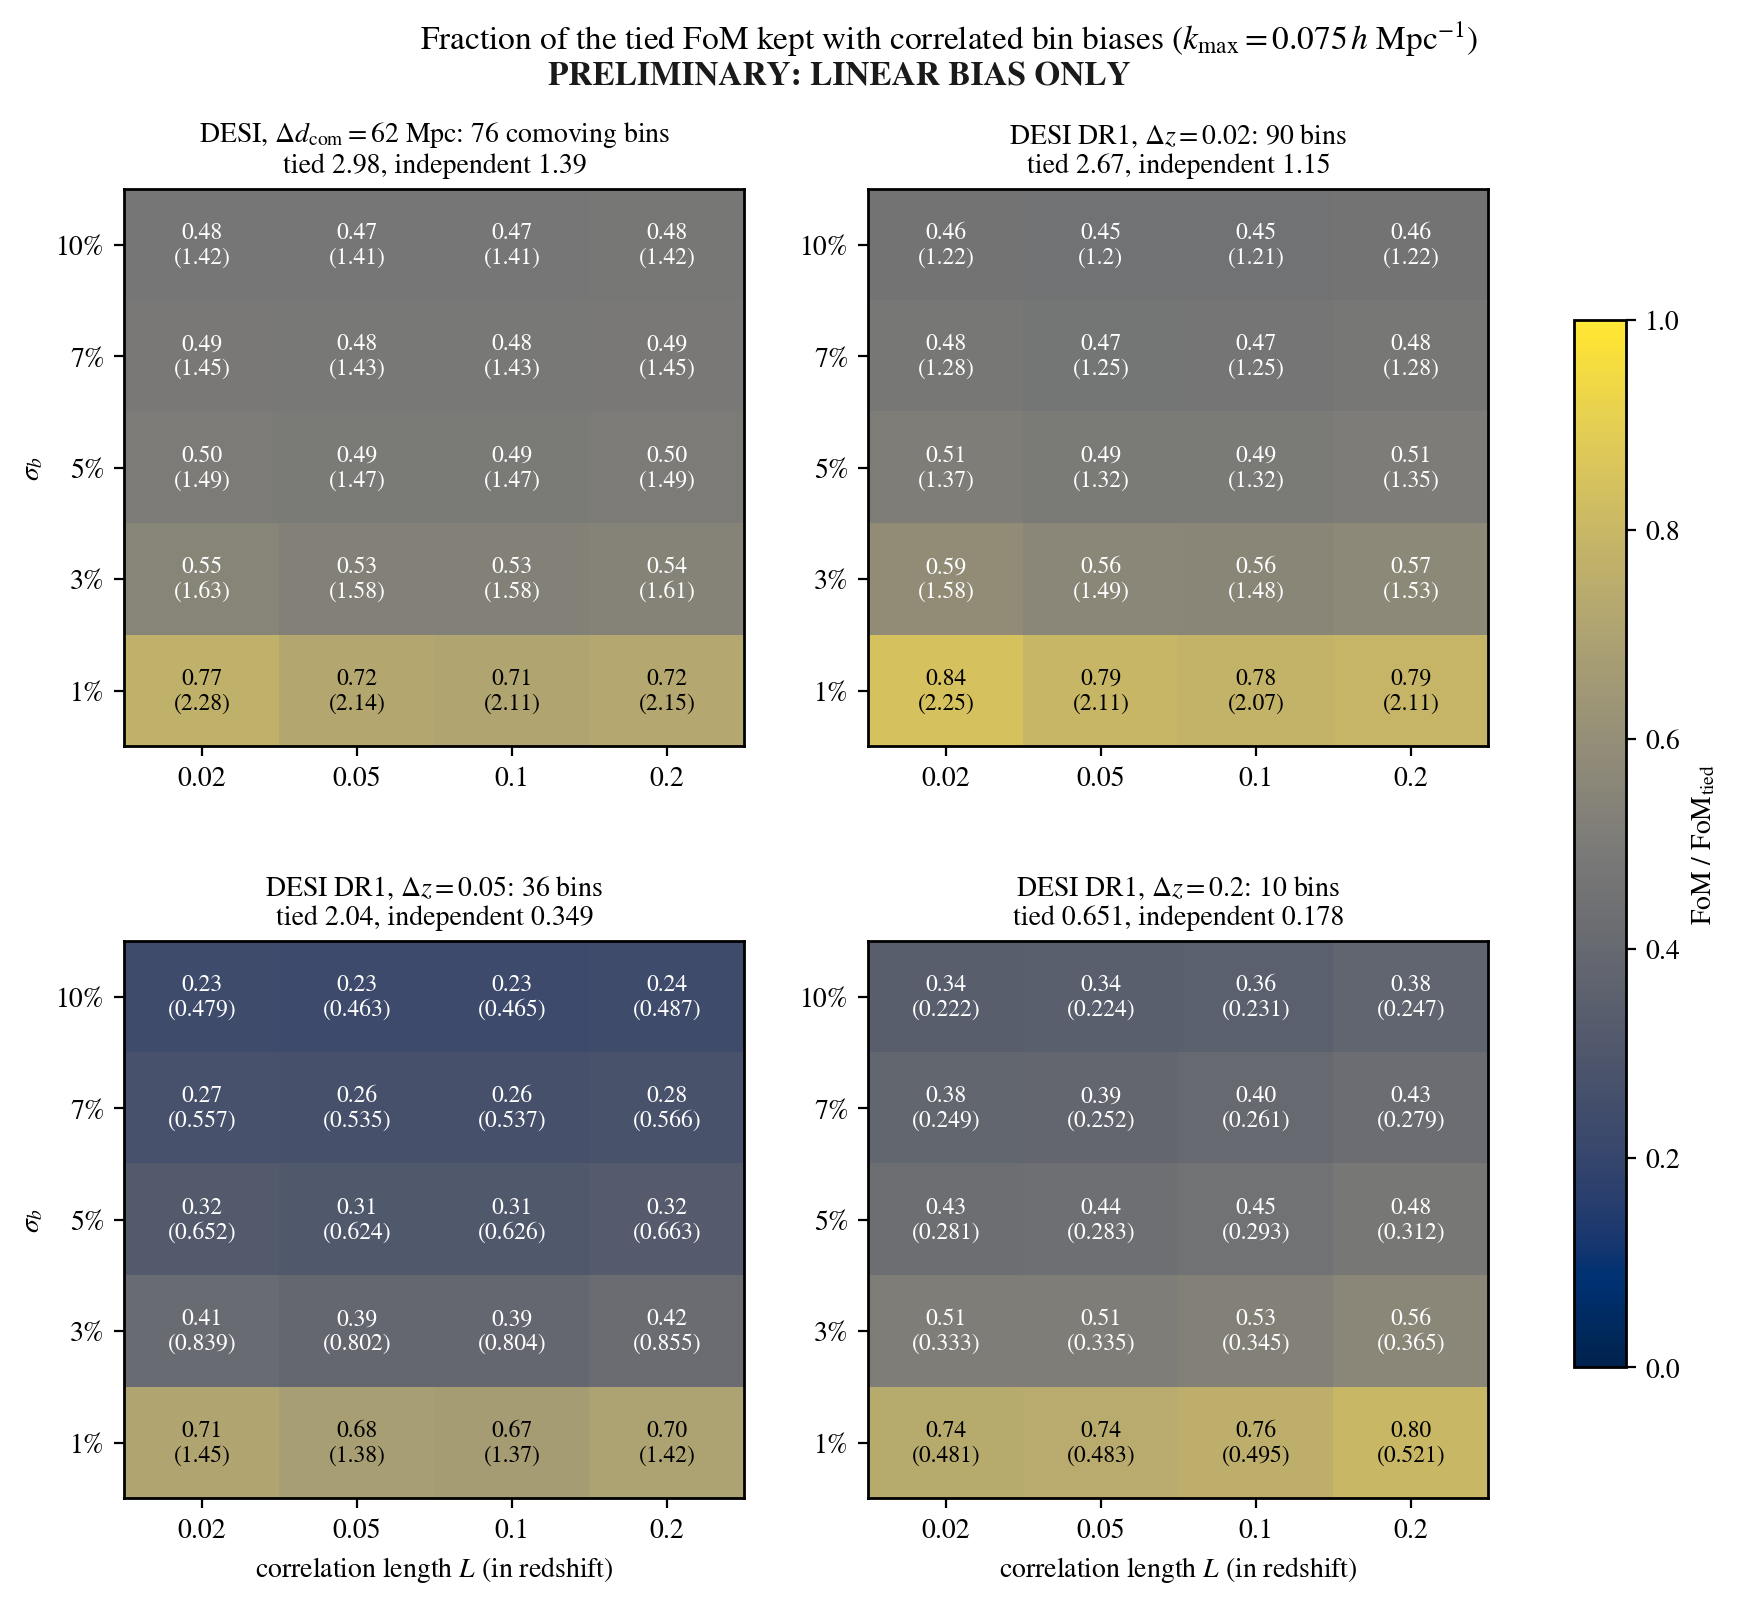

In [38]:
# Which knob matters: the fraction of the tied FoM kept, FoM/FoM_tied, on
# the (L, sigma_b) grid of each layout, on one shared color scale. Each cell
# gives the fraction and, below it, the FoM.
fig, axes = plt.subplots(2, 2, figsize=(11, 8.5), gridspec_kw={'hspace': 0.35})
for n, (ax, key) in enumerate(zip(axes.ravel(), LAYOUT_DATASETS)):
    frac = fom_grid[key]/fom_tied[key]
    image = ax.imshow(frac, origin='lower', cmap='cividis', vmin=0.0, vmax=1.0,
                      aspect='auto')
    for a in range(len(BIAS_SIGMAS)):
        for c in range(len(BIAS_CORR_LENGTHS)):
            ax.text(c, a, f'{frac[a, c]:.2f}\n({fom_grid[key][a, c]:.3g})',
                    ha='center', va='center', fontsize=8.5,
                    color='white' if frac[a, c] < 0.6 else 'black')
    ax.set_xticks(range(len(BIAS_CORR_LENGTHS)))
    ax.set_xticklabels([f'{L:g}' for L in BIAS_CORR_LENGTHS])
    ax.set_yticks(range(len(BIAS_SIGMAS)))
    ax.set_yticklabels([f'{s:.0%}' for s in BIAS_SIGMAS])
    ax.grid(False)
    if n >= 2:  # shared labels: x on the bottom row, y on the left column
        ax.set_xlabel(r'correlation length $L$ (in redshift)')
    if n % 2 == 0:
        ax.set_ylabel(r'$\sigma_b$')
    ax.set_title(f'{LAYOUTS[key]["title"]}\n'
                 f'tied {fom_tied[key]:.3g}, independent {fom_indep[key]:.3g}', fontsize=10)
fig.colorbar(image, ax=axes, label=r'FoM / FoM$_\mathrm{tied}$', shrink=0.8)
fig.suptitle('Fraction of the tied FoM kept with correlated bin biases '
             rf'($k_\mathrm{{max}} = {KMAX_CUTS[m_bias]:g}\,h$ Mpc$^{{-1}}$)', fontsize=12)
fig.text(0.45, 0.955, 'PRELIMINARY: LINEAR BIAS ONLY', ha='center', va='top',
         fontsize=12, fontweight='bold', color='0.1')
plt.show()

For bins much closer than $L$ the prior is a random walk in redshift: the
deviations of bins $\Delta z$ apart differ by about
$\sigma_b\sqrt{2\,\Delta z/L}$ rms, which depends on $(L, \sigma_b)$ only
through the roughness $\kappa = \sigma_b/\sqrt{L}$. If these neighbor
jumps alone set the FoM, the whole grid would collapse onto one curve per
layout against $\sqrt{2}\,\kappa = \sigma_b\sqrt{2/L}$ (the $x$ axis: the
rms change between bins is that number times $\sqrt{\Delta z}$). The
figure shows that it does not: at fixed $\kappa$ the markers of different
$L$ spread apart on every layout. The scanned $L$ reach the redshift span
of the groups (0.2-0.3), where the prior's long-range freedom, the wander
$\sigma_b$ itself, also acts, so the scan keeps two parameters and cannot
be compressed into $\kappa$ alone. The dotted lines mark each layout's
independent fraction, the limit $\kappa \to \infty$.

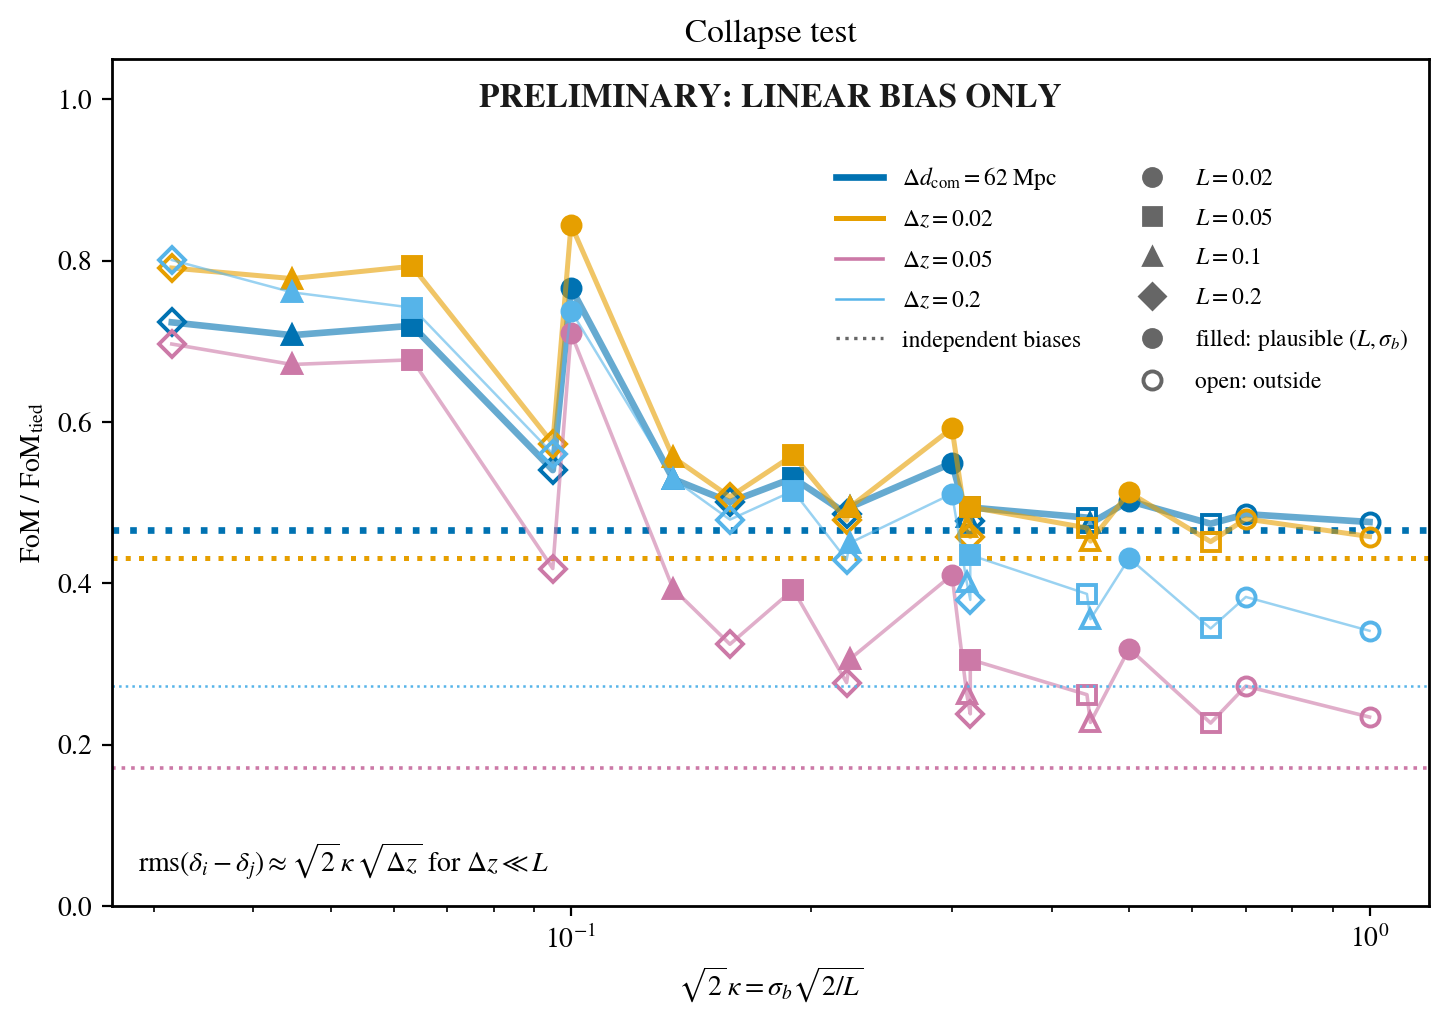

In [39]:
# Does the FoM depend on one combination only? Neighbors a small dz apart
# may differ by about sigma_b sqrt(2 dz/L) = (sqrt(2) kappa) sqrt(dz), so
# thin bins feel the roughness kappa = sigma_b/sqrt(L) of b(z); the x axis
# is sqrt(2) kappa, so that the rms change between two bins is that number
# times sqrt(dz). If the points of a layout fall on one curve whatever L
# is, the scan reduces to that one number; where L approaches the redshift
# span of a group the large-scale freedom matters too and the points
# spread. Filled markers: (L, sigma_b) inside the plausible region
# (PLAUSIBLE_L, PLAUSIBLE_SIGMA); open markers: outside it. Dotted lines:
# the independent fraction of each layout (kappa -> infinity). The marker
# shape is L here, so each layout's lines take its line width
# (LAYOUT_STYLE) as well as its color.
L_MARKERS = {0.02: 'o', 0.05: 's', 0.1: '^', 0.2: 'D'}


def is_plausible(L, sigma_b):
    """True when (L, sigma_b) lies inside the plausible region."""
    return (PLAUSIBLE_L[0] <= L <= PLAUSIBLE_L[1]
            and PLAUSIBLE_SIGMA[0] <= sigma_b <= PLAUSIBLE_SIGMA[1])


fig, ax = plt.subplots(figsize=(8.5, 5.5))
for key in LAYOUT_DATASETS:
    color = LAYOUT_COLORS[key]
    kappas = []
    fracs = []
    for c, L in enumerate(BIAS_CORR_LENGTHS):
        for a, sigma_b in enumerate(BIAS_SIGMAS):
            kappa2 = np.sqrt(2.0)*sigma_b/np.sqrt(L)
            frac = fom_grid[key][a, c]/fom_tied[key]
            kappas.append(kappa2)
            fracs.append(frac)
            ax.plot(kappa2, frac, marker=L_MARKERS[L], color=color, ls='none',
                    ms=6.5, mew=1.4, mfc=color if is_plausible(L, sigma_b) else 'none')
    order = np.argsort(kappas)
    ax.plot(np.array(kappas)[order], np.array(fracs)[order], color=color,
            lw=LAYOUT_STYLE[key]['lw'], alpha=0.6)
    ax.axhline(fom_indep[key]/fom_tied[key], color=color, ls=':',
               lw=LAYOUT_STYLE[key]['lw'])
ax.set_xscale('log')
ax.set_ylim(0.0, 1.05)
ax.set_xlabel(r'$\sqrt{2}\,\kappa = \sigma_b\sqrt{2/L}$')
ax.set_ylabel(r'FoM / FoM$_\mathrm{tied}$')
ax.set_title('Collapse test')
ax.text(0.5, 0.97, 'PRELIMINARY: LINEAR BIAS ONLY', transform=ax.transAxes,
        ha='center', va='top', fontsize=12, fontweight='bold', color='0.1')
ax.text(0.02, 0.03,
        r'$\mathrm{rms}(\delta_i - \delta_j) \approx \sqrt{2}\,\kappa\,\sqrt{\Delta z}$'
        r' for $\Delta z \ll L$', transform=ax.transAxes, ha='left', va='bottom',
        fontsize=10)
# legend: lines in the first column, marker types in the second (blank
# entries pad the shorter column)
lines = [Line2D([], [], color=LAYOUT_COLORS[key], lw=LAYOUT_STYLE[key]['lw'],
                label=LAYOUT_LABELS[key])
         for key in LAYOUT_DATASETS]
lines.append(Line2D([], [], color='0.4', ls=':', lw=1.2, label='independent biases'))
markers = [Line2D([], [], color='0.4', marker=mk, ls='none', ms=6.5, label=rf'$L = {L:g}$')
           for L, mk in L_MARKERS.items()]
markers.append(Line2D([], [], color='0.4', marker='o', ls='none', ms=6.5,
                      label=r'filled: plausible $(L, \sigma_b)$'))
markers.append(Line2D([], [], color='0.4', marker='o', ls='none', ms=6.5, mfc='none',
                      mew=1.4, label='open: outside'))
lines += [Line2D([], [], color='none', label=' ')]*(len(markers) - len(lines))
ax.legend(handles=lines + markers, fontsize=8.5, ncol=2, loc='upper right',
          bbox_to_anchor=(1.0, 0.9), frameon=False)
plt.show()

#### The memory model: a free tilt per group

The exponential kernel forgets: its correlation decays as $e^{-\Delta z/L}$,
so the two ends of a group are nearly unrelated, and the one width
$\sigma_b$ must pay for the bin-to-bin scatter and for any smooth drift
across the group at once. The measured departures of the bias from the
constant-clustering-amplitude trend $B_g/D(z)$ are mostly drifts, line-like
across a group: a flux limit or magnitude cut that moves with redshift, or
the slow decay of a conserved population's bias toward one. To admit a
drift of BGS size the kernel needs $\sigma_b \approx 10$-$15\%$, which also
allows roughly $10\%$ scatter between neighboring bins that no identified
mechanism produces. The memory model separates the two kinds of change by
giving each group a free linear tilt $s_g$ next to its free amplitude,

$$b_i = \frac{B_g}{D(z_i)}\,\bigl(1 + s_g\,(z_i - \bar z_g) +
\varepsilon_i\bigr), \qquad
\langle \varepsilon_i\,\varepsilon_j \rangle = \sigma_b^2\,
e^{-|z_i - z_j|/L} \ \text{(same group)},$$

with $\bar z_g$ the mean of the group's bin redshifts and the residual
$\varepsilon_i$ keeping the kernel. The shared slope is the memory: the two
ends of a group stay correlated through it however far apart they are. The
tilt absorbs the line-like drifts, so $\sigma_b$ covers only the residual
around each group's line (curvature and local scatter, of order
$1$-$3\%$), a different physical quantity than the kernel model's total
departure from the trend. In the prior precision the tilt is a second free
direction projected out next to the uniform shift: with $Q$ the inverse
kernel covariance of a group and $U = [\mathbf{1},\ z - \bar z_g]$, the
group's block is $P = Q - Q\,U\,(U^{\mathsf T} Q\,U)^{-1} U^{\mathsf T} Q$,
with $P\,U = 0$. A group of one or two bins has no shape left once its
level and slope are free, so its block is zero; on $\Delta z = 0.2$, whose
groups hold one or two bins, the memory model is the independent model.
The limits: $\sigma_b \to 0$ is the tied model plus a free tilt per group,
$\sigma_b \to \infty$ the independent model. The appendices "The memory
model" and "The memory projection, step by step" of
`notes/correlated_bias_prior_v2/correlated_bias_prior_v2.pdf` derive the
projection, the prediction formulas behind "forgets" and "remembers", and
the physics of the tilt.

The cell checks the projection ($P\,U = 0$ to about $10^{-16}$ of each
block's scale), scans the same $(L, \sigma_b)$ grid, and prints the grid
and a side-by-side table of the two models at $L = 0.05$ with their
limits. The free tilt alone is expensive: "tied + free tilt" costs 52%,
55% and 79% of the tied FoM on $\Delta d_\mathrm{com} = 62$ Mpc,
$\Delta z = 0.02$ and $\Delta z = 0.05$. That cost is growth information:
the clustering band powers scale as $(b\,D)^2$, so a free tilt hands the
relative growth inside each group to the bias; the redshift-space terms,
which scale as $b\,f$ with $f$ the growth rate, and the comparison of
growth between groups keep the rest.

In [40]:
# The memory model. The measured departures of the bias from B_g/D(z)
# are mostly smooth drifts across a group (a flux limit or a magnitude cut
# that moves with z), not scatter between neighbors. The memory model gives
# each group a free linear tilt next to its free amplitude,
#
#   b_i = B_g/D(z_i) * (1 + s_g (z_i - zbar_g) + eps_i),
#
# with s_g the tilt (flat prior) and zbar_g the mean of the group's bin
# redshifts, and keeps the exponential kernel only for the residual eps_i:
#
#   <eps_i eps_j> = sigma_b^2 exp(-|z_i - z_j|/L)   (same group).
#
# A free direction of the bin biases is a direction the prior must not
# charge. With Q the inverse of the kernel covariance of a group and U the
# matrix whose columns are the free directions, here U = [1, z - zbar],
# the prior precision of the group is
#
#   P = Q - Q U (U^T Q U)^-1 U^T Q,
#
# which gives P U = 0 and is the precision left after marginalizing the
# free amplitude and tilt (the same construction as the kernel model, with
# one more column in U). A group of one or two bins has no shape left once
# its amplitude and tilt are free, so its block is zero. The limits:
# sigma_b -> 0 gives the tied model plus a free tilt per group, and
# sigma_b -> infinity the independent model.


def memory_bias_precision(key, L, sigma_b):
    """Prior precision on the bin biases DESI_B1_i of one layout, with each
    group's amplitude and linear tilt in redshift left free.

    Arguments:
      key     = a LAYOUT_DATASETS key.
      L       = the correlation e-fold length of the residual scatter, in
                redshift.
      sigma_b = the rms fractional residual of one bin around its group's
                tilted trend.

    Returns:
      (nbins, nbins) array, block-diagonal by group, with the uniform-shift
      and tilt directions of every group removed.
    """
    cov = layout_covariance(key)
    zbar = np.array([float(row[4]) for row in cov['bins']])
    leaders = bin_bias[key]['leaders']
    fiducial = dict(zip(layout_desi[key]['names'], layout_desi[key]['fiducial']))
    P = np.zeros((len(leaders), len(leaders)))
    for ld in dict.fromkeys(leaders):
        idx = np.array([i for i, x in enumerate(leaders) if x == ld])
        if len(idx) <= 2:
            continue  # the amplitude and the tilt already free every bin
        z = zbar[idx]
        # DESI_B1_i = B_g (1 + delta_i): sigma(DESI_B1_i) = sigma_b B_g
        width = sigma_b*fiducial[ld]
        Q = np.linalg.inv(width**2*np.exp(-np.abs(z[:, None] - z[None, :])/L))
        U = np.column_stack([np.ones(len(z)), z - z.mean()])
        QU = Q @ U
        P[np.ix_(idx, idx)] = Q - QU @ np.linalg.inv(U.T @ QU) @ QU.T
    return P


# check: P removes the amplitude and the tilt of every group, and stays
# positive semidefinite (relative to its own scale)
worst_null = 0.0
worst_neg = 0.0
for key in LAYOUT_DATASETS:
    P = memory_bias_precision(key, BASELINE[0], BASELINE[1])
    zbar = np.array([float(row[4]) for row in layout_covariance(key)['bins']])
    leaders = bin_bias[key]['leaders']
    for ld in dict.fromkeys(leaders):
        idx = np.array([i for i, x in enumerate(leaders) if x == ld])
        block = P[np.ix_(idx, idx)]
        scale = max(np.abs(block).max(), 1.0e-300)
        U = np.column_stack([np.ones(len(idx)), zbar[idx] - zbar[idx].mean()])
        worst_null = max(worst_null, np.abs(block @ U).max()/scale)
        worst_neg = max(worst_neg, -np.linalg.eigvalsh(block).min()/scale)
print(f'projection check: max |P U|/max|P| = {worst_null:.1e}, '
      f'most negative eigenvalue/max|P| = {worst_neg:.1e}')

fom_memory = {}  # [sigma_b index, L index]
fom_tilt = {}    # sigma_b -> 0: the tied model plus a free tilt per group
for key in LAYOUT_DATASETS:
    grid = np.zeros((len(BIAS_SIGMAS), len(BIAS_CORR_LENGTHS)))
    for a, sigma_b in enumerate(BIAS_SIGMAS):
        for c, L in enumerate(BIAS_CORR_LENGTHS):
            grid[a, c] = fom_bin_biases(key, m_bias, memory_bias_precision(key, L, sigma_b))
    fom_memory[key] = grid
    fom_tilt[key] = fom_bin_biases(key, m_bias, memory_bias_precision(key, 0.05, 1.0e-4))

memory_table = {}
for key in LAYOUT_DATASETS:
    for a, sigma_b in enumerate(BIAS_SIGMAS):
        memory_table[(key, f'sigma_b = {sigma_b:.0%}')] = dict(zip(BIAS_CORR_LENGTHS, fom_memory[key][a]))
print(f'FoM(w0, wa) of DESI C_gg alone at k_max = {KMAX_CUTS[m_bias]:g} h/Mpc, memory model '
      '(free amplitude and tilt per group); columns: L (e-fold length in redshift)')
display(pd.DataFrame(memory_table).T)

c_ref = BIAS_CORR_LENGTHS.index(BASELINE[0])
summary = {}
for key in LAYOUT_DATASETS:
    summary[key] = {
        'tied': fom_tied[key],
        'tied + free tilt': fom_tilt[key],
        'memory, sigma_b = 1%': fom_memory[key][BIAS_SIGMAS.index(0.01), c_ref],
        'kernel, sigma_b = 1%': fom_grid[key][BIAS_SIGMAS.index(0.01), c_ref],
        'memory, sigma_b = 1000%': fom_bin_biases(key, m_bias, memory_bias_precision(key, BASELINE[0], 10.0)),
        'independent, flat': fom_indep[key],
    }
print(f'the two models side by side at L = {BASELINE[0]:g}, with their limits:')
display(pd.DataFrame(summary).T)

projection check: max |P U|/max|P| = 2.2e-16, most negative eigenvalue/max|P| = 3.2e-16


FoM(w0, wa) of DESI C_gg alone at k_max = 0.075 h/Mpc, memory model (free amplitude and tilt per group); columns: L (e-fold length in redshift)


0.02   0.05   0.1    0.2 
Delta d_com = 62 Mpc sigma_b = 1%   1.405  1.404  1.406  1.408
                     sigma_b = 3%   1.391  1.392  1.393  1.396
                     sigma_b = 5%   1.388  1.389   1.39  1.392
                     sigma_b = 7%   1.387  1.388  1.389   1.39
                     sigma_b = 10%  1.387  1.387  1.388  1.388
Delta z = 0.02       sigma_b = 1%    1.18  1.181  1.182  1.184
                     sigma_b = 3%   1.162  1.165  1.169  1.173
                     sigma_b = 5%   1.156  1.158  1.161  1.166
                     sigma_b = 7%   1.154  1.155  1.157  1.161
                     sigma_b = 10%  1.152  1.153  1.154  1.157
Delta z = 0.05       sigma_b = 1%  0.4029  0.403 0.4046 0.4074
                     sigma_b = 3%  0.3805 0.3814 0.3849 0.3903
                     sigma_b = 5%  0.3686 0.3694 0.3729  0.379
                     sigma_b = 7%  0.3619 0.3625 0.3654  0.371
                     sigma_b = 10% 0.3565  0.357 0.3591 0.3634
Delta z = 0.2        sigma_b = 1%  0.1776 0.1776 0.1776 0.1776
                     sigma_b = 3%  0.1776 0.1776 0.1776 0.1776
                     sigma_b = 5%  0.1776 0.1776 0.1776 0.1776
                     sigma_b = 7%  0.1776 0.1776 0.1776 0.1776
                     sigma_b = 10% 0.1776 0.1776 0.1776 0.1776

the two models side by side at L = 0.05, with their limits:


,tied,tied + free tilt,"memory, sigma_b = 1%","kernel, sigma_b = 1%","memory, sigma_b = 1000%","independent, flat"
Delta d_com = 62 Mpc,2.977,1.425,1.404,2.141,1.386,1.386
Delta z = 0.02,2.667,1.191,1.181,2.115,1.15,1.15
Delta z = 0.05,2.044,0.4224,0.403,1.384,0.3488,0.3488
Delta z = 0.2,0.6512,0.1776,0.1776,0.483,0.1776,0.1776


The figure puts the two models on one axis: the fraction of the tied FoM
kept against the residual scatter $\sigma_b$ at $L = 0.05$, circles and
solid lines for the exponential kernel, triangles and dashed lines for the
memory model, dotted lines for the independent limit of each layout. At
$\sigma_b = 0$ the kernel curve starts at 1, the tied model, while the
memory curve starts at the tied-plus-free-tilt fraction; at large
$\sigma_b$ both approach the dotted line. At equal $\sigma_b$ the memory
curve sits below the kernel curve, since a free tilt is strictly more
freedom. Equal $\sigma_b$ is not the fair reading, because the symbol
measures different departures in the two models: the kernel needs
$\sigma_b \approx 10\%$ to admit the measured drifts, while the memory
model admits them with a residual of $1$-$3\%$. Read that way, the two
now give nearly the same information: at $L = 0.05$ the memory model gives
1.404 ($\sigma_b = 1\%$) and 1.392 ($3\%$) against the kernel's 1.411
($10\%$) on $\Delta d_\mathrm{com} = 62$ Mpc, 1.181 and 1.165 against 1.204 on
$\Delta z = 0.02$, and 0.403 and 0.381 against 0.464 on $\Delta z = 0.05$.

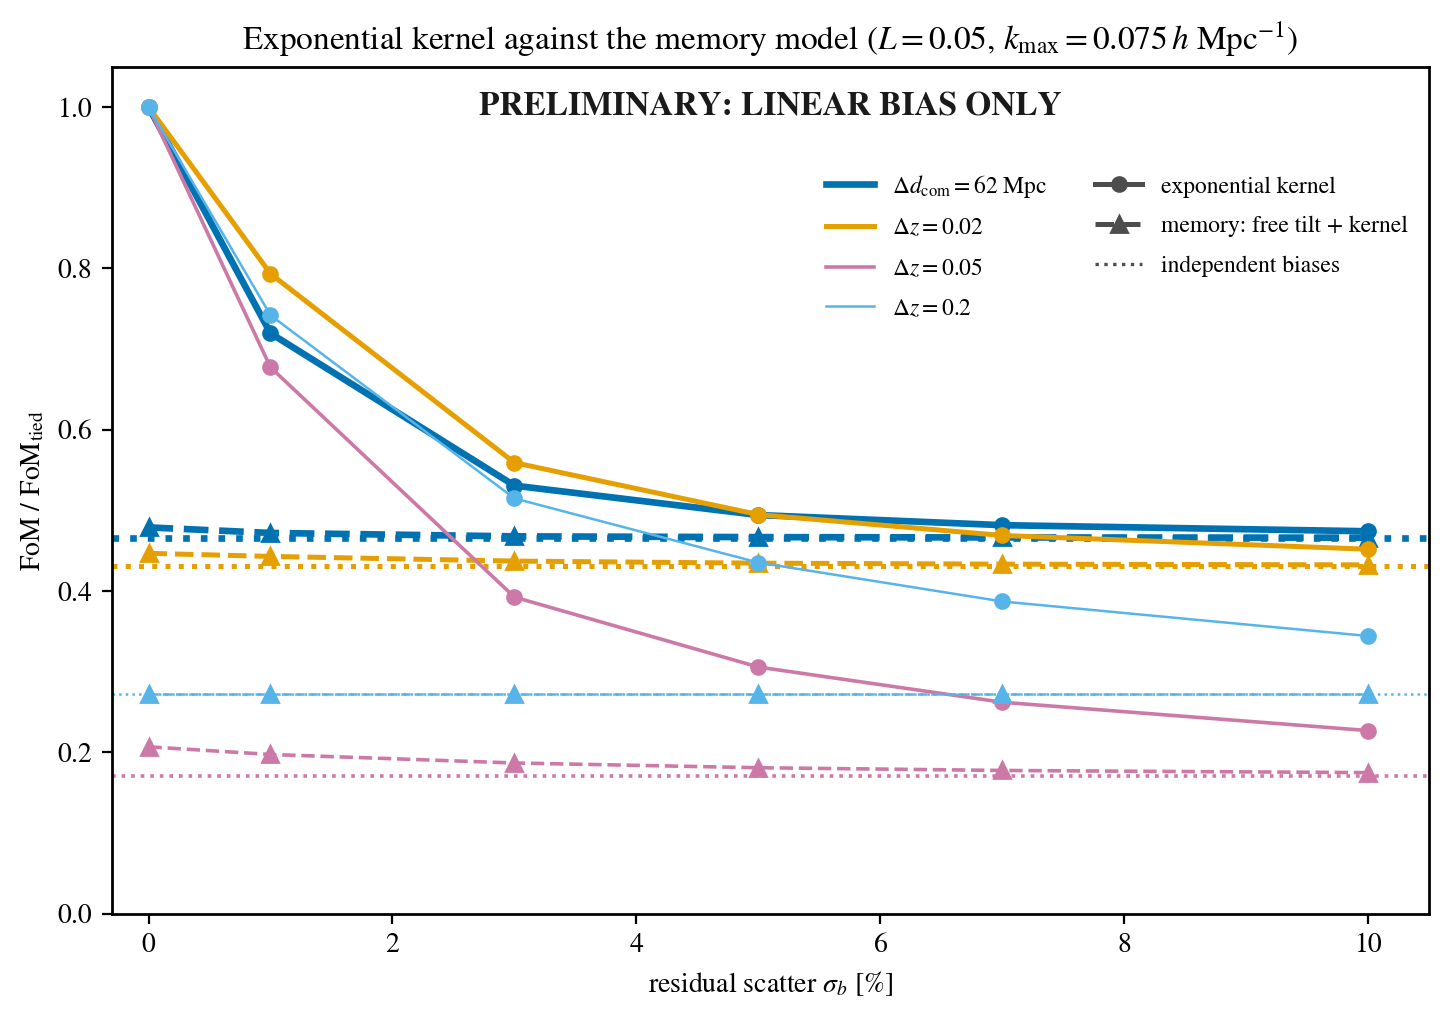

In [41]:
# Kernel against memory: the fraction of the tied FoM kept as the residual
# scatter sigma_b grows, at L = 0.05. At sigma_b = 0 the kernel model is the
# tied model (fraction 1) and the memory model is the tied model plus a free
# tilt per group; for large sigma_b both tend to independent biases (dotted).
# The heatmaps show how much L moves each point. The marker shape is the
# model here, so each layout's lines take its line width (LAYOUT_STYLE) as
# well as its color.
c_ref = BIAS_CORR_LENGTHS.index(BASELINE[0])
sig = 100.0*np.array([0.0] + list(BIAS_SIGMAS))
fig, ax = plt.subplots(figsize=(8.5, 5.5))
for key in LAYOUT_DATASETS:
    color = LAYOUT_COLORS[key]
    kernel = np.r_[1.0, fom_grid[key][:, c_ref]/fom_tied[key]]
    memory = np.r_[fom_tilt[key], fom_memory[key][:, c_ref]]/fom_tied[key]
    lw = LAYOUT_STYLE[key]['lw']
    ax.plot(sig, kernel, color=color, marker='o', ms=5, lw=lw)
    ax.plot(sig, memory, color=color, marker='^', ms=6, lw=lw, ls='--')
    ax.axhline(fom_indep[key]/fom_tied[key], color=color, ls=':', lw=lw)
ax.set_xlim(-0.3, 10.5)
ax.set_ylim(0.0, 1.05)
ax.set_xlabel(r'residual scatter $\sigma_b$ [%]')
ax.set_ylabel(r'FoM / FoM$_\mathrm{tied}$')
ax.set_title(rf'Exponential kernel against the memory model ($L = {BASELINE[0]:g}$, '
             rf'$k_\mathrm{{max}} = {KMAX_CUTS[m_bias]:g}\,h$ Mpc$^{{-1}}$)')
ax.text(0.5, 0.97, 'PRELIMINARY: LINEAR BIAS ONLY', transform=ax.transAxes,
        ha='center', va='top', fontsize=12, fontweight='bold', color='0.1')
handles = [Line2D([], [], color=LAYOUT_COLORS[key], lw=LAYOUT_STYLE[key]['lw'],
                  label=LAYOUT_LABELS[key])
           for key in LAYOUT_DATASETS]
handles += [
    Line2D([], [], color='0.3', marker='o', ms=5, lw=1.8, label='exponential kernel'),
    Line2D([], [], color='0.3', marker='^', ms=6, lw=1.8, ls='--',
           label='memory: free tilt + kernel'),
    Line2D([], [], color='0.3', ls=':', lw=1.2, label='independent biases'),
]
ax.legend(handles=handles, fontsize=8.5, ncol=2, loc='upper right',
          bbox_to_anchor=(1.0, 0.9), frameon=False)
plt.show()

The heatmaps repeat the kernel maps for the memory model, on the same
$(L, \sigma_b)$ grid and the same color scale, so the two figures compare
cell by cell; each panel's title adds the tied-plus-free-tilt FoM, which
the column values approach as $\sigma_b \to 0$. Every cell sits below its
kernel counterpart, and the $\Delta z = 0.2$ panel is flat at the
independent value because its groups hold one or two bins. The row labels
do not carry over physically: $\sigma_b$ here is the residual around each
group's line, so a row of this map describes a smaller departure from the
trend than the same row of the kernel map.

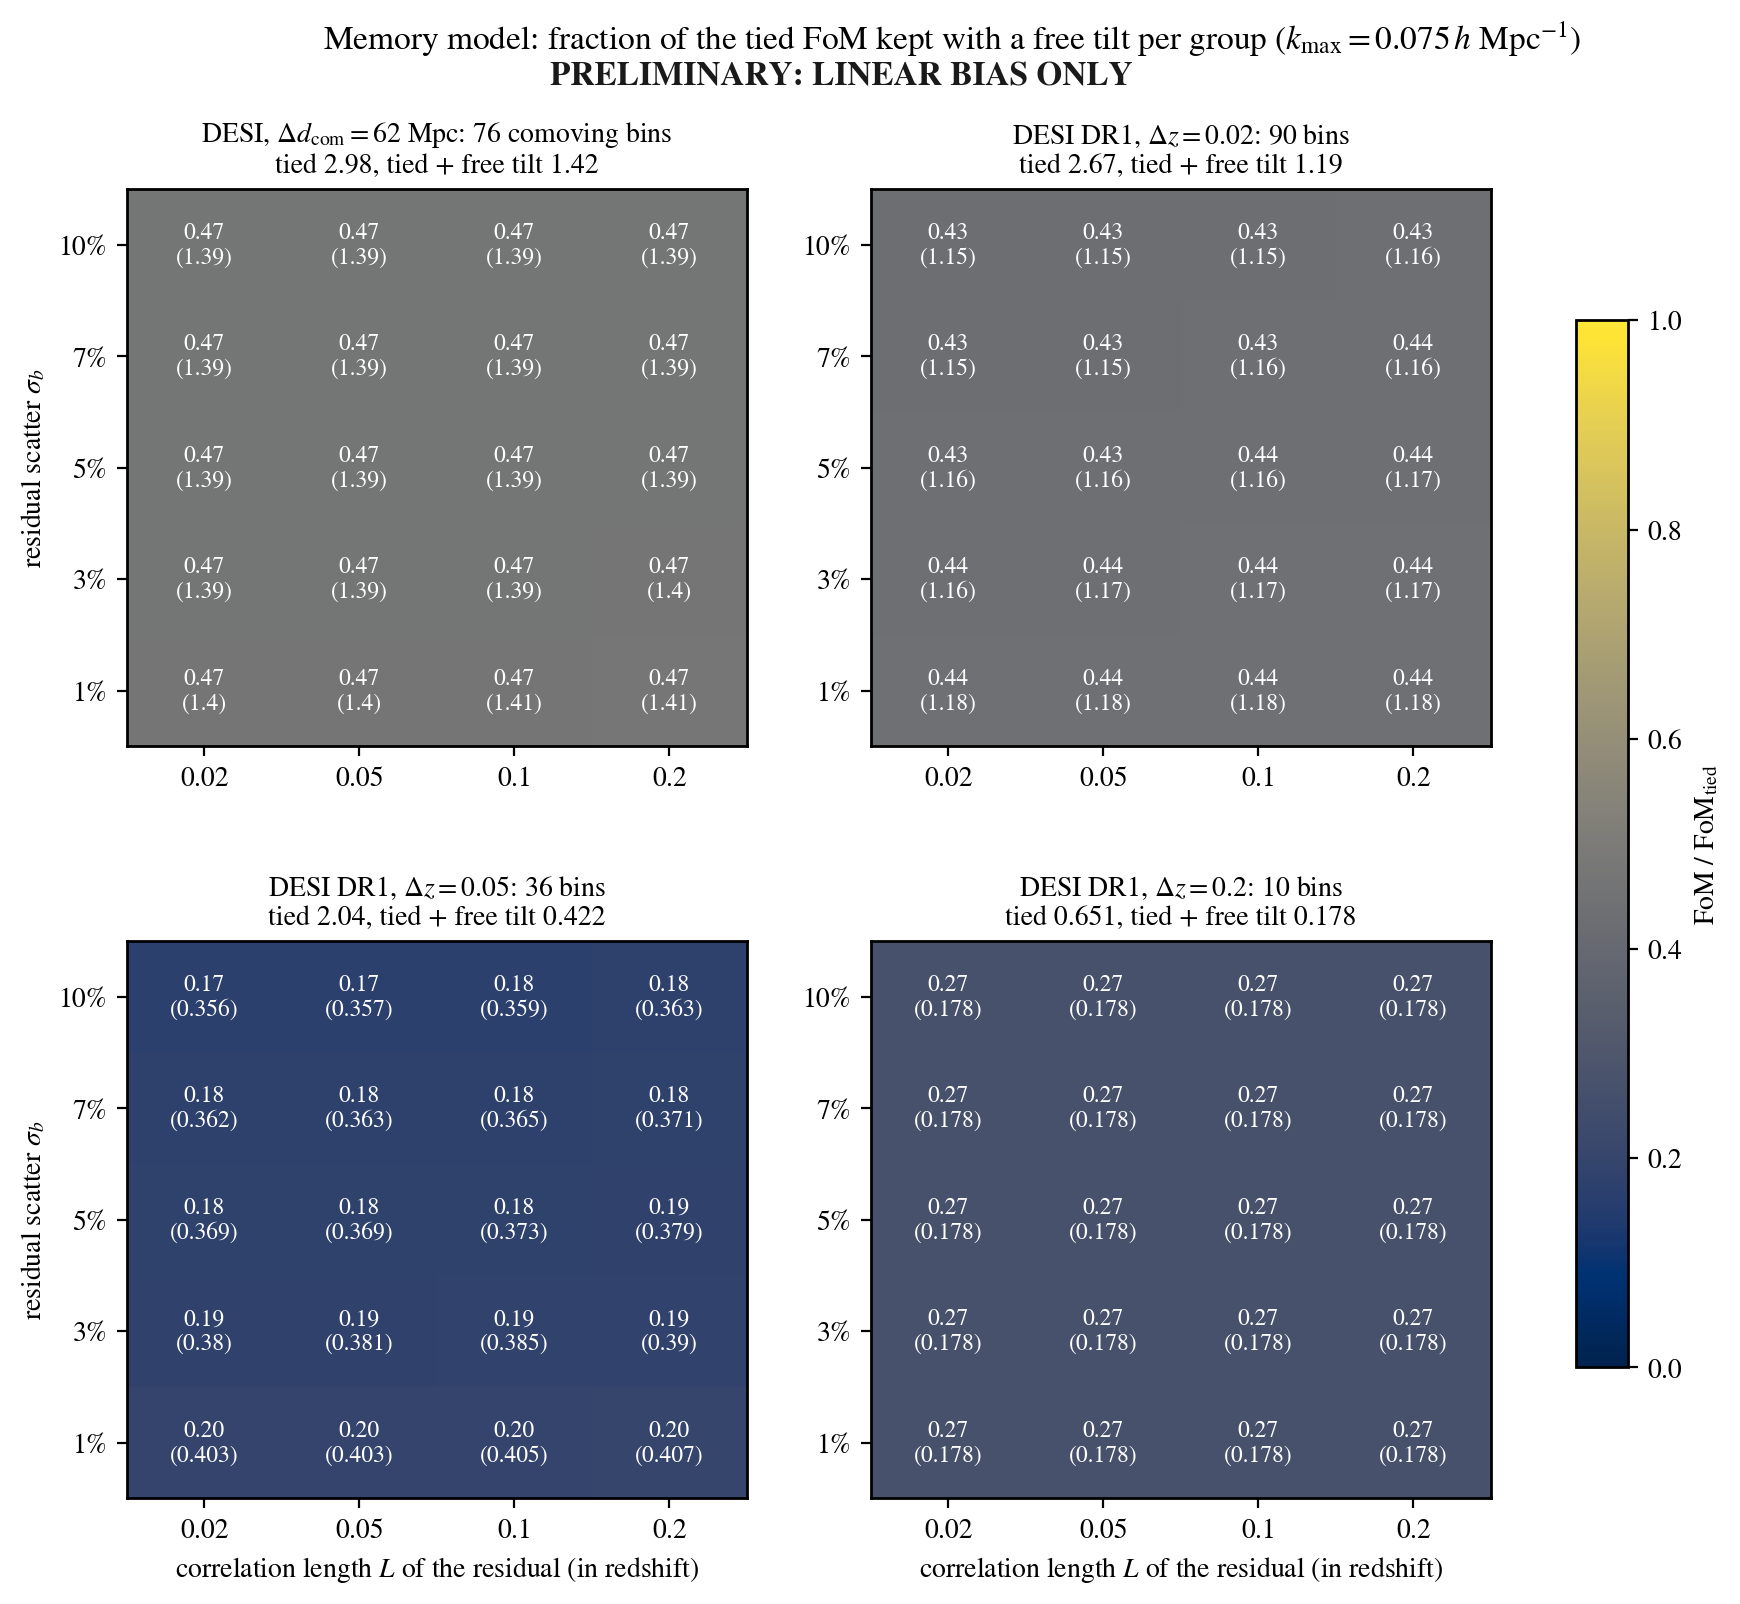

In [42]:
# The memory model on the (L, sigma_b) grid of every layout: the fraction
# of the tied FoM kept, with the FoM in parentheses, on the color scale of
# the kernel heatmap above, so the two maps compare cell by cell. The panel
# titles give the tied model plus a free tilt, the sigma_b -> 0 limit.
fig, axes = plt.subplots(2, 2, figsize=(11, 8.5), gridspec_kw={'hspace': 0.35})
for n, (ax, key) in enumerate(zip(axes.ravel(), LAYOUT_DATASETS)):
    frac = fom_memory[key]/fom_tied[key]
    image = ax.imshow(frac, origin='lower', cmap='cividis', vmin=0.0, vmax=1.0,
                      aspect='auto')
    for a in range(len(BIAS_SIGMAS)):
        for c in range(len(BIAS_CORR_LENGTHS)):
            ax.text(c, a, f'{frac[a, c]:.2f}\n({fom_memory[key][a, c]:.3g})',
                    ha='center', va='center', fontsize=8.5,
                    color='white' if frac[a, c] < 0.6 else 'black')
    ax.set_xticks(range(len(BIAS_CORR_LENGTHS)))
    ax.set_xticklabels([f'{L:g}' for L in BIAS_CORR_LENGTHS])
    ax.set_yticks(range(len(BIAS_SIGMAS)))
    ax.set_yticklabels([f'{s:.0%}' for s in BIAS_SIGMAS])
    ax.grid(False)
    if n >= 2:  # shared labels: x on the bottom row, y on the left column
        ax.set_xlabel(r'correlation length $L$ of the residual (in redshift)')
    if n % 2 == 0:
        ax.set_ylabel(r'residual scatter $\sigma_b$')
    ax.set_title(f'{LAYOUTS[key]["title"]}\n'
                 f'tied {fom_tied[key]:.3g}, tied + free tilt {fom_tilt[key]:.3g}', fontsize=10)
fig.colorbar(image, ax=axes, label=r'FoM / FoM$_\mathrm{tied}$', shrink=0.8)
fig.suptitle('Memory model: fraction of the tied FoM kept with a free tilt per group '
             rf'($k_\mathrm{{max}} = {KMAX_CUTS[m_bias]:g}\,h$ Mpc$^{{-1}}$)', fontsize=12)
fig.text(0.45, 0.955, 'PRELIMINARY: LINEAR BIAS ONLY', ha='center', va='top',
         fontsize=12, fontweight='bold', color='0.1')
plt.show()

#### The ladder of linear-bias models and the figure of bias

Four nested linear-bias priors run from rigid to free.  The two
intermediate ones are cases of one model: the bias of bin $i$ in tracer
group $g$ is

$$b_{1,i} = \frac{B_g}{D(z_i)}\,\bigl(1 + \delta_i\bigr), \qquad
\delta_i = s_g\,(z_i - \bar z_g) + \varepsilon_i, \qquad
\langle \varepsilon_i\,\varepsilon_j \rangle = \sigma_g^2\,
e^{-|z_i - z_j|/L} \ \text{(same group)},$$

with $D(z)$ the linear growth factor, $\bar z_g$ the mean redshift of
the group's bins, $B_g$ and $s_g$ a free amplitude and a free tilt per
group (flat priors), $\varepsilon_i$ the residual around the group's
line, $\sigma_g$ the per-bin residual width, and $L$ the correlation
length in redshift.  The four priors: **growth-tied** sets
$\delta_i = 0$ (the upper limit); the **baseline** sets $\sigma_g = 3\%$ for BGS (sized to
its flux-limit curvature, the $2.4\%$ rms a straight line leaves),
$1\%$ for the other groups (about ten times the curvature a conserved
population leaves) and $L = 0.2$ (smooth across a group); the
**pessimistic** prior sets $\sigma_g = 3\%$ in every group and
$L = 0.05$ (local selection features on the scale of the 4000 A break
crossing a filter edge, whose amplitude no measurement bounds);
**free** frees one bias per bin (the lower limit).  The code keys of the
four are `tied`, `baseline`, `pessimistic` and `independent`.

Each prior also gets an accuracy test.  A known bias drift changes the
data vector by $\delta m$; fitting those data under the prior shifts
the parameters by $\delta p = F^{-1} D^{\mathsf T} C^{-1} \delta m$,
the linear response of the fit, with $F$ the Fisher matrix of the fit
including its prior, $D$ the derivative matrix and $C$ the data
covariance.  The quoted figure of bias is the $(w_0, w_a)$ part of
$\delta p$ in units of the fit's own marginalized error ellipse,
$\sqrt{\delta w^{\mathsf T} C_w^{-1}\,\delta w}$, against a threshold
of one third.  The two drifts are the conserved population of every
group (the bias continuity equation) and the BGS $r < 19.5$ flux
limit, both from `make_theory_data.py` in
`notes/correlated_bias_prior_v2/plots/`; only their shapes matter,
because the free amplitudes remove each group's mean.

The printed table has one row per layout: the FoM of the four priors,
then the shift of each drift under each prior.  Read it in two sweeps.
The FoM falls from growth-tied to free, the cost of bias freedom.  The
shifts expose the growth-tied prior: the conserved drift, the gentlest
one, biases it by 5-13 ellipse units.  The baseline and pessimistic
priors stay under the threshold everywhere except for the BGS flux
limit on $\Delta z = 0.05$, where BGS has only six bins: $0.52$ under
the baseline prior and $0.43$ under the
pessimistic prior, both above one third.  The free prior gives zero up to
round-off.  On $\Delta z = 0.2$ every group holds one or two bins, so
the free amplitude and tilt already free every bin and the three lower
priors agree.  `notes/correlated_bias_prior_v2/correlated_bias_prior_v2.pdf`
states these priors and runs the same test under the one-loop bias
model A; this notebook keeps the linear-bias reference.

In [43]:
# The stated assumptions of the bias-prior note and the ladder of linear-bias
# models, from rigid to free:
#
#   tied         b_i = B_g/D(z_i), one amplitude per group;
#   baseline     the memory model (free amplitude and linear tilt per group)
#                with a smooth residual: sigma_b = 3% for BGS (its flux-limit
#                curvature), 1% for the other groups, L = 0.2;
#   pessimistic  the memory model with sigma_b = 3% in every group and
#                L = 0.05 (local selection features on the scale of the
#                4000 A break crossing a filter edge, Delta z ~ 0.03-0.05);
#   independent  one free bias per bin.
#
# Every rung also gets an accuracy test. A known bias drift changes the data
# vector by dm; fitting those data with the rung's model shifts the
# parameters by dp = F^-1 D^T C^-1 dm (linear response, the Fisher bias),
# with F the rung's Fisher matrix including its bias prior. The shift of
# (w0, wa) is quoted in units of the rung's own marginalized error ellipse,
# sqrt(dp^T C_w^-1 dp), a figure of bias. The drifts are the conserved
# population of every group (the bias continuity equation) and the BGS
# r < 19.5 flux limit, from the note's make_theory_data.py (flat LCDM with
# Omega_m = 0.3: only the shape of each drift matters here).
# make_theory_data.py (the drift laws of the note's theory figures) lives in
# the plot folder of the note
THEORY_PLOTS = ROOTDIR + '/projects/lssty1xdesi/notes/correlated_bias_prior_v2/plots/'
sys.path.insert(0, THEORY_PLOTS)
import make_theory_data as bias_theory

BIAS_ASSUMPTIONS = {
    'baseline': {'L': 0.2, 'sigma_b': {'BGS': 0.03, 'LRG1': 0.01, 'LRG2': 0.01,
                                       'LRG3': 0.01, 'ELG1': 0.01, 'ELG2': 0.01}},
    'pessimistic': {'L': 0.05, 'sigma_b': {name: 0.03 for name in BIAS_GROUP_NAMES}},
}
LADDER_RUNGS = ['tied', 'baseline', 'pessimistic', 'independent']
# the names of the four priors in printed tables
PRIOR_NAMES = {
    'tied': 'growth-tied',
    'baseline': 'baseline',
    'pessimistic': 'pessimistic',
    'independent': 'free',
}
DRIFT_LAWS = ['conserved', 'flux_limit']
SHIFT_THRESHOLD = 1.0/3.0
# the mean redshift of every bin of every layout, read once
BIN_ZBAR = {key: np.array([float(row[4]) for row in layout_covariance(key)['bins']])
            for key in LAYOUT_DATASETS}


def bias_groups(key):
    """(group name, leader name, bin indices) of every bias group of one
    layout, in the order BGS, LRG1-3, ELG1-2."""
    leaders = bin_bias[key]['leaders']
    out = []
    for name, n in zip(BIAS_GROUP_NAMES, LAYOUTS[key]['bias_leaders']):
        leader = f'DESI_B1_{n}'
        out.append((name, leader, np.array([i for i, x in enumerate(leaders) if x == leader])))
    return out


def group_bias_precision(key, L, sigma_by_group, free_tilt=True):
    """Prior precision on the bin biases DESI_B1_i of one layout, with one
    residual width per group.

    Arguments:
      key            = a LAYOUT_DATASETS key.
      L              = the correlation e-fold length in redshift.
      sigma_by_group = dict group name -> rms fractional residual sigma_b.
      free_tilt      = True: the memory model (amplitude and tilt free per
                       group); False: the exponential kernel (amplitude free).

    Returns:
      (nbins, nbins) array, block-diagonal by group, zero along each
      group's free directions.
    """
    zbar = BIN_ZBAR[key]
    fiducial = dict(zip(layout_desi[key]['names'], layout_desi[key]['fiducial']))
    P = np.zeros((len(zbar), len(zbar)))
    for name, leader, idx in bias_groups(key):
        z = zbar[idx]
        U = np.column_stack([np.ones(len(z))] + ([z - z.mean()] if free_tilt else []))
        if len(idx) <= U.shape[1]:
            continue  # the free directions already free every bin
        # DESI_B1_i = B_g (1 + delta_i): sigma(DESI_B1_i) = sigma_b B_g
        width = sigma_by_group[name]*fiducial[leader]
        Q = np.linalg.inv(width**2*np.exp(-np.abs(z[:, None] - z[None, :])/L))
        QU = Q @ U
        P[np.ix_(idx, idx)] = Q - QU @ np.linalg.inv(U.T @ QU) @ QU.T
    return P


def bin_bias_fisher(key, k_index):
    """The pieces of fom_bin_biases: the data Fisher matrix of one layout with
    one bias per bin at the cut KMAX_CUTS[k_index], without priors, and the
    diagonal Gaussian prior precision of every parameter (the velocity
    dispersions; zero on the bin biases).

    Returns:
      (F_data, prior_diag, names).
    """
    res = layout_desi[key]
    names_tied = list(res['names'])
    D_tied = np.array(res['D'][H_MAIN])
    cov = layout_covariance(key)
    scale = AREA_DEG2/DESI_COV_AREA_DEG2
    # the Gaussian priors of the tied names, from the example yaml
    # (refresh_fisher): the velocity dispersions
    prior_tied = np.array(res['prior'])
    keep_cols = [j for j, nm in enumerate(names_tied) if not nm.startswith('DESI_B1_')]
    nbins = bin_bias[key]['D'].shape[1]
    names = [names_tied[j] for j in keep_cols] + [f'DESI_B1_{i + 1}' for i in range(nbins)]
    D = np.hstack([D_tied[:, keep_cols], bin_bias[key]['D']])
    mask, _ = combined_mask(key, k_index)
    kept = np.where(mask)[0]
    F_data = D[kept].T @ np.linalg.inv(cov['C'][np.ix_(kept, kept)]) @ D[kept]*scale
    prior_diag = np.concatenate([prior_tied[keep_cols], np.zeros(nbins)])
    return F_data, prior_diag, names


def bias_drift(key, law):
    """Fractional deviation delta_i of every bin of one layout from
    B_g/D(z_i) under a known drift: 'conserved' (every group, anchored at the
    group's mean redshift) or 'flux_limit' (BGS only), each group's mean
    removed because B_g is free."""
    zbar = BIN_ZBAR[key]
    fiducial = dict(zip(layout_desi[key]['names'], layout_desi[key]['fiducial']))
    delta = np.zeros(len(zbar))
    for name, leader, idx in bias_groups(key):
        z = zbar[idx]
        if law == 'conserved':
            b_center = fiducial[leader]/bias_theory.growth(z.mean())[0]
            bias = bias_theory.conserved_bias(z, z.mean(), b_center)
        elif law == 'flux_limit' and name == 'BGS':
            bias = bias_theory.bgs_flux_limit_bias(z)
        else:
            continue
        delta[idx] = bias_theory.deviation_from_tied(z, bias)
    return delta


def ladder_rung(key, fisher, drifts, precision=None, tied=False):
    """FoM(w0, wa) of one rung and the (w0, wa) shift of every drift.

    Arguments:
      key       = a LAYOUT_DATASETS key.
      fisher    = the (F_data, prior_diag, names) of bin_bias_fisher.
      drifts    = dict law -> delta_i of bias_drift.
      precision = (nbins, nbins) prior precision on the bin biases; None = flat.
      tied      = True: every bin of a group follows its leader (the tied model).

    Returns:
      (FoM, dict law -> shift in units of the marginalized w0-wa ellipse).
    """
    F_data, prior_diag, names = fisher
    nbins = sum(1 for nm in names if nm.startswith('DESI_B1_'))
    nx = len(names) - nbins
    fiducial = dict(zip(layout_desi[key]['names'], layout_desi[key]['fiducial']))
    beta = np.array([fiducial[x] for x in bin_bias[key]['leaders']])
    F = F_data + np.diag(prior_diag)
    # D^T C^-1 dm of each drift: dm = sum_i dm/dbeta_i beta_i delta_i
    g = {law: F_data[:, nx:] @ (beta*delta) for law, delta in drifts.items()}
    used = list(names)
    if tied:
        groups = bias_groups(key)
        T = np.zeros((len(names), nx + len(groups)))
        T[:nx, :nx] = np.eye(nx)
        for c, (name, leader, idx) in enumerate(groups):
            T[nx + idx, nx + c] = 1.0
        F = T.T @ F @ T
        g = {law: T.T @ v for law, v in g.items()}
        used = names[:nx] + [leader for name, leader, idx in groups]
    elif precision is not None:
        F[nx:, nx:] += precision
    live = [j for j in range(len(used)) if np.any(F[j] != 0.0)]
    F_live = F[np.ix_(live, live)]
    used_live = [used[j] for j in live]
    iw = [used_live.index('w0'), used_live.index('wa')]
    Cw = np.linalg.inv(F_live)[np.ix_(iw, iw)]
    shifts = {}
    for law, v in g.items():
        dw = np.linalg.solve(F_live, v[live])[iw]
        shifts[law] = float(np.sqrt(dw @ np.linalg.solve(Cw, dw)))
    return 1.0/np.sqrt(np.linalg.det(Cw)), shifts


ladder = {}
fisher_bins = {}
drifts_bins = {}
for key in LAYOUT_DATASETS:
    fisher_bins[key] = bin_bias_fisher(key, m_bias)
    drifts_bins[key] = {law: bias_drift(key, law) for law in DRIFT_LAWS}
    ladder[key] = {
        'tied': ladder_rung(key, fisher_bins[key], drifts_bins[key], tied=True),
        'independent': ladder_rung(key, fisher_bins[key], drifts_bins[key]),
    }
    for case, prior in BIAS_ASSUMPTIONS.items():
        ladder[key][case] = ladder_rung(
            key, fisher_bins[key], drifts_bins[key],
            precision=group_bias_precision(key, prior['L'], prior['sigma_b']))

# check: the tied and independent rungs reproduce the FoM of the scans above
worst = max(max(abs(ladder[key]['tied'][0]/fom_tied[key] - 1.0),
                abs(ladder[key]['independent'][0]/fom_indep[key] - 1.0))
            for key in LAYOUT_DATASETS)
print(f'ladder check against the scans: max relative FoM difference {worst:.1e}')

ladder_table = {}
for key in LAYOUT_DATASETS:
    row = {}
    for rung in LADDER_RUNGS:
        row[f'FoM {PRIOR_NAMES[rung]}'] = ladder[key][rung][0]
    for law in DRIFT_LAWS:
        for rung in LADDER_RUNGS:
            row[f'{law} shift [sigma], {PRIOR_NAMES[rung]}'] = ladder[key][rung][1][law]
    ladder_table[key] = row
print(f'the bias ladder at k_max = {KMAX_CUTS[m_bias]:g} h/Mpc (LSST Y1 3x2pt: '
      f'{LSST_Y1_SRD_FOM:.1f}); shifts of (w0, wa) in units of each prior\'s ellipse:')
display(pd.DataFrame(ladder_table).T)

ladder check against the scans: max relative FoM difference 2.9e-11
the bias ladder at k_max = 0.075 h/Mpc (LSST Y1 3x2pt: 17.3); shifts of (w0, wa) in units of each prior's ellipse:


,FoM growth-tied,FoM baseline,FoM pessimistic,FoM free,"conserved shift [sigma], growth-tied","conserved shift [sigma], baseline","conserved shift [sigma], pessimistic","conserved shift [sigma], free","flux_limit shift [sigma], growth-tied","flux_limit shift [sigma], baseline","flux_limit shift [sigma], pessimistic","flux_limit shift [sigma], free"
Delta d_com = 62 Mpc,2.977,1.408,1.392,1.386,12.66,0.04855,0.006583,7.383e-13,0.277,0.002143,0.001997,3.178e-15
Delta z = 0.02,2.667,1.183,1.165,1.15,9.545,0.04267,0.007887,1.946e-12,2,0.08678,0.07035,2.047e-14
Delta z = 0.05,2.044,0.4,0.3814,0.3488,12.06,0.07089,0.004767,7.301e-13,2.984,0.524,0.4319,1.881e-14
Delta z = 0.2,0.6512,0.1776,0.1776,0.1776,5.143,3.743e-13,3.743e-13,3.743e-13,1.377,3.972e-14,3.972e-14,3.972e-14


#### The roughness $x = \sigma_b \sqrt{0.1/L}$: one axis for both models

For a smooth deviation the exponential kernel constrains only the
combination $\sigma_b/\sqrt{L}$: doubling $L$ while multiplying
$\sigma_b$ by $\sqrt 2$ admits the same drift.  The scan therefore
uses the roughness $x = \sigma_b \sqrt{0.1/L}$, the small-separation
rms change of the deviation between two bins $\Delta z = 0.05$ apart,
as its axis.  One width $\sigma_b$ is used for every group, and the
cell scans both models (the exponential kernel, and the memory model
with its free tilt per group) over a $\sigma_b$ grid at every $L$ in
`ROUGH_L`, recording the FoM and the two drift shifts of the cell
above.  Its check reproduces the memory-model grid of the subsection
above at $L = 0.05$ from the scan's own machinery.

The printed table gives, per layout, model and drift, the largest
scanned $x$ whose $(w_0, w_a)$ shift still reaches one third of the
ellipse; every larger scanned $x$ passes, and NaN means the shift stays
below one third at every scanned $x$.  The kernel needs $x$ of about
2.3-10% before the conserved-drift shift falls under a third, and that
value mostly falls as $L$ grows: at fixed $x$ a longer $L$ carries a
larger wander $\sigma_b = x\sqrt{L/0.1}$ and with it more coherent
whole-group drift.  The memory model keeps the conserved-drift shift
under the threshold at every scanned $x$ on every layout; only the BGS
flux limit on $\Delta z = 0.05$ reaches it, up to $x$ = 3.8-5.5%, varying
less with $L$ than the kernel's thresholds, because the free tilt owns the whole-group
freedom and the residual kernel acts mostly through its small-separation
behavior.

In [44]:
# The same accuracy test on a continuous scale. For a smooth deviation the
# exponential kernel constrains only sigma_b/sqrt(L), so the axis is the
# roughness x = sigma_b sqrt(0.1/L): the rms change of the bias deviation
# between two bins Delta z = 0.05 apart (small-separation form). One width
# sigma_b for every group; kernel and memory model; every L of ROUGH_L.
ROUGH_SIGMAS = np.geomspace(1.0e-3, 0.5, 40)
ROUGH_L = [0.05, 0.1, 0.2, 0.5, 1.0]
roughness = {}
for key in LAYOUT_DATASETS:
    roughness[key] = {}
    for model, free_tilt in (('kernel', False), ('memory', True)):
        roughness[key][model] = {}
        for L in ROUGH_L:
            rows = [ladder_rung(key, fisher_bins[key], drifts_bins[key],
                                precision=group_bias_precision(
                                    key, L, {name: s for name in BIAS_GROUP_NAMES}, free_tilt))
                    for s in ROUGH_SIGMAS]
            roughness[key][model][L] = {
                'fom': [r[0] for r in rows],
                'shift_conserved': [r[1]['conserved'] for r in rows],
                'shift_flux_limit': [r[1]['flux_limit'] for r in rows]}

# check: the scan reproduces the memory grid of the section above at L = 0.05
c = BIAS_CORR_LENGTHS.index(0.05)
worst = 0.0
for key in LAYOUT_DATASETS:
    for a, s in enumerate(BIAS_SIGMAS):
        fom = ladder_rung(key, fisher_bins[key], {}, precision=group_bias_precision(
            key, 0.05, {name: s for name in BIAS_GROUP_NAMES}))[0]
        worst = max(worst, abs(fom/fom_memory[key][a, c] - 1.0))
print(f'roughness check against the memory grid: max relative FoM difference {worst:.1e}')

# The bottom line of the scan: per layout, model, drift and L, the largest
# scanned roughness x whose (w0, wa) shift still reaches SHIFT_THRESHOLD.
# Every scanned x above it passes; NaN means the shift stays below the
# threshold at every scanned x.
crossing = {}
for key in LAYOUT_DATASETS:
    for model in ('kernel', 'memory'):
        for law in DRIFT_LAWS:
            row = {}
            for L in ROUGH_L:
                x = ROUGH_SIGMAS*np.sqrt(0.1/L)
                shift = np.array(roughness[key][model][L][f'shift_{law}'])
                failing = np.where(shift >= SHIFT_THRESHOLD)[0]
                if len(failing) == 0:
                    row[L] = np.nan
                else:
                    row[L] = 100.0*x[failing.max()]
            crossing[(key, model, law)] = row
print('largest scanned roughness x [%] whose drift shift reaches 1/3 of the '
      'ellipse (NaN: below 1/3 at every x); columns: L')
display(pd.DataFrame(crossing).T)

roughness check against the memory grid: max relative FoM difference 2.9e-11
largest scanned roughness x [%] whose drift shift reaches 1/3 of the ellipse (NaN: below 1/3 at every x); columns: L


0.05  0.1   0.2   0.5   1   
Delta d_com = 62 Mpc kernel conserved  8.909 5.372 4.454 3.875 3.768
                            flux_limit   NaN   NaN   NaN   NaN   NaN
                     memory conserved    NaN   NaN   NaN   NaN   NaN
                            flux_limit   NaN   NaN   NaN   NaN   NaN
Delta z = 0.02       kernel conserved  10.45 7.388 5.224 4.544 4.419
                            flux_limit 12.25 10.16 7.185 7.329 6.078
                     memory conserved    NaN   NaN   NaN   NaN   NaN
                            flux_limit   NaN   NaN   NaN   NaN   NaN
Delta z = 0.05       kernel conserved  8.909   6.3 5.224 4.544 4.419
                            flux_limit 23.18 16.39 13.59 10.08 9.803
                     memory conserved    NaN   NaN   NaN   NaN   NaN
                            flux_limit 5.524  4.58 3.798 3.875 3.768
Delta z = 0.2        kernel conserved   4.71  3.33 2.762 2.817 2.336
                            flux_limit 19.76 13.97 13.59 11.82  11.5
                     memory conserved    NaN   NaN   NaN   NaN   NaN
                            flux_limit   NaN   NaN   NaN   NaN   NaN

#### Random truths: from the figure of bias to $\sqrt{\langle\chi^2\rangle/n_\mathrm{dof}}$

The two known drifts are the derivable part of a bias history; a real
sample adds residual structure of unknown shape.  The cell below makes
that structure random.  Each truth sets the bias of bin $i$ to
$b_{1,i} = B_g\,(1 + \delta_i^{\mathrm{drift}} + \varepsilon_i)/D(z_i)$
at the fiducial cosmology, with $B_g$, the growth factor $D(z)$ and
the tracer groups as in the ladder cell above.  The known drift
$\delta_i^{\mathrm{drift}}$ is the $r < 19.5$ flux limit in BGS and a
conserved population ($b - 1 \propto 1/D$, the bias continuity
equation) in the other five groups.  The residual $\varepsilon_i$ is
one draw from $\mathcal{N}(0, \Sigma)$ with
$\Sigma_{ij} = \sigma_g^2\,e^{-|z_i - z_j|/L}$ within a group and zero
across groups, taken from the baseline prior ($\sigma_g = 3\%$ for
BGS, $1\%$ otherwise, $L = 0.2$) or from the pessimistic prior
($\sigma_g = 3\%$ everywhere, $L = 0.05$).  Every truth is fitted under
every prior, and every prior stays centered on the growth-tied shape
$\delta = 0$, so the baseline prior is a model under test, not the
truth.  The shift is linear in the deviations: one
$2 \times n_{\mathrm{bins}}$ matrix $A$ per prior and layout maps a
truth to its $(w_0, w_a)$ shift, the `SCATTER_DRAWS` truths per case
cost one matrix product, and the sample means reproduce the analytic
$\mathrm{E}[\Delta_w^2] = \Delta_{\mathrm{drift}}^2 +
\mathrm{tr}(C_w^{-1} A \Sigma A^{\mathsf T})$.

Two numbers summarize each truth and prior.  The figure of bias
averaged over the draws (mean and 16th-84th percentiles) says how far
the fitted $(w_0, w_a)$ moves in units of the fit's own marginalized
ellipse.  When the fit's prior equals the truth's scatter (the matched
case), that mean is not a bias: the fit's ellipse already includes the
uncertainty from marginalizing over exactly this scatter, so a
correctly specified model shows a nonzero average shift just by being
correct.  The verdict is $\sqrt{\langle\chi^2\rangle/n_\mathrm{dof}}$:
$\chi^2$ is the squared distance of the fitted $(w_0, w_a)$ from the
truth in units of the fit's marginalized covariance, with the data
noise and the $\sigma_v$ priors included, $\langle\chi^2\rangle$ its
average over truths and noise, and $n_\mathrm{dof} = 2$ for
$(w_0, w_a)$.  It equals 1 when the ellipse covers the truth as it
claims (the matched case lands there through the projection identity
$P \Sigma P = P$, which the cell checks) and exceeds 1 by the factor
the ellipse is too small.  The printed table shows the growth-tied
ellipse $4.8$-$11$ times too small under either truth, the baseline
correct under its own scatter (at most $1.05$) but $1.03$-$1.15$ times too small under the
pessimistic truth (on the three layouts whose groups hold more than two
bins), and the pessimistic prior correct under both
($1.00$-$1.04$).

In [45]:
# The accuracy test with random truths. A real sample carries the known
# drift and, on top of it, residual structure of unknown shape. Each truth
# here is the known drift (the BGS flux limit in BGS, a conserved population
# in every other group) plus a residual drawn from the baseline or the
# pessimistic prior; SCATTER_DRAWS truths per case, each fitted with every
# rung. Because the shift is linear in the bias deviations, one rung maps any
# truth delta_i to its (w0, wa) shift through one 2 x nbins matrix A, and the
# draws cost one matrix product.
#
# Two numbers per (truth, rung):
#   the figure of bias averaged over the draws (mean and 16-84 percentiles);
#   sqrt(E[chi2_w]/2) (stored as 'error_inflation'), where chi2_w is the distance of the
#     fitted (w0, wa) from the truth in units of the rung's ellipse, with the
#     data noise and the sigma_v priors included. It is 1 when the rung's
#     ellipse covers the truth as it claims (the rung's prior matches the
#     truth's scatter), above 1 when the ellipse is too small by that factor.
SCATTER_DRAWS = 2000
SCATTER_SEED = 20261107


def rung_response(key, fisher, precision=None, tied=False):
    """The linear map from the fractional bias deviations delta_i of a truth to
    the (w0, wa) shift of one rung.

    Arguments:
      key       = a LAYOUT_DATASETS key.
      fisher    = the (F_data, prior_diag, names) of bin_bias_fisher.
      precision = (nbins, nbins) prior precision on the bin biases; None = flat.
      tied      = True: every bin of a group follows its leader.

    Returns:
      (A, Cw, Nw): dw = A delta with A of shape (2, nbins); Cw the rung's
      marginalized w0-wa covariance; Nw the share of Cw from the data noise
      and the sigma_v priors.
    """
    F_data, prior_diag, names = fisher
    nbins = sum(1 for nm in names if nm.startswith('DESI_B1_'))
    nx = len(names) - nbins
    fiducial = dict(zip(layout_desi[key]['names'], layout_desi[key]['fiducial']))
    beta = np.array([fiducial[x] for x in bin_bias[key]['leaders']])
    F0 = F_data + np.diag(prior_diag)
    # D^T C^-1 dm per unit delta_i: dm = sum_i dm/dbeta_i beta_i delta_i
    G = F_data[:, nx:]*beta[None, :]
    used = list(names)
    if tied:
        groups = bias_groups(key)
        T = np.zeros((len(names), nx + len(groups)))
        T[:nx, :nx] = np.eye(nx)
        for c, (name, leader, idx) in enumerate(groups):
            T[nx + idx, nx + c] = 1.0
        F0, G = T.T @ F0 @ T, T.T @ G
        F = F0
        used = names[:nx] + [leader for name, leader, idx in groups]
    else:
        F = F0.copy()
        if precision is not None:
            F[nx:, nx:] += precision
    live = [j for j in range(len(used)) if np.any(F[j] != 0.0)]
    used_live = [used[j] for j in live]
    iw = [used_live.index('w0'), used_live.index('wa')]
    F_inv = np.linalg.inv(F[np.ix_(live, live)])
    A = (F_inv @ G[live])[iw]
    Nw = (F_inv @ F0[np.ix_(live, live)] @ F_inv)[np.ix_(iw, iw)]
    return A, F_inv[np.ix_(iw, iw)], Nw


def residual_covariance(key, prior):
    """Covariance of the residual eps_i of one stated prior on one layout's
    bins: sigma_g^2 exp(-|z_i - z_j|/L) within a group, zero across."""
    zbar = BIN_ZBAR[key]
    S = np.zeros((len(zbar), len(zbar)))
    for name, leader, idx in bias_groups(key):
        z = zbar[idx]
        S[np.ix_(idx, idx)] = prior['sigma_b'][name]**2*np.exp(
            -np.abs(z[:, None] - z[None, :])/prior['L'])
    return S


rng = np.random.default_rng(SCATTER_SEED)
scatter_bias = {}
for key in LAYOUT_DATASETS:
    # the known drift: the BGS flux limit in BGS, a conserved population elsewhere
    delta0 = drifts_bins[key]['conserved'].copy()
    bgs = bias_groups(key)[0][2]
    delta0[bgs] = drifts_bins[key]['flux_limit'][bgs]
    fits = {'tied': rung_response(key, fisher_bins[key], tied=True),
            'independent': rung_response(key, fisher_bins[key])}
    for case, prior in BIAS_ASSUMPTIONS.items():
        fits[case] = rung_response(key, fisher_bins[key], precision=group_bias_precision(
            key, prior['L'], prior['sigma_b']))
    scatter_bias[key] = {}
    for truth, prior in BIAS_ASSUMPTIONS.items():
        S = residual_covariance(key, prior)
        eps = rng.multivariate_normal(np.zeros(len(delta0)), S, size=SCATTER_DRAWS)
        scatter_bias[key][truth] = {}
        for rung in LADDER_RUNGS:
            A, Cw, Nw = fits[rung]
            Ci = np.linalg.inv(Cw)
            dw = (delta0[None, :] + eps) @ A.T
            fob = np.sqrt(np.einsum('ki,ij,kj->k', dw, Ci, dw))
            drift_only = float(np.sqrt((A @ delta0) @ Ci @ (A @ delta0)))
            spread = np.trace(Ci @ A @ S @ A.T) + np.trace(Ci @ Nw)
            chi2 = drift_only**2 + spread
            p16, p50, p84 = np.percentile(fob, [16, 50, 84])
            scatter_bias[key][truth][rung] = {
                'mean': float(fob.mean()), 'p16': float(p16), 'p50': float(p50),
                'p84': float(p84), 'drift_only': drift_only,
                'spread_chi2': float(spread), 'error_inflation': float(np.sqrt(chi2/2.0))}

# check: where the rung's prior is the truth's scatter, the scatter and the
# noise fill the rung's ellipse exactly, E[chi2_w] - drift^2 = 2 (the
# projected precision P obeys P S P = P); the drift adds its own drift^2
worst = max(abs(scatter_bias[key][case][case]['spread_chi2'] - 2.0)
            for key in LAYOUT_DATASETS for case in BIAS_ASSUMPTIONS)
print(f'matched-prior check: max |E[chi2_w] - drift^2 - 2| = {worst:.1e}')
scatter_table = {}
for key in LAYOUT_DATASETS:
    for truth in BIAS_ASSUMPTIONS:
        row = {}
        for rung in LADDER_RUNGS:
            row[f'FoB mean, fit {PRIOR_NAMES[rung]}'] = (
                scatter_bias[key][truth][rung]['mean'])
        for rung in LADDER_RUNGS:
            row[f'sqrt(<chi2>/n_dof), fit {PRIOR_NAMES[rung]}'] = (
                scatter_bias[key][truth][rung]['error_inflation'])
        scatter_table[(key, f'truth: drifts + {truth} scatter')] = row
display(pd.DataFrame(scatter_table).T)

matched-prior check: max |E[chi2_w] - drift^2 - 2| = 1.3e-10


FoB mean, fit growth-tied  \
Delta d_com = 62 Mpc truth: drifts + baseline scatter                         12.85   
                     truth: drifts + pessimistic scatter                      12.93   
Delta z = 0.02       truth: drifts + baseline scatter                         10.69   
                     truth: drifts + pessimistic scatter                      10.71   
Delta z = 0.05       truth: drifts + baseline scatter                          14.8   
                     truth: drifts + pessimistic scatter                      14.76   
Delta z = 0.2        truth: drifts + baseline scatter                         6.609   
                     truth: drifts + pessimistic scatter                      6.813   

                                                          FoB mean, fit baseline  \
Delta d_com = 62 Mpc truth: drifts + baseline scatter                    0.09394   
                     truth: drifts + pessimistic scatter                  0.3391   
Delta z = 0.02       truth: drifts + baseline scatter                     0.1047   
                     truth: drifts + pessimistic scatter                  0.3016   
Delta z = 0.05       truth: drifts + baseline scatter                     0.4561   
                     truth: drifts + pessimistic scatter                  0.6772   
Delta z = 0.2        truth: drifts + baseline scatter                  4.788e-12   
                     truth: drifts + pessimistic scatter               1.057e-11   

                                                          FoB mean, fit pessimistic  \
Delta d_com = 62 Mpc truth: drifts + baseline scatter                       0.01562   
                     truth: drifts + pessimistic scatter                    0.06492   
Delta z = 0.02       truth: drifts + baseline scatter                       0.06833   
                     truth: drifts + pessimistic scatter                     0.1143   
Delta z = 0.05       truth: drifts + baseline scatter                        0.4197   
                     truth: drifts + pessimistic scatter                     0.4191   
Delta z = 0.2        truth: drifts + baseline scatter                     4.788e-12   
                     truth: drifts + pessimistic scatter                  1.057e-11   

                                                          FoB mean, fit free  \
Delta d_com = 62 Mpc truth: drifts + baseline scatter              5.546e-11   
                     truth: drifts + pessimistic scatter            8.76e-11   
Delta z = 0.02       truth: drifts + baseline scatter              8.049e-11   
                     truth: drifts + pessimistic scatter           1.467e-10   
Delta z = 0.05       truth: drifts + baseline scatter              1.422e-10   
                     truth: drifts + pessimistic scatter           2.483e-10   
Delta z = 0.2        truth: drifts + baseline scatter              4.788e-12   
                     truth: drifts + pessimistic scatter           1.057e-11   

                                                          sqrt(<chi2>/n_dof), fit growth-tied  \
Delta d_com = 62 Mpc truth: drifts + baseline scatter                                    9.21   
                     truth: drifts + pessimistic scatter                                9.566   
Delta z = 0.02       truth: drifts + baseline scatter                                   7.662   
                     truth: drifts + pessimistic scatter                                7.874   
Delta z = 0.05       truth: drifts + baseline scatter                                   10.58   
                     truth: drifts + pessimistic scatter                                10.89   
Delta z = 0.2        truth: drifts + baseline scatter                                   4.825   
                     truth: drifts + pessimistic scatter                                5.335   

                                                          sqrt(<chi2>/n_dof), fit baseline  \
Delta d_com = 62 Mpc truth: drifts + baselin

### The $w_0$ - $w_a$ ellipses of every layout

The DESI $C_\ell^{gg}$ forecasts of the four layouts on one panel, every other
parameter marginalized; the gray region is excluded by the example prior
($w_0 \le -1/3$ and $-3 \le w_0 + w_a \le -0.01$).

Thinner bins shrink the ellipse mostly through the radial modes: a bin of comoving
width $\Delta\chi$ resolves line-of-sight wavenumbers only up to
$k_\parallel \sim \pi/\Delta\chi$, about $0.006$ Mpc$^{-1}$ at $\Delta z = 0.2$
against $0.06$ Mpc$^{-1}$ at $\Delta z = 0.02$. Those radial modes carry the Kaiser
redshift-space distortions and the radial baryon acoustic oscillations, which break
the degeneracies between the dark-energy parameters and the galaxy bias and which
wide bins average away. The gain slows once the bins resolve the useful radial
scales - the $\Delta d_\mathrm{com} = 62$ Mpc and $\Delta z = 0.02$ ellipses differ by
2% in $\sigma(w_0)$ and 6% in $\sigma(w_a)$ - as Asorey et al.
2012 ([arXiv:1207.6487](https://arxiv.org/abs/1207.6487)) found for angular
clustering.

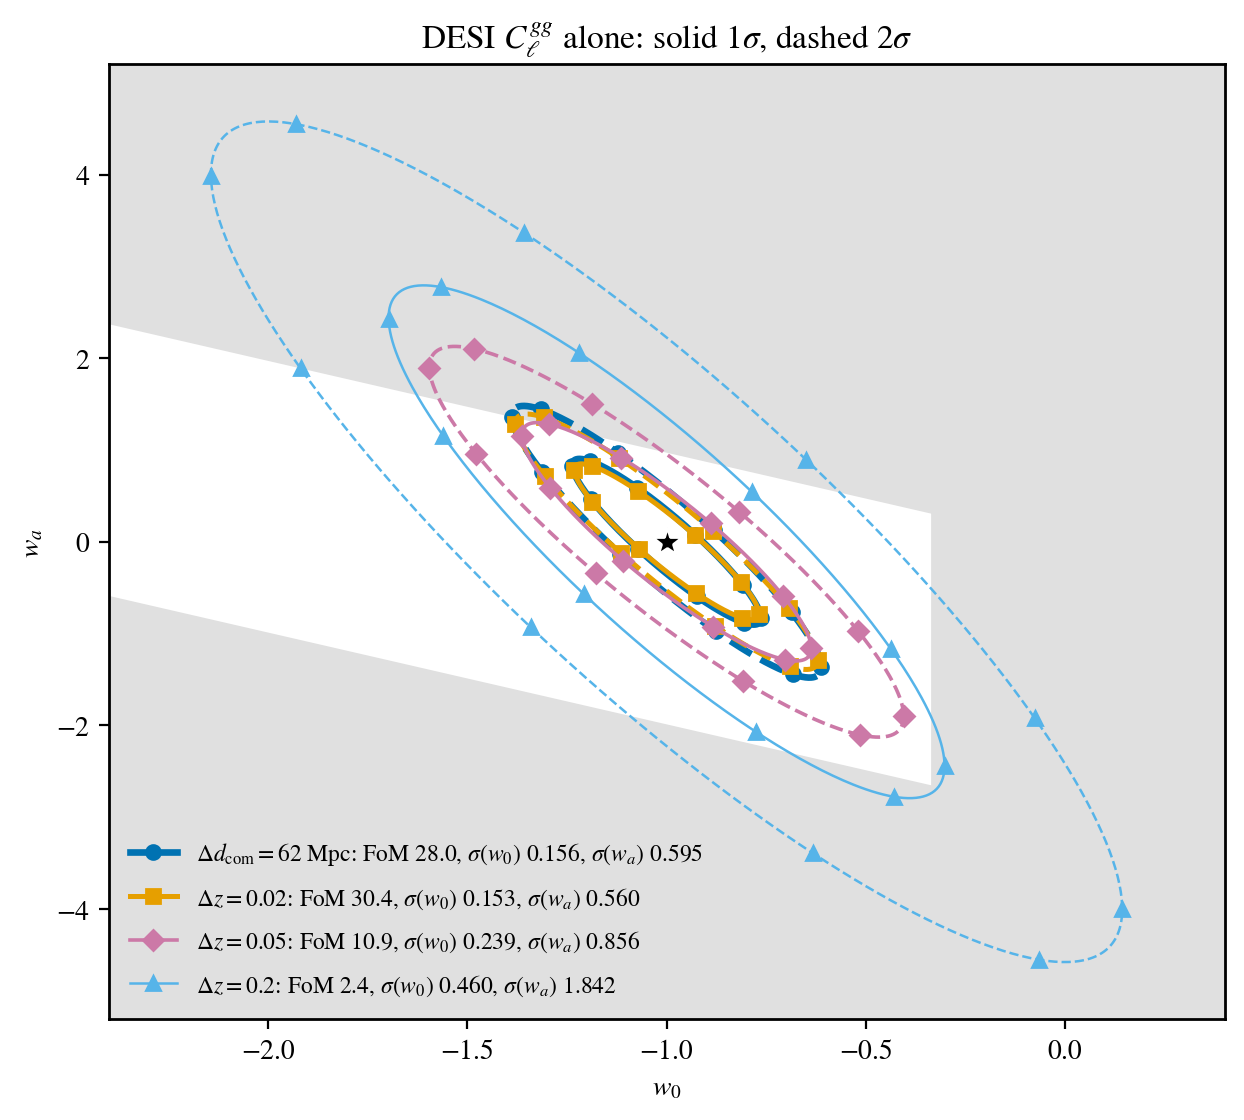

In [46]:
fig, ax = plt.subplots(figsize=(7.2, 6.2))
w0_grid = np.linspace(-2.4, 0.4, 400)
ax.axvspan(-1.0/3.0, 0.4, color='0.88', zorder=0)
ax.fill_between(w0_grid, -0.01 - w0_grid, 5.2, color='0.88', zorder=0)
ax.fill_between(w0_grid, -5.2, -3.0 - w0_grid, color='0.88', zorder=0)
angle = np.linspace(0.0, 2.0*np.pi, 400)
circle = np.vstack([np.cos(angle), np.sin(angle)])
for key in LAYOUT_DATASETS:
    F = np.array(layout_desi[key]['F'][H_MAIN])
    names = list(layout_desi[key]['names'])
    covariance = np.linalg.inv(0.5*(F + F.T))
    rows = [names.index('w0'), names.index('wa')]
    c2 = covariance[np.ix_(rows, rows)]
    center = np.array([fiducial['w0'], fiducial['wa']])
    cholesky = np.linalg.cholesky(c2)
    fom = cosmo_errors(F, names)[1]
    for level, style in ((2.30, '-'), (6.18, '--')):
        contour = center[:, None] + np.sqrt(level)*(cholesky @ circle)
        label = None
        if style == '-':
            label = (f'{LAYOUT_LABELS[key]}: FoM {fom:.1f}, $\\sigma(w_0)$ {np.sqrt(c2[0, 0]):.3f}, '
                     f'$\\sigma(w_a)$ {np.sqrt(c2[1, 1]):.3f}')
        # each layout's width and, every 40th point of the contour, its
        # marker, so the contours read in black and white
        ax.plot(contour[0], contour[1], color=LAYOUT_COLORS[key], ls=style,
                lw=LAYOUT_STYLE[key]['lw'], marker=LAYOUT_STYLE[key]['marker'],
                ms=5, markevery=40, label=label)
ax.plot([fiducial['w0']], [fiducial['wa']], marker='*', color='k', ms=11,
        mec='white', zorder=5)
ax.set_xlim(-2.4, 0.4)
ax.set_ylim(-5.2, 5.2)
ax.set_xlabel(r'$w_0$')
ax.set_ylabel(r'$w_a$')
ax.set_title(r'DESI $C_\ell^{gg}$ alone: solid $1\sigma$, dashed $2\sigma$')
ax.legend(loc='lower left', fontsize=8.5, frameon=False)
plt.show()

## 9. Limits of this forecast

- **The covariance.** Every DESI layout's likelihood covariance is the Gaussian
  term of the project's own covariance code (`covariance/lssty1xdesi_covariance.py`,
  written into `data/` by `scripts/make_desi_covariance.py`); the
  $\Delta d_\mathrm{com} = 62$ Mpc layout uses it too, and the source forecast's
  covariance stays in `data/lssty1xdesi_desi_dr3_sacc_cov`. Its galaxy signal
  uses the likelihood's linear bias, $b_i = B_g/D(\bar z_i)$: the group amplitude
  $B_g$ (`DESI_B1`) divided by the linear growth factor $D$ at the bin's mean
  redshift $\bar z_i$. Two differences from the data vectors remain: the
  covariance leaves out the one-loop terms of the higher-order bias model A
  ([EXAMPLE_EVALUATE_FISHER_MODEL_A.ipynb](EXAMPLE_EVALUATE_FISHER_MODEL_A.ipynb)),
  and it is computed with massless neutrinos, against $\sum m_\nu = 0.06$ eV
  here, which offsets its signal by about 3%.
- **Gaussian covariance only.** Super-sample covariance and the connected trispectrum
  are left out; the shear and galaxy-galaxy lensing signal inside the Gaussian term
  carries NLA with the power law evaluated at each source bin's mean redshift.
- **Independent probes.** The LSST Y1 3x2pt + DESI $C_\ell^{gg}$ sum ignores the
  LSST×DESI cross spectra and the covariance between the two data vectors, although
  the footprints overlap.
- **The bias freedom.** At $k_\mathrm{max} = 0.075\,h$ Mpc$^{-1}$, freeing one
  flat-prior bias per bin instead of one amplitude per group divides the FoM of
  DESI $C_\ell^{gg}$ alone by 2.1 to 5.9 depending on the layout, and the correlated
  prior of section 8 spans the whole range in between as $(L, \sigma_b)$ vary.
  That prior is a single model, a Gaussian on the fractional deviations with the
  exponential kernel $\exp(-|z_i - z_j|/L)$, and the point its figures mark as
  the baseline, $(L, \sigma_b) = (0.05, 3\%)$, is a reference for the scan, not one
  of the stated priors of the ladder (derived in
  `notes/correlated_bias_prior_v2/correlated_bias_prior_v2.pdf`); a thin-bin FoM
  stands only together with the prior that produced it.
  The memory model of the same subsection frees a linear tilt per group next
  to the amplitude, so its residual scatter admits the measured line-like
  drifts at $\sigma_b = 1$-$3\%$ instead of the kernel's 10%, at the price of
  the growth information inside each group.
- **Linear Fisher biases.** Shifts of order one $\sigma$ or more are outside the linear
  regime; a chain fitted to the alternative vector measures them properly.
- **The numerical floor.** With the halofit patch and the DESI $\chi$-grid boost, the
  vectors are smooth to about $10^{-3}\sqrt{\chi^2}$ per evaluation; section 5 shows
  what is left of the step and accuracy dependence.
- **Completed-survey densities.** The DESI galaxy densities (0.62 per arcmin$^2$
  over $f_\mathrm{sky} \approx 0.3$, about 28 million tracers) correspond to the
  completed DESI survey, not to DR1.